```{=latex}
\thispagestyle{empty}
```

# 📘 MicroPython на ESP32 {- .unlisted}
## Курс лекцій для університету {-}

**Від мікроконтролера до інтернету речей: цифрові й аналогові інтерфейси, шини даних, периферія та бездротовий зв'язок**

---
*Навчальний посібник підготовлено як лекційний супровід до лабораторних робіт №1–4 з курсу програмування мікроконтролерів на MicroPython.*

```{=latex}
\clearpage
\pagenumbering{roman}
```

```{=latex}
\pagestyle{fancy}
\fancyhf{}
\renewcommand{\headrulewidth}{0.4pt}
\fancyhead[L]{MicroPython на ESP32}
\fancyhead[R]{Пахалюк Богдан}
\fancyfoot[C]{\thepage}
```


---

## Передмова {-}


Цей посібник — не переклад офіційної документації MicroPython, а самостійний конспект лекцій, побудований на її ідеях і термінології, але викладений послідовно, з власними прикладами, поясненнями «чому так» і питаннями для самоперевірки — у форматі, звичному для університетського підручника.

Матеріал охоплює шлях від першого підключення плати ESP32 до побудови завершеного пристрою, що спілкується з периферією через різні цифрові інтерфейси й виходить у мережу. Кожен розділ:

- починається з переліку цілей навчання;
- містить теоретичні відомості та приклади коду мовою MicroPython;
- завершується блоком питань для самоперевірки.

Практичне закріплення матеріалу відбувається на лабораторних роботах №1–4 («Цифрові GPIO», «ADC та PWM», «Таймери, переривання та UART», «I2C та SPI»), тому в тексті є прямі відсилання до відповідних лабораторних.

**Офіційне джерело для поглибленого вивчення:** документація проєкту MicroPython — [https://docs.micropython.org/en/latest/esp32/](https://docs.micropython.org/en/latest/esp32/) (розділи Tutorial та Quick reference). Цей посібник рекомендується використовувати як вступний і структурований виклад, а офіційну документацію — як довідник з точними сигнатурами функцій, що можуть оновлюватися між версіями прошивки.

---

```{=latex}
\clearpage
\renewcommand{\contentsname}{Зміст}
\setcounter{tocdepth}{1}
\tableofcontents
```

---

```{=latex}
\clearpage
\pagenumbering{arabic}
\setcounter{page}{1}
```

In [1]:
# Google Colab: схеми конспекту будуються бібліотекою schemdraw, якої в Colab немає за замовчуванням
import sys
if "google.colab" in sys.modules:
    %pip install -q schemdraw==0.23

# 📘 Розділ 1. Вступ: мікроконтролери, ESP32 та MicroPython

### Після опрацювання розділу ви зможете: {-}
- пояснити різницю між мікроконтролером і мікрокомп'ютером (наприклад, Raspberry Pi)
- описати ключові апаратні блоки ESP32
- порівняти MicroPython зі стандартним CPython
- прошити плату та підключитись до неї через послідовний термінал
- оцінити орієнтовний час роботи пристрою від батареї


### 1.1. Мікроконтролер проти мікрокомп'ютера {-}

Мікроконтролер — це маленький комп'ютер на одному кристалі: процесорне ядро, оперативна пам'ять, постійна пам'ять для програми та набір периферійних блоків (таймери, АЦП, інтерфейси зв'язку) уже інтегровані в одну мікросхему. На відміну від мікрокомп'ютера (Raspberry Pi, звичайний ноутбук), мікроконтролер зазвичай:

- не має операційної системи загального призначення (Linux/Windows) — програма виконується «на голому залізі» (bare metal) або під тонкою прошивкою;
- має набагато менше пам'яті (сотні кілобайтів — одиниці мегабайтів, а не гігабайти);
- вмикається миттєво (немає завантаження ОС) і споживає значно менше енергії;
- призначений для керування конкретним обладнанням — датчиками, моторами, дисплеями — а не для запуску універсальних застосунків.

Тому мікроконтролери домінують у вбудованих системах (embedded systems): побутовій техніці, автомобільній електроніці, промисловій автоматизації та пристроях інтернету речей (IoT).


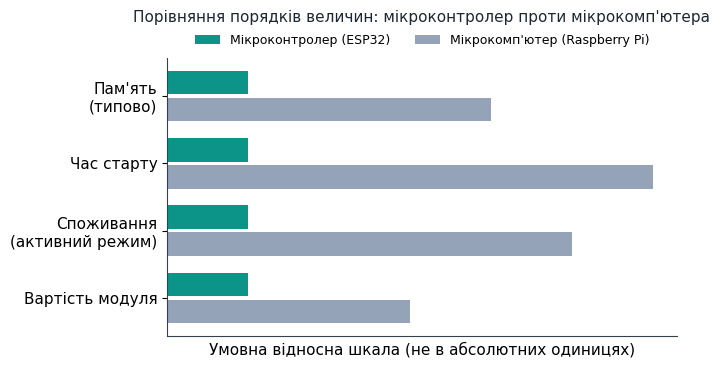

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, ax = plt.subplots(figsize=(7, 3.8))
categories = ["Вартість модуля", "Споживання\n(активний режим)", "Час старту", "Пам'ять\n(типово)"]
mcu_vals = [1, 1, 1, 1]
mpu_vals = [3, 5, 6, 4]
y = np.arange(len(categories))
ax.barh(y + 0.2, mcu_vals, height=0.35, color=ACCENT, label="Мікроконтролер (ESP32)")
ax.barh(y - 0.2, mpu_vals, height=0.35, color="#94A3B8", label="Мікрокомп'ютер (Raspberry Pi)")
ax.set_yticks(y)
ax.set_yticklabels(categories)
ax.set_xticks([])
ax.set_xlabel("Умовна відносна шкала (не в абсолютних одиницях)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=9, frameon=False)
ax.set_title("Порівняння порядків величин: мікроконтролер проти мікрокомп'ютера", fontsize=11, color=TEXT, pad=26)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

*Рисунок 1.1. Схематичне (не в абсолютних одиницях) порівняння порядків величин між мікроконтролером і мікрокомп'ютером за кількома практичними критеріями.*


### 1.2. Апаратна архітектура ESP32 {-}

ESP32 — сімейство мікроконтролерів компанії Espressif. Класична модель (ESP32-WROOM-32) містить:

| Блок | Характеристика |
|---|---|
| Процесор | Два ядра Xtensa LX6, тактова частота до 240 МГц |
| Оперативна пам'ять (RAM) | ~520 КБ SRAM |
| Постійна пам'ять | Зовнішня flash-пам'ять (типово 4 МБ), де зберігається прошивка й файлова система |
| Бездротові модулі | Wi-Fi 802.11 b/g/n, Bluetooth Classic + BLE |
| Піни загального призначення | ~34 GPIO-піни (частина зарезервована або має обмеження) |
| Периферія | АЦП (ADC), ЦАП (DAC), ШІМ (PWM), UART, I2C, SPI, I2S, дотикові сенсори, лічильник імпульсів, RTC-модуль |

Наявність двох ядер і апаратних периферійних блоків дозволяє мікроконтролеру виконувати задачі реального часу (наприклад, генерувати точний ШІМ-сигнал), поки основна програма займається іншою логікою.


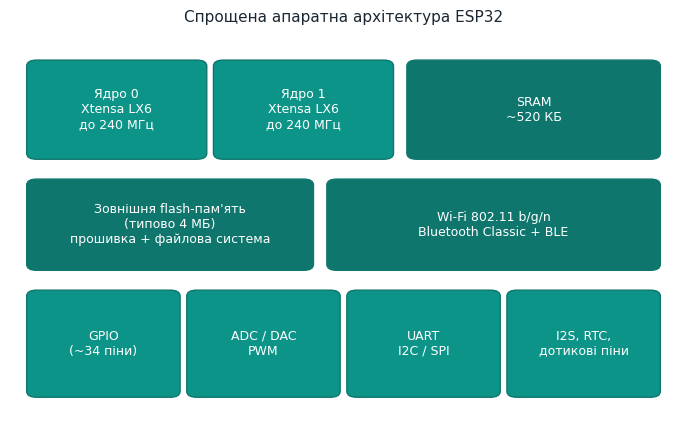

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _block(ax, x, y, w, h, text, color=ACCENT, tcolor="white", fs=9):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                     linewidth=1, edgecolor=ACCENT_DARK, facecolor=color)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=tcolor, wrap=True)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
_block(ax, 0.3, 6.8, 2.6, 2.4, "Ядро 0\nXtensa LX6\nдо 240 МГц")
_block(ax, 3.1, 6.8, 2.6, 2.4, "Ядро 1\nXtensa LX6\nдо 240 МГц")
_block(ax, 6.0, 6.8, 3.7, 2.4, "SRAM\n~520 КБ", color=ACCENT_DARK)
_block(ax, 0.3, 4.0, 4.2, 2.2, "Зовнішня flash-пам'ять\n(типово 4 МБ)\nпрошивка + файлова система", color=ACCENT_DARK)
_block(ax, 4.8, 4.0, 4.9, 2.2, "Wi-Fi 802.11 b/g/n\nBluetooth Classic + BLE", color=ACCENT_DARK)
_block(ax, 0.3, 0.8, 2.2, 2.6, "GPIO\n(~34 піни)")
_block(ax, 2.7, 0.8, 2.2, 2.6, "ADC / DAC\nPWM")
_block(ax, 5.1, 0.8, 2.2, 2.6, "UART\nI2C / SPI")
_block(ax, 7.5, 0.8, 2.2, 2.6, "I2S, RTC,\nдотикові піни")
ax.set_title("Спрощена апаратна архітектура ESP32", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()


*Рисунок 1.2. Спрощений блок-склад ESP32: два обчислювальні ядра, спільна оперативна пам'ять, зовнішня flash-пам'ять, бездротові модулі та периферія, згруповані за призначенням.*


### 1.3. Що таке MicroPython {-}

**MicroPython** — це реалізація мови Python 3, спроєктована так, щоб працювати в умовах обмежених ресурсів мікроконтролера. Вона включає компактний компілятор-у-байткод і інтерпретатор, а також переосмислену стандартну бібліотеку.

Головні відмінності від «звичайного» CPython, який використовується на комп'ютері:

| Аспект | CPython (комп'ютер) | MicroPython (мікроконтролер) |
|---|---|---|
| Середовище виконання | Операційна система (Windows/Linux/macOS) | Виконується напряму на мікроконтролері, без ОС |
| Стандартна бібліотека | Повна (`os`, `sys`, `json`, ...) | Урізана й спеціалізована версія (`uos`, `usys`, `ujson`, ...; префікс `u` у старих версіях, зараз модулі часто доступні і без нього) |
| Апаратний доступ | Немає прямого доступу до пінів | Є спеціальний модуль `machine` для роботи з GPIO, ADC, PWM, I2C, SPI тощо |
| Пам'ять | Гігабайти | Сотні кілобайтів — важливо економити пам'ять (уникати зайвих об'єктів у циклах) |
| Файлова система | Файлова система ОС | Власна файлова система на flash-пам'яті самої плати (`main.py`, `boot.py` та інші файли) |

Для нашого курсу ключовий модуль — **`machine`**: саме через нього ми звертаємось до апаратних можливостей плати (піни, шини, таймери).


### 1.4. Вимоги та живлення плати {-}

Для роботи знадобляться:

- плата на базі ESP32 (наприклад, DevKit-C, NodeMCU-32S);
- USB-кабель з підтримкою передачі даних (не лише живлення);
- комп'ютер з встановленим драйвером USB-UART мосту (найчастіше CP2102 або CH340 — залежно від виробника плати);
- середовище для роботи з платою: Thonny, `mpremote`/`ampy`, Jupyter з `jupyter_micropython_kernel`, або онлайн-симулятор Wokwi (без фізичної плати).

**Живлення.** У більшості випадків достатньо живлення від USB-порту комп'ютера (5 В). Але якщо до плати підключено енергоємну периферію (сервоприводи, дисплеї, кілька світлодіодних стрічок), струму з USB-порту може не вистачити — це проявляється як спонтанні перезавантаження (brownout reset) або нестабільна робота Wi-Fi. У такому разі використовують зовнішній стабілізований блок живлення 5 В або окреме джерело для навантаження, лишаючи USB тільки для зв'язку з платою.


### 1.5. Прошивка та її встановлення {-}

Прошивка MicroPython для ESP32 — це файл `.bin`, який завантажують з офіційного сайту проєкту (для сімейства плат ESP32 обирають варіант, що відповідає конкретному чипу: класичний ESP32, ESP32-S2, ESP32-S3, ESP32-C3 тощо — вони несумісні між собою на рівні прошивки).

Типовий процес встановлення через утиліту `esptool.py`:
```bash
pip install esptool

# 1. Повністю стерти попередній вміст flash-пам'яті
esptool.py --port COM5 erase_flash

# 2. Записати нову прошивку MicroPython, починаючи з адреси 0x1000
esptool.py --port COM5 --baud 460800 write_flash -z 0x1000 esp32-firmware.bin
```
Порт (`COM5`, або `/dev/ttyUSB0` в Linux) визначають у диспетчері пристроїв / командою `ls /dev/tty*`. Після прошивки плата перезавантажується й одразу готова до роботи — файлова система вже містить порожні `boot.py`/`main.py`.


### 1.6. Типові проблеми при встановленні {-}

- **Порт не знайдено або зайнятий** — перевірте, чи не відкритий той самий порт у Serial Monitor іншої програми (Arduino IDE, Thonny), закрийте зайві з'єднання.
- **Плата не переходить у режим завантаження** — деякі плати вимагають утримувати кнопку `BOOT` під час подачі команди `write_flash`; на платах з автоматичним переходом у режим завантаження (auto-reset) це не потрібно.
- **Помилка `Timed out waiting for packet header`** — зазвичай означає, що плата не в режимі завантаження, або обрана надто висока швидкість (`--baud`) — спробуйте зменшити до `115200`.
- **Не встановлений драйвер USB-UART** — плата взагалі не з'являється в системі як порт; потрібно встановити драйвер CP210x або CH340 залежно від чипа на платі.
- **Brownout / спонтанні перезавантаження одразу після прошивки** — як правило, проблема живлення (недостатній струм від USB-порту чи кабелю), а не самої прошивки.


### 1.7. Послідовний термінал і REPL {-}

**REPL (Read-Eval-Print Loop)** — інтерактивна консоль плати: ви вводите вираз Python, плата одразу його виконує й повертає результат. Це найзручніший спосіб швидко перевірити ідею без запису файлу.

Підключення до REPL відбувається через послідовний порт (той самий USB), звичайним термінальним застосунком (наприклад, `screen /dev/ttyUSB0 115200` у Linux/macOS, або вбудований термінал Thonny у Windows) чи через Jupyter-ядро для MicroPython.

Корисні комбінації клавіш у REPL:
| Комбінація | Дія |
|---|---|
| `Ctrl-C` | перервати виконання поточної програми (наприклад, нескінченний цикл) |
| `Ctrl-D` | «м'яке» перезавантаження (soft reset) — плата перезапускає інтерпретатор і виконує `boot.py`/`main.py` заново, без повторної прошивки |
| `Ctrl-E` | увійти в **paste mode** — режим вставки багаторядкового коду без автоматичних відступів, зручний для копіювання готових фрагментів |
| `Ctrl-A` | перейти у **raw REPL** — машинний режим без інтерактивного форматування, використовується інструментами (`mpremote`, `ampy`) для програмної передачі файлів |

Файл **`boot.py`** виконується один раз при кожному старті плати (до `main.py`) і зазвичай містить налаштування низького рівня (наприклад підключення до Wi-Fi). Файл **`main.py`** — основна програма, яка запускається після нього й зазвичай містить нескінченний робочий цикл вашого пристрою.


### 1.8. Порівняння поширених плат на базі ESP32 {-}

На практиці «ESP32» — це не одна плата, а ціле сімейство модулів і макетних плат розробника (devkit), що відрізняються розміром, кількістю виведених пінів і додатковими можливостями:

| Плата | Чип | Особливості |
|---|---|---|
| ESP32 DevKit-C | ESP32 (класичний) | Найпоширеніша навчальна плата, ~30 виведених пінів, USB-UART міст CP2102 |
| NodeMCU-32S | ESP32 (класичний) | Схожа на DevKit-C, трохи інша розкладка пінів і ширина плати |
| Wemos/Lolin32 | ESP32 (класичний) | Компактніша, менше виведених пінів, часто дешевша |
| ESP32-S2 | ESP32-S2 | Одне ядро, вбудований USB (без окремого USB-UART моста), без Bluetooth |
| ESP32-S3 | ESP32-S3 | Два ядра, вбудований USB, підтримка простих нейромережевих обчислень (AI-акселератор), Bluetooth LE |
| ESP32-C3 | ESP32-C3 | Одне ядро RISC-V (не Xtensa!), менше пінів, дешевший, Bluetooth LE |

**Важливий наслідок для практики:** прошивки MicroPython для цих чипів **несумісні між собою** — при завантаженні з офіційного сайту завжди потрібно обирати варіант, що відповідає точній моделі чипа на вашій платі (написана зазвичай прямо на мікросхемі під металевим екраном модуля).


### 1.9. Практичний приклад: перший діалог з платою через REPL {-}

Розглянемо покроково, що відбувається при першому підключенні до щойно прошитої плати. Після виконання `%serialconnect` (Jupyter) або відкриття термінала (Thonny) ви побачите запрошення `>>>` — це і є REPL. Спробуємо кілька команд:

```python
>>> print("Перевірка зв'язку")
Перевірка зв'язку

>>> import sys
>>> sys.platform
'esp32'

>>> import machine
>>> machine.freq()
240000000

>>> 2 ** 10
1024
```

Кожен рядок, введений після `>>>`, виконується миттєво — REPL нічого не запам'ятовує «для потім», окрім змінних, створених у цій самій сесії. Якщо ввести багаторядкову конструкцію (наприклад, `for`), запрошення зміниться на `...` для продовження блоку:

```python
>>> for i in range(3):
...     print("Світлодіод, спалах №", i)
...
Світлодіод, спалах № 0
Світлодіод, спалах № 1
Світлодіод, спалах № 2
```

Порожній рядок (`Enter` на порожньому `...`) завершує блок і виконує його. Це і є найшвидший спосіб перевірити ідею, перш ніж записувати її у `main.py`.


### 1.10. Практичний приклад: орієнтовна оцінка часу роботи від батареї {-}

Перед тим як проєктувати автономний пристрій, корисно прикинути «на пальцях», скільки він протягне від батареї — задовго до того, як ми детально розглянемо режими сну (Розділ 4.4). Достатньо грубої моделі: середній струм споживання й ємність батареї.

Орієнтовні (типові, залежать від конкретної плати, периферії й прошивки) значення струму споживання ESP32:

| Режим | Орієнтовний струм |
|---|---|
| Активна робота з увімкненим Wi-Fi | ~80–160 мА (з короткими піками під час передачі) |
| Активна робота без Wi-Fi/Bluetooth | ~20–40 мА |
| Deep sleep | ~0.01 мА (~10 мкА) |

Припустимо, пристрій живиться від Li-ion акумулятора ємністю 2000 мА·год і 95% часу проводить у deep sleep, прокидаючись раз на хвилину на ~2 секунди для вимірювання й передачі даних по Wi-Fi:

```python
CAPACITY_MAH = 2000
ACTIVE_CURRENT_MA = 120       # активна робота з Wi-Fi
SLEEP_CURRENT_MA = 0.01        # deep sleep
ACTIVE_S_PER_CYCLE = 2
CYCLE_PERIOD_S = 60

sleep_s_per_cycle = CYCLE_PERIOD_S - ACTIVE_S_PER_CYCLE
avg_current_ma = (
    ACTIVE_CURRENT_MA * ACTIVE_S_PER_CYCLE + SLEEP_CURRENT_MA * sleep_s_per_cycle
) / CYCLE_PERIOD_S

runtime_hours = CAPACITY_MAH / avg_current_ma
print(f"Середній струм: {avg_current_ma:.2f} мА")
print(f"Орієнтовний час роботи: {runtime_hours:.0f} год (~{runtime_hours/24:.1f} діб)")
```

Середній струм тут виходить приблизно 4 мА — і саме тому deep sleep настільки важливий для автономних пристроїв: навіть коротка активна фаза раз на хвилину «важить» у сумарному балансі значно більше, ніж увесь інший час у сні. Це орієнтовна оцінка «зверху вниз», яка не враховує саморозряд батареї й падіння її ємності при низькій температурі, але добре підходить для першого наближення ще на етапі проєктування.


### 1.11. Типові помилки початківців {-}

| Помилка | Чому це проблема |
|---|---|
| Використання піна лише для входу (наприклад `GPIO34`) як виходу | Такі піни фізично не мають вихідного драйвера — код виконається без помилки, але сигнал на пін не подасться (докладніше в Розділі 3.1) |
| Живлення сервоприводів чи потужних LED-стрічок напряму від USB-порту | Недостатній струм спричиняє brownout-перезавантаження або нестабільний Wi-Fi (Розділ 1.4) |
| Очікування, що `machine.freq()` зберігається між перезавантаженнями | Зміна частоти діє лише до наступного `reset()`/`deepsleep()` — після перезапуску відновлюється значення за замовчуванням |
| Сприйняття файлової системи плати як «диска» на комп'ютері | Це окрема, невелика файлова система на flash-пам'яті самого чипа (Розділ 2.2), а не мережевий диск чи флешка |
| Завантаження прошивки не для тієї моделі чипа | ESP32, ESP32-S2/S3, ESP32-C3 мають несумісні прошивки (Розділ 1.8) — плата може взагалі не запуститись |
| Ігнорування повідомлень про brownout у консолі | Це майже завжди симптом проблеми з живленням, а не випадковий збій програми |



### 1.12. Місце ESP32 серед мікроконтролерів Espressif {-}

ESP32 — не перший і не останній чип виробника. Його попередник, **ESP8266**, має лише одне ядро, не підтримує Bluetooth і має менше GPIO-пінів, зате дешевший — досі трапляється в найпростіших проєктах, де достатньо Wi-Fi без інших вимог. У новіших лініях Espressif частина чипів (наприклад, серія C: ESP32-C3, ESP32-C6) перейшла на архітектуру **RISC-V** замість власницької Xtensa, тоді як старші й потужніші моделі (ESP32-S2, ESP32-S3) залишаються на Xtensa. Для курсу це означає: код на рівні MicroPython (`machine`, `time`, ...) переноситься між цими чипами майже без змін, а от прошивку й деякі низькорівневі деталі (кількість ядер, наявність Bluetooth) завжди потрібно звіряти з конкретною моделлю.


### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Назвіть три відмінності мікроконтролера від мікрокомп'ютера (наприклад, Raspberry Pi).</summary>

> **Відповідь:** Оберіть будь-які три з переліку розділу 1.1: відсутність операційної системи загального призначення (код виконується «на голому залізі»); значно менше пам'яті (сотні кілобайтів — одиниці мегабайтів, а не гігабайти); миттєве увімкнення і значно нижче енергоспоживання (немає завантаження ОС); призначеність для керування конкретним обладнанням, а не для запуску універсальних застосунків.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Які апаратні блоки входять до складу ESP32 і за що кожен із них відповідає?</summary>

> **Відповідь:** Два ядра Xtensa LX6 (до 240 МГц) — обчислення; ~520 КБ SRAM — оперативна пам'ять; зовнішня flash-пам'ять (типово 4 МБ) — прошивка й файлова система; Wi-Fi 802.11 b/g/n та Bluetooth Classic/BLE — бездротовий зв'язок; ~34 GPIO-піни; периферія ADC, DAC, PWM, UART, I2C, SPI, I2S, дотикові сенсори, лічильник імпульсів, RTC.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чим стандартна бібліотека MicroPython відрізняється від стандартної бібліотеки CPython і чому це виправдано?</summary>

> **Відповідь:** Це урізана й спеціалізована версія (`uos`, `usys`, `ujson` — префікс `u` у старих версіях), а не повна бібліотека CPython. Виправдано обмеженими ресурсами мікроконтролера: сотні кілобайтів пам'яті замість гігабайтів на комп'ютері.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Через який модуль MicroPython надає доступ до апаратних можливостей плати?</summary>

> **Відповідь:** Через модуль `machine` — саме через нього виконується робота з пінами, шинами, таймерами тощо.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому живлення від USB-порту може бути недостатнім для деяких проєктів на ESP32? Наведіть приклад симптому.</summary>

> **Відповідь:** Енергоємна периферія (сервоприводи, дисплеї, кілька світлодіодних стрічок) може вимагати струму більше, ніж здатен дати USB-порт. Симптом: спонтанні перезавантаження (brownout reset) або нестабільна робота Wi-Fi.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Опишіть послідовність команд для прошивки чистої плати ESP32 утилітою esptool.py.</summary>

> **Відповідь:** `pip install esptool`, потім `esptool.py --port COM5 erase_flash` (стерти попередній вміст), потім `esptool.py --port COM5 --baud 460800 write_flash -z 0x1000 esp32-firmware.bin` (записати нову прошивку з адреси 0x1000).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Що робити, якщо esptool.py видає помилку «Timed out waiting for packet header»?</summary>

> **Відповідь:** Зазвичай означає, що плата не в режимі завантаження (можливо, потрібно утримати кнопку `BOOT`), або обрана надто висока швидкість — варто спробувати зменшити `--baud` до 115200.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Що таке REPL і чим він відрізняється від запуску файлу `main.py`?</summary>

> **Відповідь:** REPL (Read-Eval-Print Loop) — інтерактивна консоль: кожен введений вираз виконується миттєво, і плата одразу повертає результат, нічого «не пам'ятаючи» окрім змінних поточної сесії. На відміну від цього, `main.py` — файл з повною програмою, яка виконується автоматично при старті плати.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> У чому різниця між `Ctrl-C` та `Ctrl-D` у консолі REPL?</summary>

> **Відповідь:** `Ctrl-C` перериває виконання поточної програми (наприклад, нескінченний цикл), а `Ctrl-D` виконує «м'яке» перезавантаження — перезапускає інтерпретатор і заново виконує `boot.py`/`main.py`, без повторної прошивки.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 10.</b> Яку роль виконує файл `boot.py`, а яку — `main.py`? У якому порядку вони виконуються при старті плати?</summary>

> **Відповідь:** `boot.py` виконується один раз при кожному старті плати (першим) і зазвичай містить налаштування низького рівня (наприклад, підключення до Wi-Fi); `main.py` — основна програма з робочим циклом пристрою, яка запускається після нього.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 11.</b> Чому короткочасна активна фаза (кілька секунд раз на хвилину) може «важити» в енергобалансі пристрою більше, ніж уся решта часу в deep sleep?</summary>

> **Відповідь:** Бо струм в активному режимі (десятки-сотні мА) на кілька порядків більший за струм у deep sleep (одиниці — десятки мкА). Навіть кілька секунд активної роботи можуть споживати заряду більше, ніж хвилини чи години сну, тому середній струм системи визначається переважно тривалістю й частотою активних фаз.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 12.</b> Чим ESP32-C3 архітектурно відрізняється від класичного ESP32 та ESP32-S3?</summary>

> **Відповідь:** ESP32-C3 використовує одне ядро архітектури RISC-V, тоді як класичний ESP32 і ESP32-S3 мають два ядра архітектури Xtensa. На рівні коду MicroPython різниця майже непомітна, але прошивки й деякі низькорівневі деталі несумісні між чипами.

</details>


```{=latex}
\end{selfcheckbox}
```

# 📘 Розділ 2. Керування платою та файлова система

### Після опрацювання розділу ви зможете: {-}
- використовувати модуль machine для інформації про плату та її перезавантаження
- орієнтуватись у файловій системі плати та модулях os/sys
- пояснити різницю між жорстким та м'яким перезавантаженням
- обрати відповідний інструмент для копіювання файлів на плату
- писати у файл на платі безпечніше та контролювати вільне місце


Перш ніж заглибитись у деталі, узагальнимо малюнком послідовність запуску плати, яку ми вже частково зустрічали в Розділі 1.7.


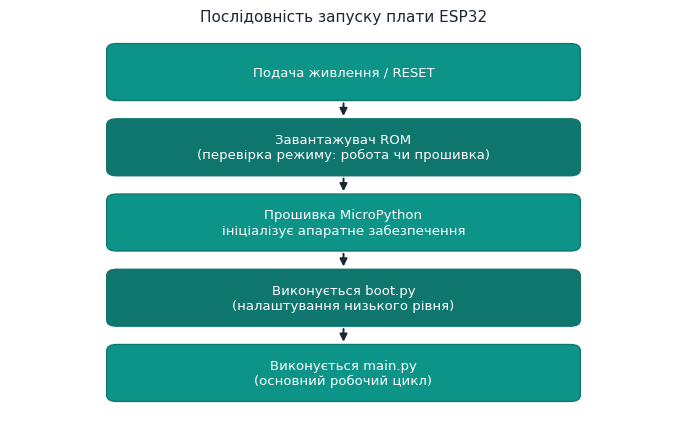

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _block(ax, x, y, w, h, text, color=ACCENT, tcolor="white", fs=9):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                   linewidth=1, edgecolor=ACCENT_DARK, facecolor=color)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=tcolor)

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
steps = [
    "Подача живлення / RESET",
    "Завантажувач ROM\n(перевірка режиму: робота чи прошивка)",
    "Прошивка MicroPython\nініціалізує апаратне забезпечення",
    "Виконується boot.py\n(налаштування низького рівня)",
    "Виконується main.py\n(основний робочий цикл)",
]
h, gap, top = 1.3, 0.55, 9.6
for i, text in enumerate(steps):
    y = top - h - i * (h + gap)
    color = ACCENT if i % 2 == 0 else ACCENT_DARK
    _block(ax, 1.5, y, 7.0, h, text, color=color, fs=9.5)
    if i < len(steps) - 1:
        # стрілка вниз: від нижнього краю цього блока до верхнього краю наступного
        ax.annotate("", xy=(5.0, y - gap + 0.05), xytext=(5.0, y - 0.05),
                    arrowprops=dict(arrowstyle="-|>", color=TEXT, lw=1.4))
ax.set_title("Послідовність запуску плати ESP32", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

*Рисунок 2.1. Кожен крок запуску виконується один раз послідовно; `boot.py` і `main.py` — єдині два файли користувача, що запускаються автоматично, без явного виклику.*


### 2.1. Інформація про плату та її перезавантаження {-}

Модуль `machine` містить не лише класи для роботи з периферією, а й службові функції рівня всієї плати:
```python
import machine

print(machine.unique_id())    # унікальний ідентифікатор чипа (bytes) — корисно для MAC-подібних адрес
print(machine.freq())         # поточна тактова частота процесора, Гц
machine.freq(160000000)       # знизити частоту до 160 МГц — економія енергії

machine.reset()                # апаратне перезавантаження, еквівалент натискання кнопки RESET
machine.reset_cause()          # причина останнього старту: PWRON_RESET, DEEPSLEEP_RESET тощо
```
Зниження `freq()` корисне в батарейних проєктах: менша частота — менше споживання, але й повільніші обчислення.


### 2.2. Файлова система плати {-}

ESP32 з MicroPython тримає невелику файлову систему на flash-пам'яті (зазвичай FAT або littlefs, залежно від версії прошивки). Працювати з нею можна тими самими засобами Python, що й зі звичайними файлами:
```python
import os

print(os.listdir())           # список файлів у поточному каталозі плати
os.mkdir("data")               # створити каталог

with open("data/log.txt", "w") as f:
    f.write("Перший запуск\n")

with open("data/log.txt", "r") as f:
    print(f.read())

os.remove("data/log.txt")      # видалити файл
```
Модуль `sys` надає доступ до системних параметрів середовища виконання:
```python
import sys

print(sys.version)             # версія MicroPython
print(sys.platform)            # назва платформи, напр. 'esp32'
print(sys.implementation)      # деталі реалізації інтерпретатора
```
**Важливо:** в об'ємі flash-пам'яті плати одночасно зберігаються і сама прошивка MicroPython, і файли користувача — тому файлова система невелика (зазвичай одиниці мегабайтів), і зберігати варто лише компактні дані (конфігурацію, короткі логи), а не великі масиви — для цього краще підходить SD-картка (Розділ 12).


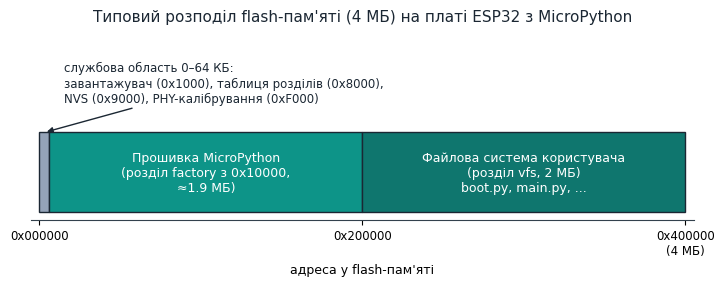

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

# Типова таблиця розділів MicroPython для ESP32 з flash 4 МБ (адреси в байтах)
MB = 1024 * 1024
parts = [
    (0x0000,   0x10000,  "#94A3B8", "службові"),
    (0x10000,  0x200000, ACCENT,    "Прошивка MicroPython\n(розділ factory з 0x10000,\n≈1.9 МБ)"),
    (0x200000, 0x400000, ACCENT_DARK, "Файлова система користувача\n(розділ vfs, 2 МБ)\nboot.py, main.py, ..."),
]
fig, ax = plt.subplots(figsize=(7.4, 3.0))
for start, end, color, text in parts:
    ax.add_patch(mpatches.Rectangle((start / MB, 0), (end - start) / MB, 1, facecolor=color, edgecolor=TEXT, lw=1))
    if text != "службові":
        ax.text((start + end) / 2 / MB, 0.5, text, ha="center", va="center", fontsize=9, color="white")
ax.annotate("службова область 0–64 КБ:\nзавантажувач (0x1000), таблиця розділів (0x8000),\nNVS (0x9000), PHY-калібрування (0xF000)",
            xy=(0.03, 1.0), xytext=(0.15, 1.35), fontsize=8.5, color=TEXT, va="bottom",
            arrowprops=dict(arrowstyle="-|>", color=TEXT, lw=1))
ticks = [0, 0x200000, 0x400000]
ax.set_xticks([t / MB for t in ticks])
ax.set_xticklabels(["0x000000", "0x200000", "0x400000\n(4 МБ)"], fontsize=8.5)
ax.set_xlim(-0.05, 4.05); ax.set_ylim(-0.1, 2.3)
ax.set_yticks([])
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.set_xlabel("адреса у flash-пам'яті", fontsize=9)
ax.set_title("Типовий розподіл flash-пам'яті (4 МБ) на платі ESP32 з MicroPython", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

*Рисунок 2.2. Прошивка й файлова система користувача ділять один і той самий фізичний чип flash-пам'яті — саме тому обсяг, доступний під файли користувача, менший за повний розмір мікросхеми. Адреси відповідають стандартній таблиці розділів MicroPython для плат з 4 МБ flash.*


### 2.3. Способи копіювання файлів на плату {-}

Оскільки плата не підключається як звичайний USB-накопичувач, для запису `main.py` та інших файлів на неї потрібен спеціальний інструмент:

| Інструмент | Особливості |
|---|---|
| **Thonny IDE** | Графічний редактор із вбудованою файловою панеллю плати — перетягнути файл або зберегти прямо «на пристрій» |
| **`mpremote`** | Сучасна офіційна консольна утиліта: `mpremote cp main.py :main.py`, `mpremote run script.py`, доступ до REPL |
| **`ampy`** | Простий інструмент попереднього покоління: `ampy --port COM5 put main.py` |
| **`rshell`** | Дозволяє працювати з файловою системою плати як з диском у командному рядку |
| **Jupyter + `jupyter_micropython_kernel`** | Магічна команда `%sendtofile main.py` записує вміст комірки у файл на платі |
| **WebREPL** | Копіювання файлів через Wi-Fi без USB-кабелю (Розділ 14) |
| **Wokwi** | Файл `main.py` редагується прямо у вебредакторі проєкту — окремого копіювання не потрібно |


### 2.4. Жорстке й м'яке перезавантаження {-}

- **Жорстке (hard) перезавантаження** — `machine.reset()` або натискання апаратної кнопки RESET: повністю перезапускає чип, як після подачі живлення.
- **М'яке (soft) перезавантаження** — комбінація `Ctrl-D` у REPL: перезапускає лише інтерпретатор Python (звільняє всі змінні й зупиняє програми), але не сам чип; після нього автоматично виконуються `boot.py` і `main.py`, так само, як після `reset()`.

Різниця стає важливою при налагодженні: якщо програма «зависла» через некоректне переривання чи блокування шини, іноді допомагає лише жорстке перезавантаження.


### 2.5. Знос flash-пам'яті та wear leveling {-}

Flash-пам'ять фізично витримує обмежену кількість циклів перезапису одного й того самого блока (типово від десятків тисяч до кількох сотень тисяч циклів, залежно від технології мікросхеми). Файлова система MicroPython (littlefs у сучасних збірках) реалізує **wear leveling** — розподіляє записи рівномірно по всій доступній області пам'яті, а не завжди в одне й те саме фізичне місце, що суттєво продовжує термін служби модуля.

**Практичний наслідок:** не варто писати у файл на платі щосекунди роками поспіль без потреби (наприклад, зберігати кожне окреме вимірювання датчика в окремому файлі) — краще накопичувати дані в оперативній пам'яті (список, буфер) і записувати їх на flash пачками, рідше.


### 2.6. Практичний приклад: проста система конфігурації {-}

Замість того, щоб «зашивати» параметри (Wi-Fi пароль, адресу сервера, інтервал вимірювань) прямо в код `main.py`, зручніше зберігати їх в окремому файлі конфігурації — це дозволяє змінювати налаштування без редагування самого коду програми:

```python
# config.py — зберігається окремим файлом на платі
CONFIG = {
    "device_name": "esp32-lab-01",
    "measure_interval_s": 5,
    "wifi_ssid": "MyWiFi",
}
```

```python
# main.py
try:
    from config import CONFIG
except ImportError:
    CONFIG = {"device_name": "esp32-unknown", "measure_interval_s": 10, "wifi_ssid": ""}
    print("Файл config.py не знайдено — використано значення за замовчуванням")

print("Ім'я пристрою:", CONFIG["device_name"])
```

Такий підхід («є конфігурація — використай її, немає — розумні значення за замовчуванням») робить код стійкішим до людських помилок і зручним для тиражування на кілька однакових пристроїв — досить скопіювати інший `config.py`, не чіпаючи `main.py`.


### 2.7. Безпечніше оновлення файлу: запис-через-тимчасовий-файл {-}

Що станеться, якщо живлення пропаде посеред запису у `config.py`? У гіршому разі файл залишиться частково записаним і пошкодженим, а наступний запуск програми впаде на `ImportError` чи ще гірше — на помилку синтаксису при спробі його прочитати. Простий і поширений прийом зменшення цього ризику — писати у **тимчасовий файл**, і лише після успішного завершення запису атомарно перейменовувати його на місце оригіналу:

```python
import os
import ujson as json

def save_config_safely(config: dict, path="config.json"):
    tmp_path = path + ".tmp"
    with open(tmp_path, "w") as f:
        json.dump(config, f)
    os.rename(tmp_path, path)   # заміна відбувається одним кроком
```

Якщо живлення пропаде під час запису `tmp_path`, оригінальний `config.json` залишиться неушкодженим — `os.rename()` виконується вже після того, як новий вміст повністю записано. Це не дає стовідсоткової гарантії на рівні самої мікросхеми flash при будь-якому збої, але суттєво знижує ризик порівняно з прямим перезаписом файлу «на місці».


### 2.8. Обмеження розміру логів на платі {-}

З огляду на невеликий об'єм файлової системи (Розділ 2.2) і знос flash-пам'яті (Розділ 2.5), лог, що росте необмежено, рано чи пізно вичерпає вільне місце. Простий підхід — тримати лог фіксованого розміру, зберігаючи лише останні N рядків:

```python
MAX_LINES = 200

def append_log(path, message):
    try:
        with open(path, "r") as f:
            lines = f.readlines()
    except OSError:
        lines = []
    lines.append(message + "\n")
    lines = lines[-MAX_LINES:]   # лишаємо тільки останні MAX_LINES рядків
    with open(path, "w") as f:
        f.writelines(lines)
```

Це не найефективніший підхід (кожен виклик перечитує весь файл), але для логів у кілька сотень рядків на невеликій платі його простоти цілком достатньо; для інтенсивнішого логування варто накопичувати повідомлення в оперативній пам'яті й скидати їх на flash пачками (той самий принцип, що й у Розділі 2.5).


### 2.9. Контроль вільного місця через os.statvfs() {-}

Залежно від порту MicroPython, модуль `os` (або `uos`) може надавати функцію `statvfs()`, що повертає інформацію про файлову систему у форматі, схожому на POSIX:

```python
import os

stats = os.statvfs("/")
block_size = stats[0]
total_blocks = stats[2]
free_blocks = stats[3]

total_bytes = block_size * total_blocks
free_bytes = block_size * free_blocks
print(f"Вільно: {free_bytes} з {total_bytes} байт")
```

Перевірка вільного місця перед записом великого файлу дозволяє завчасно обробити нестачу пам'яті через звичайну умову, а не ловити виняток `OSError` (`ENOSPC`) посеред запису:

```python
if free_bytes < len(new_data):
    print("Недостатньо місця, запис скасовано")
else:
    with open("big_file.bin", "wb") as f:
        f.write(new_data)
```


### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Що поверне виклик `machine.unique_id()` і для чого це може знадобитись у проєкті?</summary>

> **Відповідь:** Поверне унікальний ідентифікатор чипа у вигляді `bytes`. Корисно для формування MAC-подібних адрес чи унікальних ідентифікаторів пристрою в проєкті (наприклад, у мережевому протоколі чи базі даних).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Як дізнатись і як змінити тактову частоту процесора програмно?</summary>

> **Відповідь:** Дізнатись — `machine.freq()` (повертає поточну частоту в Гц); змінити — `machine.freq(160000000)`. Зниження частоти корисне в батарейних проєктах: менше споживання ціною повільніших обчислень.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чим файлова система плати ESP32 відрізняється від файлової системи звичайного комп'ютера?</summary>

> **Відповідь:** Це невелика файлова система (FAT або littlefs) на тій самій flash-пам'яті, де зберігається й сама прошивка, тому вона значно менша (зазвичай одиниці мегабайтів) — придатна лише для компактних даних, а не для великих масивів.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Назвіть три інструменти для копіювання файлів на плату та коротко охарактеризуйте кожен.</summary>

> **Відповідь:** Наприклад: **Thonny** — графічний редактор із вбудованою файловою панеллю плати; **`mpremote`** — сучасна офіційна консольна утиліта (`mpremote cp main.py :main.py`); **`ampy`** — простіший інструмент попереднього покоління (`ampy put main.py`). Також підходять `rshell`, Jupyter з `%sendtofile`, WebREPL чи вбудований редактор Wokwi.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> У чому різниця між `machine.reset()` і `Ctrl-D` у REPL?</summary>

> **Відповідь:** `machine.reset()` — жорстке перезавантаження, повністю перезапускає чип (як після подачі живлення). `Ctrl-D` — м'яке перезавантаження, перезапускає лише інтерпретатор Python, звільняючи змінні, але не сам чип.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Що виконується автоматично одразу після м'якого перезавантаження плати?</summary>

> **Відповідь:** Автоматично виконуються `boot.py`, а потім `main.py` — так само, як і після `machine.reset()`.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Чому не варто зберігати великі масиви даних (мегабайти) безпосередньо у файловій системі плати?</summary>

> **Відповідь:** Бо ця файлова система невелика й одночасно ділить flash-пам'ять із самою прошивкою — для великих обсягів даних краще підходить SD-картка (Розділ 12).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Яку інформацію можна отримати через модуль `sys` на платі з MicroPython?</summary>

> **Відповідь:** Версію MicroPython (`sys.version`), назву платформи, наприклад `'esp32'` (`sys.platform`), і деталі реалізації інтерпретатора (`sys.implementation`).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Чому запис через тимчасовий файл із подальшим `os.rename()` безпечніший за прямий перезапис файлу «на місці»?</summary>

> **Відповідь:** Якщо живлення пропаде під час запису, пошкодженим виявиться лише тимчасовий файл — оригінал залишається неушкодженим, оскільки `os.rename()` виконується лише після повного успішного запису нового вмісту.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 10.</b> Як за допомогою `os.statvfs()` перевірити, чи достатньо вільного місця перед записом файлу?</summary>

> **Відповідь:** `os.statvfs("/")` повертає кортеж, з якого розмір блока (елемент 0) і кількість вільних блоків (елемент 3) дозволяють обчислити кількість вільних байтів; це значення порівнюють з розміром даних, які плануємо записати, до того, як почати запис.

</details>


```{=latex}
\end{selfcheckbox}
```

# 📘 Розділ 3. Піни та GPIO — поглиблений розгляд

### Після опрацювання розділу ви зможете: {-}
- класифікувати піни ESP32 за їхніми обмеженнями та особливостями
- коректно налаштовувати режими та підтяжки класу Pin
- пояснити принцип роботи апаратних переривань на пінах
- застосовувати апаратний лічильник імпульсів (PCNT) для підрахунку подій
- обирати схему підтяжки (pull-up/pull-down) для конкретного давача чи кнопки


### 3.1. Не всі піни однакові {-}

У Лабораторній роботі №1 ми використовували `machine.Pin` для базового введення-виведення. На практиці важливо знати обмеження конкретних пінів ESP32 (нумерація й перелік залежать від моделі плати, тому завжди звіряйтесь з розпіновкою вашої конкретної плати):

| Категорія пінів | Особливість |
|---|---|
| Піни лише для входу (наприклад `GPIO34–GPIO39` на класичному ESP32) | не мають внутрішньої підтяжки й не можуть працювати як вихід — придатні тільки для читання сигналу/ADC |
| «Strapping»-піни (`GPIO0`, `GPIO2`, `GPIO5`, `GPIO12`, `GPIO15`) | їхній стан під час старту плати впливає на режим завантаження — підключена до них зовнішня схема може завадити нормальному старту |
| Піни, пов'язані з flash-пам'яттю (`GPIO6–GPIO11` на класичному ESP32) | зарезервовані для зв'язку з мікросхемою flash-пам'яті — використовувати як звичайні GPIO не можна |
| Піни з підтримкою ADC2 (`GPIO0`, `GPIO2`, `GPIO4`, `GPIO12–15`, `GPIO25–27`) | конфліктують із активним Wi-Fi — читання ADC2 може бути недоступним, поки увімкнено Wi-Fi |

**Практична порада:** перш ніж проєктувати схему, звіряйтесь з офіційною розпіновкою (pinout) саме вашої моделі плати — виробники по-різному виводять піни ESP32 на контакти модуля.


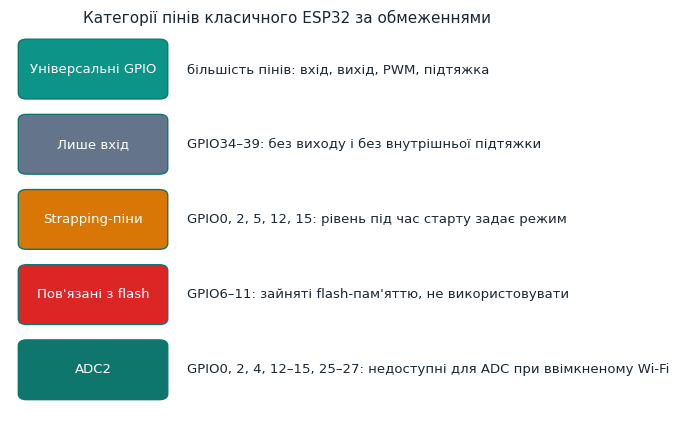

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _block(ax, x, y, w, h, text, color=ACCENT, tcolor="white", fs=9):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                   linewidth=1, edgecolor=ACCENT_DARK, facecolor=color)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=tcolor)

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
cats = [
    ("Універсальні GPIO", "більшість пінів: вхід, вихід, PWM, підтяжка", ACCENT),
    ("Лише вхід", "GPIO34–39: без виходу і без внутрішньої підтяжки", "#64748B"),
    ("Strapping-піни", "GPIO0, 2, 5, 12, 15: рівень під час старту задає режим", "#D97706"),
    ("Пов'язані з flash", "GPIO6–11: зайняті flash-пам'яттю, не використовувати", "#DC2626"),
    ("ADC2", "GPIO0, 2, 4, 12–15, 25–27: недоступні для ADC при ввімкненому Wi-Fi", ACCENT_DARK),
]
for i, (name, desc, color) in enumerate(cats):
    y = 8.3 - i * 1.95
    _block(ax, 0.2, y, 2.6, 1.45, name, color=color, fs=9.5)
    ax.text(3.2, y + 0.72, desc, ha="left", va="center", fontsize=9.5, color=TEXT)
ax.set_title("Категорії пінів класичного ESP32 за обмеженнями", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

*Рисунок 3.1. Ці категорії не є взаємовиключними — наприклад, частина strapping-пінів одночасно підтримує ADC2. Завжди звіряйтесь із документацією конкретної плати.*


### 3.2. Клас Pin: режими та підтяжки — деталі {-}

```python
from machine import Pin

# Вихід зі стартовим значенням
led = Pin(2, Pin.OUT, value=0)

# Вхід із внутрішньою підтяжкою до GND (протилежність PULL_UP)
sensor = Pin(4, Pin.IN, Pin.PULL_DOWN)

# Відкритий стік (open drain) — використовується, коли кілька пристроїв
# по черзі «тягнуть» лінію до 0, а підтяжка забезпечує 1 (типово для I2C)
line = Pin(5, Pin.OPEN_DRAIN)
```
Додатково клас `Pin` дозволяє задати **силу струму драйвера** (`drive`) для потужніших навантажень і читати поточний режим піна через `Pin.mode()`, хоча в більшості навчальних проєктів достатньо базових `OUT`/`IN` з підтяжками.


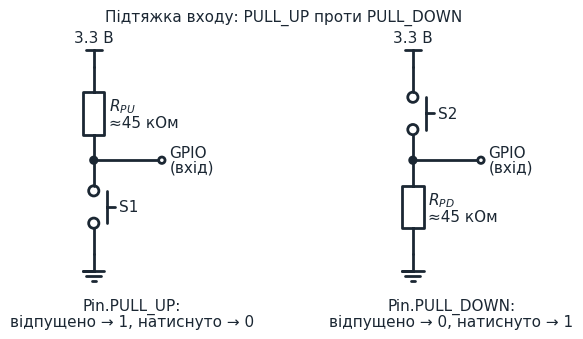

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm

schemdraw.use("matplotlib")
elm.style(elm.STYLE_IEC)          # умовні позначення за ДСТУ/IEC: резистор — прямокутник
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
TEXT = "#1B2733"
schemdraw.config(fontsize=11, color=TEXT)

with schemdraw.Drawing(show=False, unit=2.2) as d:
    # ---- ліва схема: Pin.PULL_UP (резистор до 3.3 В, кнопка до GND)
    d += elm.Vdd().label("3.3 В")
    d += elm.Resistor().down().label("$R_{PU}$\n≈45 кОм", loc="bottom")
    n1 = d.add(elm.Dot())
    d += elm.Button().down().label("S1", loc="bottom")
    d += elm.Ground()
    d += elm.Line().at(n1.center).right(1.6)
    d += elm.Dot(open=True).label("GPIO\n(вхід)", loc="right")
    d += elm.Label().at((n1.center[0] + 0.8, -5.9)).label("Pin.PULL_UP:\nвідпущено → 1, натиснуто → 0")
    # ---- права схема: Pin.PULL_DOWN (кнопка до 3.3 В, резистор до GND)
    d += elm.Vdd().at((7.5, 0)).label("3.3 В")
    d += elm.Button().down().label("S2", loc="bottom")
    n2 = d.add(elm.Dot())
    d += elm.Resistor().down().label("$R_{PD}$\n≈45 кОм", loc="bottom")
    d += elm.Ground()
    d += elm.Line().at(n2.center).right(1.6)
    d += elm.Dot(open=True).label("GPIO\n(вхід)", loc="right")
    d += elm.Label().at((n2.center[0] + 0.8, -5.9)).label("Pin.PULL_DOWN:\nвідпущено → 0, натиснуто → 1")
bb = d.get_bbox()                 # розмір рисунка — за габаритами схеми, не ширше 8.5 дюйма
k = min(0.5, 8.5 / (bb.xmax - bb.xmin))
fig, ax = plt.subplots(figsize=((bb.xmax - bb.xmin) * k + 0.4, (bb.ymax - bb.ymin) * k + 0.8))
d.draw(canvas=ax)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Підтяжка входу: PULL_UP проти PULL_DOWN", fontsize=11, color=TEXT, pad=12)
plt.tight_layout()
plt.show()

*Рисунок 3.2. При `PULL_UP` внутрішній резистор (≈45 кОм) підтягує вхід до 3.3 В, тому відпущена кнопка читається як 1, а натиснута, що замикає лінію на GND, — як 0. При `PULL_DOWN` усе навпаки: резистор тягне вхід до GND, а кнопка під'єднана до 3.3 В. Для довгих проводів чи шумного середовища внутрішньої підтяжки може не вистачити — тоді додають зовнішній резистор 4.7–10 кОм.*


### 3.3. Апаратні переривання: поглиблено {-}

У Лабораторній №3 ми познайомились із `Pin.irq()` на прикладному рівні. Варто розуміти механізм глибше:

- Переривання обробляється **апаратно**, тому реагує майже миттєво — на відміну від опитування (`polling`) у циклі, яке залежить від того, чим зайнятий процесор у момент події.
- Обробник (ISR — Interrupt Service Routine) виконується «поза чергою» відносно основного коду, тому в ньому заборонено: виділяти нову пам'ять складними операціями, викликати `time.sleep()`, звертатись до деяких шин. Найкраща практика — лише встановити прапорець або записати значення в заздалегідь створену змінну.
- Кілька пінів можуть мати незалежні обробники одночасно — кожен викликається окремо для «свого» піна.


### 3.4. Апаратний лічильник імпульсів (PCNT) {-}

Для задач на кшталт підрахунку обертів енкодера чи імпульсів витратоміра постійне переривання на кожен імпульс може бути неефективним при високій частоті сигналу. ESP32 має апаратний блок **PCNT (Pulse Counter)**, що рахує імпульси «у залізі», без участі процесора на кожному імпульсі:
```python
from machine import Pin
from esp32 import PCNT      # доступність модуля залежить від збірки прошивки

pcnt = PCNT(0, pin=Pin(4), rising=True, falling=False)
pcnt.start()
print(pcnt.value())          # поточна кількість зафіксованих імпульсів
pcnt.value(0)                 # скинути лічильник
```
Такий підхід звільняє процесор для іншої роботи навіть при дуже частих імпульсах на вході.


### 3.5. Електричний захист входів і виходів {-}

Піни мікроконтролера розраховані на конкретний діапазон струму й напруги (для ESP32 — логічні рівні 3.3 В, максимальний струм на пін — одиниці — десятки міліампер залежно від конкретного піна). Типові практичні правила:
- **Ніколи** не подавайте на GPIO напругу вище 3.3 В напряму (5-вольтові давачі потребують дільника напруги або спеціальної мікросхеми зсуву рівнів, level shifter).
- Для світлодіода завжди використовуйте обмежувальний резистор (типово 220–330 Ом) — без нього струм обмежується лише внутрішнім опором піна, що може пошкодити і LED, і сам мікроконтролер.
- Для потужних навантажень (двигуни, реле, потужні LED-стрічки) GPIO **ніколи** не підключають напряму — використовують транзисторний ключ, MOSFET-драйвер або модуль реле, і живлення навантаження беруть з окремого джерела.


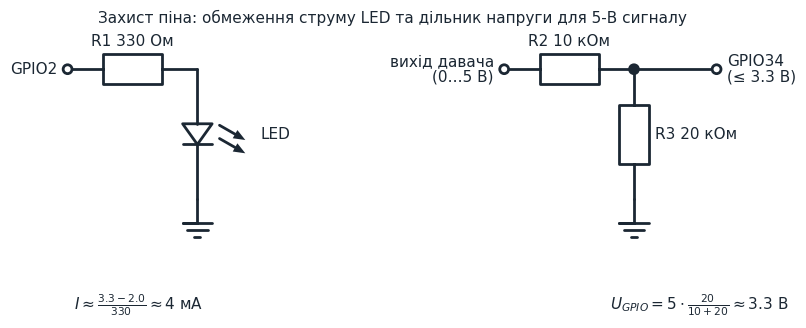

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm

schemdraw.use("matplotlib")
elm.style(elm.STYLE_IEC)          # умовні позначення за ДСТУ/IEC: резистор — прямокутник
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
TEXT = "#1B2733"
schemdraw.config(fontsize=11, color=TEXT)

with schemdraw.Drawing(show=False, unit=2.2) as d:
    # ---- ліва схема: світлодіод з обмежувальним резистором
    d += elm.Dot(open=True).label("GPIO2", loc="left")
    d += elm.Resistor().right().label("R1 330 Ом")
    d += elm.LED().down().label("LED", loc="bottom")
    d += elm.Ground()
    d += elm.Label().at((1.1, -3.9)).label("$I \\approx \\frac{3.3 - 2.0}{330} \\approx 4$ мА")
    # ---- права схема: дільник напруги для 5-вольтового давача
    d += elm.Dot(open=True).at((7.4, 0)).label("вихід давача\n(0…5 В)", loc="left")
    d += elm.Resistor().right().label("R2 10 кОм")
    n = d.add(elm.Dot())
    d += elm.Line().right(1.4)
    d += elm.Dot(open=True).label("GPIO34\n(≤ 3.3 В)", loc="right")
    d += elm.Resistor().at(n.center).down().label("R3 20 кОм", loc="bottom")
    d += elm.Ground()
    d += elm.Label().at((10.6, -3.9)).label("$U_{GPIO} = 5 \\cdot \\frac{20}{10 + 20} \\approx 3.3$ В")
bb = d.get_bbox()                 # розмір рисунка — за габаритами схеми, не ширше 8.5 дюйма
k = min(0.5, 8.5 / (bb.xmax - bb.xmin))
fig, ax = plt.subplots(figsize=((bb.xmax - bb.xmin) * k + 0.4, (bb.ymax - bb.ymin) * k + 0.8))
d.draw(canvas=ax)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Захист піна: обмеження струму LED та дільник напруги для 5-В сигналу",
                 fontsize=11, color=TEXT, pad=16)
plt.tight_layout()
plt.show()

*Рисунок 3.3. Ліворуч — світлодіод з обмежувальним резистором: при падінні напруги на червоному LED близько 2 В резистор 330 Ом обмежує струм до кількох міліампер. Праворуч — дільник напруги, що знижує 5-вольтовий вихід давача до безпечних для входу ESP32 3.3 В (для швидких цифрових сигналів краще застосовувати мікросхему зсуву рівнів).*


### 3.6. Практичний приклад: сканування матриці кнопок {-}

Якщо потрібно опитувати багато кнопок, а вільних пінів мало, кнопки організовують у матрицю (рядки × стовпці) — класична схема клавіатури. Для матриці 2×2 (4 кнопки на 4 пінах замість 4) логіка сканування:

```python
from machine import Pin
import time

rows = [Pin(p, Pin.OUT) for p in (12, 13)]
cols = [Pin(p, Pin.IN, Pin.PULL_DOWN) for p in (14, 15)]

def scan():
    pressed = []
    for r_idx, row in enumerate(rows):
        row.value(1)                     # активуємо лише один рядок за раз
        for c_idx, col in enumerate(cols):
            if col.value():
                pressed.append((r_idx, c_idx))
        row.value(0)
    return pressed

while True:
    keys = scan()
    if keys:
        print("Натиснуті клавіші (рядок, стовпець):", keys)
    time.sleep_ms(100)
```

Ідея: по черзі подаємо «1» на кожен рядок і перевіряємо, які стовпці «побачили» цю одиницю — так матриця з N рядків і M стовпців дозволяє опитати до N×M кнопок, використовуючи лише N+M пінів.


### 3.7. Дребезг контактів (debounce) {-}

Механічна кнопка чи перемикач при натисканні не перемикається миттєво й чисто — контакти кілька разів торкаються й розмикаються протягом кількох мілісекунд, перш ніж стабілізуватись. Без обробки цей «дребезг» (bounce) сприймається програмою чи перериванням як кілька окремих натискань замість одного. Найпростіший програмний захист — ігнорувати повторні спрацювання протягом короткого інтервалу після першого:

```python
from machine import Pin
import time

button = Pin(4, Pin.IN, Pin.PULL_UP)
last_press_ms = 0
DEBOUNCE_MS = 200

def on_press(pin):
    global last_press_ms
    now = time.ticks_ms()
    if time.ticks_diff(now, last_press_ms) < DEBOUNCE_MS:
        return   # надто швидко після попереднього спрацювання — ігноруємо як дребезг
    last_press_ms = now
    print("Кнопку натиснуто")

button.irq(trigger=Pin.IRQ_FALLING, handler=on_press)
```

Цей підхід (використання `time.ticks_diff()`, як і в Розділі 4.1) — простий програмний аналог апаратних RC-фільтрів чи спеціалізованих мікросхем-дебаунсерів, яких на навчальних платах зазвичай немає.


### 3.8. Особливості пінів для ADC2 та Wi-Fi у порівняльній таблиці {-}

Обмеження ADC2 (Розділ 3.1) варто тримати в голові разом з обмеженнями ADC, розглянутими докладніше в Розділі 5.1 — обидва розділи описують той самий апаратний конфлікт з різних боків: тут як обмеження конкретних пінів, там як обмеження самого модуля ADC.

| Ситуація | Наслідок |
|---|---|
| Wi-Fi вимкнено, читаємо ADC2 | Працює штатно |
| Wi-Fi активний, читаємо ADC1 | Працює штатно (ADC1 не залежить від Wi-Fi) |
| Wi-Fi активний, читаємо ADC2 | Може повертати недостовірні значення або виняток, залежно від збірки прошивки |

**Практичний висновок:** якщо проєкт одночасно потребує Wi-Fi і кількох аналогових входів, під аналогові давачі варто закладати піни саме з групи ADC1 ще на етапі розробки схеми, а не виявляти конфлікт вже під час налагодження готового пристрою.


### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому піни `GPIO34–GPIO39` на класичному ESP32 не можна використовувати як цифровий вихід?</summary>

> **Відповідь:** Це піни лише для входу — вони не мають внутрішньої підтяжки й придатні тільки для читання сигналу чи роботи з ADC, але не для виводу.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Що таке «strapping»-піни і чому підключена до них зовнішня схема може завадити старту плати?</summary>

> **Відповідь:** Це піни (наприклад `GPIO0`, `GPIO2`, `GPIO12`, `GPIO15`), стан яких під час старту плати визначає режим завантаження. Якщо зовнішня схема нав'язує їм «не той» рівень у момент старту, плата може не завантажитись нормально.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Поясніть, чому піни `GPIO6–GPIO11` зазвичай недоступні для власних проєктів.</summary>

> **Відповідь:** Вони зарезервовані для внутрішнього зв'язку чипа з мікросхемою flash-пам'яті, тому використовувати їх як звичайні GPIO не можна.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Як активний Wi-Fi може вплинути на роботу деяких каналів ADC?</summary>

> **Відповідь:** Піни з підтримкою ADC2 конфліктують з активним Wi-Fi — поки Wi-Fi увімкнено, читання ADC2 може бути недоступним або нестабільним.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> У чому різниця між `Pin.PULL_UP`, `Pin.PULL_DOWN` та `Pin.OPEN_DRAIN`?</summary>

> **Відповідь:** `PULL_UP` — внутрішня підтяжка до живлення, `PULL_DOWN` — протилежна підтяжка до GND. `OPEN_DRAIN` — режим виходу, коли пристрій може лише «притягувати» лінію до 0, а до 1 її повертає підтяжка (типово для I2C, коли кілька пристроїв ділять одну лінію).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Чому в обробнику апаратного переривання не рекомендується викликати `time.sleep()`?</summary>

> **Відповідь:** Обробник (ISR) виконується «поза чергою» відносно основного коду і має бути коротким та швидким; `time.sleep()` заблокував би цю позачергову ділянку виконання, тоді як найкраща практика — лише встановити прапорець або записати значення в заздалегідь створену змінну.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Яку практичну перевагу дає апаратний лічильник імпульсів (PCNT) порівняно з підрахунком через `Pin.irq()`?</summary>

> **Відповідь:** PCNT рахує імпульси «у залізі», без участі процесора на кожному імпульсі — це звільняє процесор для іншої роботи навіть при дуже частих імпульсах на вході, на відміну від переривання на кожен окремий імпульс.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Наведіть приклад задачі, для якої PCNT підходить краще, ніж переривання на кожен імпульс.</summary>

> **Відповідь:** Підрахунок обертів енкодера або імпульсів витратоміра при високій частоті сигналу — саме приклад, наведений у розділі 3.4.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Що таке дребезг контактів (bounce) і як найпростіше з ним боротись програмно?</summary>

> **Відповідь:** Механічна кнопка при натисканні кілька разів торкається й розмикається контактами протягом кількох мілісекунд, перш ніж стабілізуватись, тому одне натискання може сприйматись як кілька. Найпростіший захист — ігнорувати повторні спрацювання протягом короткого інтервалу (наприклад, 200 мс) після першого, за допомогою `time.ticks_diff()`.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 10.</b> Чому варто закладати аналогові давачі саме на піни ADC1, а не ADC2, ще на етапі проєктування схеми проєкту з Wi-Fi?</summary>

> **Відповідь:** Бо ADC2 конфліктує з активним Wi-Fi і може повертати недостовірні значення, поки Wi-Fi увімкнено; виявляти цей конфлікт вже під час налагодження готового пристрою значно дорожче, ніж врахувати його заздалегідь.

</details>


```{=latex}
\end{selfcheckbox}
```

# 📘 Розділ 4. Час, затримки, таймери та керування живленням

### Після опрацювання розділу ви зможете: {-}
- коректно вимірювати інтервали часу без переповнення лічильника
- використовувати апаратні таймери для періодичних задач
- застосовувати сторожовий таймер (WDT) для підвищення надійності пристрою
- обирати режим сну (light/deep sleep) відповідно до вимог енергоспоживання
- пояснити, чому точність вимірювання часу різна в активному режимі та під час сну


### 4.1. Модуль time: вимірювання інтервалів {-}

Окрім уже відомих `time.sleep()`/`sleep_ms()`/`sleep_us()`, модуль `time` надає функції для коректного вимірювання проміжків часу:
```python
import time

start = time.ticks_ms()
# ... якісь обчислення ...
elapsed = time.ticks_diff(time.ticks_ms(), start)   # правильна різниця в мс
print("Минуло:", elapsed, "мс")
```
**Чому не можна просто відняти `time.ticks_ms()` одне від одного напряму?** Лічильник міток часу має обмежену розрядність і періодично переповнюється (обнуляється), тому пряме віднімання (`t2 - t1`) може дати від'ємне чи некоректне число після переповнення. Функція `ticks_diff()` враховує це коректно й повинна використовуватись завжди, коли інтервал вимірювання може бути тривалим.


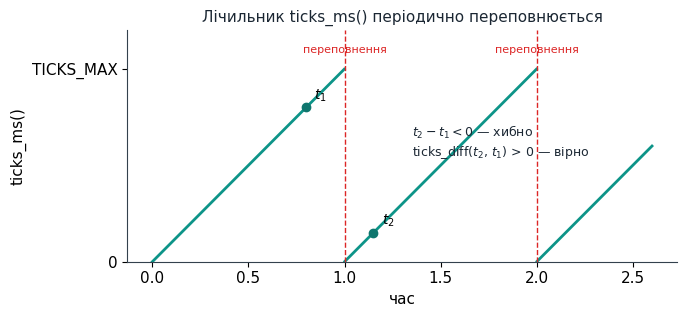

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, ax = plt.subplots(figsize=(7, 3.3))
period = 1.0                                   # умовний період переповнення (TICKS_PERIOD)
t = np.linspace(0, 2.6, 2000)
y = t % period
y[np.r_[False, np.diff(y) < 0]] = np.nan       # не з'єднувати вертикальною лінією точки до/після переповнення
ax.plot(t, y, color=ACCENT, lw=2)
for k in (1, 2):
    ax.axvline(k * period, color="#DC2626", linestyle="--", lw=1)
    ax.text(k * period, 1.08, "переповнення", fontsize=8, color="#DC2626", ha="center")
t1, t2 = 0.8, 1.15
for tt, name in [(t1, "$t_1$"), (t2, "$t_2$")]:
    ax.plot(tt, tt % period, "o", color=ACCENT_DARK, zorder=5)
    ax.annotate(name, (tt, tt % period), xytext=(6, 6), textcoords="offset points", fontsize=10)
ax.text(1.35, 0.55, "$t_2 - t_1 < 0$ — хибно\nticks_diff($t_2$, $t_1$) > 0 — вірно", fontsize=9, color=TEXT)
ax.set_xlabel("час")
ax.set_ylabel("ticks_ms()")
ax.set_yticks([0, 1]); ax.set_yticklabels(["0", "TICKS_MAX"])
ax.set_ylim(0, 1.2)
ax.set_title("Лічильник ticks_ms() періодично переповнюється", fontsize=11, color=TEXT)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

*Рисунок 4.1. Пряме віднімання значень до й після переповнення дає хибний, часто від'ємний результат; `time.ticks_diff()` коректно враховує «загортання» лічильника через модульну арифметику.*


### 4.2. machine.Timer — апаратні таймери {-}

Клас `Timer`, з яким ми працювали в Лабораторній №3, використовує апаратні блоки таймерів чипа. ESP32 має декілька незалежних таймерів (позначаються номером, наприклад `Timer(0)`, `Timer(1)`), тому кілька періодичних задач можуть співіснувати незалежно одна від одної:
```python
from machine import Timer

def task_a(t):
    print("Задача A")

def task_b(t):
    print("Задача B")

Timer(0).init(period=1000, mode=Timer.PERIODIC, callback=task_a)
Timer(1).init(period=300, mode=Timer.PERIODIC, callback=task_b)
```
Кожен виклик `callback` — це, по суті, коротке переривання за часом, тому до нього застосовуються ті самі обмеження, що й до обробників `Pin.irq()` (Розділ 3.3): код усередині має бути коротким і швидким.


### 4.3. Сторожовий таймер (Watchdog Timer, WDT) {-}

**WDT** — апаратний «сторож», що автоматично перезавантажує плату, якщо основна програма не «звітує» про свою роботу протягом заданого часу. Це критично важливо для автономних пристроїв (наприклад, датчиків у полі), де ніхто не натисне кнопку RESET вручну при зависанні:
```python
from machine import WDT
import time

wdt = WDT(timeout=5000)    # якщо feed() не викликати 5 секунд — плата перезавантажиться

while True:
    # ... основна робота пристрою ...
    wdt.feed()               # "погодувати" сторожа — підтвердити, що програма жива
    time.sleep(1)
```
**Важливо:** після ініціалізації `WDT` у більшості реалізацій MicroPython його **неможливо вимкнути програмно** — це свідома конструкція, щоб код помилково не «забув» вимкнути захист.


### 4.4. Режими сну та енергоефективність {-}

Для пристроїв на батарейному живленні критично важливо мінімізувати споживання, коли активна робота не потрібна:

| Режим | Споживання | Що зберігається | Пробудження |
|---|---|---|---|
| Активний режим | найвище | усе (RAM, периферія, Wi-Fi) | — |
| Light sleep | знижене | вміст RAM, стан периферії | за таймером, зовнішнім сигналом, UART |
| Deep sleep | мінімальне | лише невеликий блок RTC-пам'яті; основна RAM очищається | за таймером (RTC) або сигналом на визначених пінах — після пробудження плата фактично перезапускається (виконується `boot.py` заново) |

```python
import machine
import esp32

# Прокинутись через 10 секунд глибокого сну
machine.deepsleep(10_000)

# Дозволити пробудження від конкретного піна (перед входом у сон)
esp32.wake_on_ext0(pin=machine.Pin(4), level=esp32.WAKEUP_ALL_LOW)
```
Оскільки після `deepsleep()` плата фактично перезапускається, змінні програми не зберігаються між пробудженнями (окрім спеціальної RTC-пам'яті) — тому логіку періодичного «прокинутись → зчитати датчик → надіслати дані → знову заснути» пишуть з урахуванням того, що кожен цикл починається «з нуля».


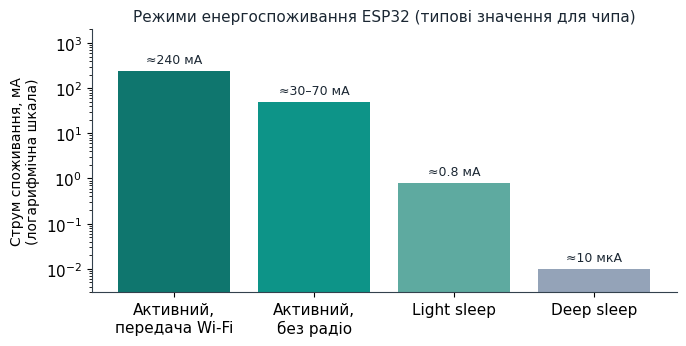

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

# Типові значення струму споживання самого чипа ESP32 (за даташитом Espressif);
# плата загалом споживає більше через стабілізатор, USB-UART-міст і світлодіоди.
modes = ["Активний,\nпередача Wi-Fi", "Активний,\nбез радіо", "Light sleep", "Deep sleep"]
current_ma = [240, 50, 0.8, 0.01]
labels = ["≈240 мА", "≈30–70 мА", "≈0.8 мА", "≈10 мкА"]
colors = [ACCENT_DARK, ACCENT, "#5EAAA0", "#94A3B8"]
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(modes, current_ma, color=colors)
ax.set_yscale("log")
ax.set_ylim(0.003, 2000)
ax.set_ylabel("Струм споживання, мА\n(логарифмічна шкала)", fontsize=10)
for b, v, lab in zip(bars, current_ma, labels):
    ax.text(b.get_x() + b.get_width()/2, v * 1.5, lab, ha="center", fontsize=9, color=TEXT)
ax.set_title("Режими енергоспоживання ESP32 (типові значення для чипа)", fontsize=11, color=TEXT)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

*Рисунок 4.2. Типові значення струму самого чипа ESP32 за даташитом (шкала логарифмічна): deep sleep знижує споживання приблизно на чотири порядки відносно активного режиму з Wi-Fi, light sleep займає проміжне положення. Плата загалом споживає більше — через стабілізатор напруги, USB-UART-міст і світлодіод живлення.*


### 4.5. Джерела тактування та точність часу {-}

ESP32 отримує тактову частоту від кількох джерел: основний кварцовий генератор (для процесора й периферії) та окремий, значно менш точний RC-генератор або зовнішній кварц для RTC-блоку (використовується під час глибокого сну, коли основний генератор вимкнено для економії енергії). Через це:
- Час, виміряний через `time.ticks_ms()` під час активної роботи, досить точний (похибка кварца — одиниці ppm).
- Тривалість `deepsleep()`, заданої в мілісекундах, може мати помітно більшу похибку (відсотки), якщо плата покладається на менш точний RTC-генератор — для задач, де критична точність довгих інтервалів, варто періодично звірятися з мережевим часом (NTP, Розділ 13).


### 4.6. Практичний приклад: неблокуючий кооперативний планувальник {-}

Часто потрібно виконувати кілька незалежних періодичних задач (блимати LED кожні 500 мс, перевіряти датчик кожні 2 с, оновлювати дисплей раз на секунду) без вкладених таймерів чи переривань. Простий і надійний прийом — **кооперативний планувальник** на основі `time.ticks_ms()`:

```python
import time

class Task:
    def __init__(self, interval_ms, func):
        self.interval_ms = interval_ms
        self.func = func
        self.last_run = time.ticks_ms()

    def maybe_run(self, now):
        if time.ticks_diff(now, self.last_run) >= self.interval_ms:
            self.func()
            self.last_run = now

tasks = [
    Task(500, lambda: print("Блимання LED")),
    Task(2000, lambda: print("Перевірка датчика")),
    Task(1000, lambda: print("Оновлення дисплея")),
]

while True:
    now = time.ticks_ms()
    for t in tasks:
        t.maybe_run(now)
```

Кожна задача виконується «вчасно» незалежно від інших, а основний цикл ніколи не блокується — це проста альтернатива апаратним таймерам, зручна, коли задач багато, а самих таймерів на платі не вистачає. У Розділі 16 ми побачимо, як ту саму ідею елегантніше вирішує `asyncio`.


### 4.7. Дрейф кооперативного планувальника {-}

Планувальник із Розділу 4.6 має тонку ваду: якщо `func()` однієї задачі виконується довго (наприклад, читання давача через повільну шину), запуск наступної перевірки `maybe_run()` для інших задач затримується — інтервали «пливуть» і не гарантують точну періодичність, лише «не рідше, ніж». Для більшості навчальних і практичних задач (блимання LED, періодичне опитування) це прийнятно, але для задач, де критична саме стабільна частота (наприклад, генерація точного сигналу), варто або тримати `func()` максимально короткими, або передати цю роботу апаратному `Timer` (Розділ 4.2), який не залежить від того, скільки часу займають інші задачі в основному циклі.


### 4.8. Практичний приклад: комбінування WDT і deep sleep {-}

Важливий нюанс для автономних пристроїв: WDT (Розділ 4.3) і `deepsleep()` (Розділ 4.4) за замовчуванням не завжди «дружать» одне з одним — якщо WDT ініціалізовано з коротким тайм-аутом, а планований інтервал сну довший за нього, плата може перезавантажитись просто через WDT ще до запланованого пробудження. Практичне правило:

```python
from machine import WDT, deepsleep
import time

SLEEP_MS = 60_000

# WDT вмикаємо лише на час активної фази, з запасом за часом виконання коду,
# а перед входом у deepsleep() коректно завершуємо активну фазу без активного WDT,
# що очікує "годування" довше за сам сон.
wdt = WDT(timeout=8000)   # тайм-аут з запасом під час, поки пристрій ще активний

# ... зчитування давача, надсилання даних ...
wdt.feed()

time.sleep_ms(100)   # невелика пауза перед сном
deepsleep(SLEEP_MS)
```

**Головний висновок:** тайм-аут WDT потрібно узгоджувати з тривалістю активної фази роботи пристрою, а не з довжиною подальшого сну — інакше сторожовий таймер із «захисника» перетворюється на джерело неочікуваних перезавантажень.


### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому пряме віднімання двох значень `time.ticks_ms()` може дати некоректний результат, а `time.ticks_diff()` — ні?</summary>

> **Відповідь:** Лічильник міток часу має обмежену розрядність і періодично переповнюється (обнуляється), тому пряме віднімання може дати від'ємне чи некоректне число після переповнення. `time.ticks_diff()` враховує це коректно.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Скільки незалежних апаратних таймерів може одночасно працювати на ESP32 і навіщо це потрібно?</summary>

> **Відповідь:** Декілька незалежних таймерів (позначаються номером, наприклад `Timer(0)`, `Timer(1)`) — це дозволяє кільком періодичним задачам співіснувати незалежно одна від одної.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Які обмеження діють на код усередині `callback` таймера?</summary>

> **Відповідь:** Ті самі, що й для обробників `Pin.irq()` (розділ 3.3): кожен виклик `callback` — це, по суті, коротке переривання за часом, тому код усередині має бути коротким і швидким.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Для чого призначений сторожовий таймер (WDT) і чому його зазвичай не можна вимкнути програмно?</summary>

> **Відповідь:** WDT автоматично перезавантажує плату, якщо основна програма не «звітує» (не викликає `feed()`) протягом заданого часу — критично для автономних пристроїв, де ніхто не натисне RESET вручну. Його не можна вимкнути програмно навмисно, щоб код помилково не «забув» вимкнути цей захист.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Що станеться з пристроєм на WDT, якщо основний цикл програми «зависне» й перестане викликати `feed()`?</summary>

> **Відповідь:** Плата автоматично перезавантажиться, щойно мине заданий таймаут WDT.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Порівняйте light sleep і deep sleep за рівнем споживання та збереженням стану програми.</summary>

> **Відповідь:** Light sleep — знижене споживання, зберігається вміст RAM і стан периферії, пробудження за таймером/зовнішнім сигналом/UART. Deep sleep — мінімальне споживання, зберігається лише невеликий блок RTC-пам'яті (основна RAM очищається), пробудження за таймером (RTC) чи сигналом на визначених пінах — плата фактично перезапускається.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Чому після `machine.deepsleep()` змінні програми, як правило, втрачаються?</summary>

> **Відповідь:** Тому що після глибокого сну плата фактично перезапускається, і основна RAM очищається — зберігається лише спеціальна RTC-пам'ять.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Опишіть типовий сценарій роботи автономного давача, що використовує deep sleep для економії батареї.</summary>

> **Відповідь:** Цикл «прокинутись → зчитати датчик → надіслати дані → знову заснути», написаний з урахуванням того, що кожен цикл починається «з нуля», оскільки змінні програми не зберігаються між пробудженнями.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> У чому обмеження кооперативного планувальника з Розділу 4.6 щодо точності інтервалів?</summary>

> **Відповідь:** Якщо `func()` однієї задачі виконується довго, перевірка інших задач затримується — інтервали гарантують лише «не рідше, ніж», а не точну періодичність, на відміну від апаратного `Timer`.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 10.</b> Чому тайм-аут WDT потрібно узгоджувати з тривалістю активної фази, а не з довжиною подальшого deep sleep?</summary>

> **Відповідь:** Якщо тайм-аут WDT коротший за запланований сон, а WDT лишається активним, плата може перезавантажитись через WDT ще до запланованого пробудження — WDT має покривати саме активну фазу роботи, після якої пристрій коректно входить у сон.

</details>


```{=latex}
\end{selfcheckbox}
```

# 📘 Розділ 5. Аналогові інтерфейси: ADC, DAC, PWM

### Після опрацювання розділу ви зможете: {-}
- пояснити принцип роботи АЦП і налаштувати коректний діапазон вимірювання на ESP32
- сформувати аналоговий сигнал на виході через ЦАП (DAC)
- пояснити принцип ШІМ і апаратні обмеження каналів на ESP32
- обрати відповідний інтерфейс (ADC/DAC/PWM) під конкретну задачу
- відрізняти дискретизацію від квантування сигналу та пояснювати похибку квантування


### 5.1. АЦП (ADC): принцип і особливості ESP32 {-}

Ми вже використовували `machine.ADC` у Лабораторній №2. Розглянемо деталі точніше:

- ESP32 має два блоки АЦП: **ADC1** (піни `GPIO32–GPIO39`) та **ADC2** (частина пінів `GPIO0–GPIO27`).
- **ADC2 конфліктує з Wi-Fi**: коли модуль Wi-Fi активний, читання з каналів ADC2 може бути недоступним або нестабільним. Для проєктів, що одночасно використовують Wi-Fi і аналогові датчики, рекомендується підключати датчики саме до пінів ADC1.
- Роздільність АЦП налаштовується (`ADC.width()` у деяких версіях), а послаблення (`atten`) визначає, до якої максимальної напруги коректно вимірюється сигнал:

| Значення atten | Приблизний діапазон вимірювання |
|---|---|
| `ADC.ATTN_0DB` | ~0–1.1 В |
| `ADC.ATTN_2_5DB` | ~0–1.5 В |
| `ADC.ATTN_6DB` | ~0–2.2 В |
| `ADC.ATTN_11DB` | ~0–3.3 В (найчастіше використовується) |

АЦП ESP32 має нелінійність поблизу країв діапазону — для точних вимірювань виробник рекомендує програмну калібровку (в деяких портах доступна автоматично).


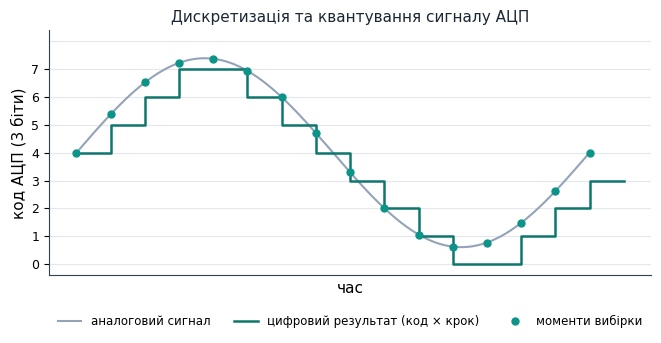

In [11]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

# Для наочності — 3-бітний АЦП (8 рівнів) замість реальних 12 біт ESP32
bits, vref = 3, 3.3
lsb = vref / 2**bits
t = np.linspace(0, 2 * np.pi, 600)
signal = 1.65 + 1.4 * np.sin(t)
ts = np.linspace(0, 2 * np.pi, 16)
samples = 1.65 + 1.4 * np.sin(ts)
codes = np.clip(np.floor(samples / lsb), 0, 2**bits - 1)
quant = codes * lsb

fig, ax = plt.subplots(figsize=(7, 3.6))
for k in range(2**bits + 1):
    ax.axhline(k * lsb, color=GRID, lw=0.8, zorder=0)
ax.plot(t, signal, color="#94A3B8", lw=1.5, label="аналоговий сигнал")
ax.step(np.r_[ts, 2 * np.pi + 0.42], np.r_[quant, quant[-1]], where="post", color=ACCENT_DARK, lw=1.8,
        label="цифровий результат (код × крок)")
ax.plot(ts, samples, "o", color=ACCENT, ms=5, label="моменти вибірки")
ax.set_yticks([k * lsb for k in range(2**bits)])
ax.set_yticklabels([f"{k}" for k in range(2**bits)], fontsize=9)
ax.set_ylabel("код АЦП (3 біти)")
ax.set_xlabel("час")
ax.set_xticks([])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8.5, frameon=False)
ax.set_title("Дискретизація та квантування сигналу АЦП", fontsize=11, color=TEXT)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

*Рисунок 5.1. АЦП вимірює сигнал лише у дискретні моменти часу (дискретизація) і відкидає дробову частину, зводячи кожне значення до одного з обмеженої кількості рівнів (квантування) — обидва ефекти є джерелом похибки, додатковим до нелінійності самої мікросхеми. Для наочності показано 3-бітний АЦП (8 рівнів); АЦП ESP32 має 12 біт (4096 рівнів), тож крок квантування в нього значно дрібніший.*


### 5.2. ЦАП (DAC): аналоговий вихід {-}

На відміну від ШІМ (яка лише імітує аналоговий рівень «в середньому»), **DAC (Digital-to-Analog Converter)** видає справжню аналогову напругу безпосередньо. На ESP32 доступно два 8-бітні канали DAC, жорстко прив'язані до конкретних пінів (`GPIO25` і `GPIO26`):
```python
from machine import DAC, Pin

dac = DAC(Pin(25))
dac.write(128)     # значення 0-255, приблизно середина шкали (~1.65 В з максимальних ~3.3 В)
```
Типове застосування DAC — генерація простих аналогових сигналів (наприклад, синусоїди для звуку низької якості) без потреби у зовнішній ШІМ-фільтрації.


### 5.3. ШІМ (PWM): апаратні обмеження {-}

У Лабораторній №2 ми використовували `machine.PWM` для яскравості LED і керування сервоприводом. На апаратному рівні ESP32 має обмежену кількість незалежних ШІМ-каналів і «груп» частот — тобто піни, що використовують один і той самий базовий таймер, змушені працювати з однаковою (або кратною) частотою. Якщо у проєкті потрібно кілька PWM-виходів з дуже різними частотами (наприклад, 50 Гц для сервопривода й 5000 Гц для зумера), варто перевірити документацію конкретної збірки прошивки на кількість незалежних каналів, і за потреби звільняти невикористані PWM-об'єкти (`pwm.deinit()`) перед створенням нових.


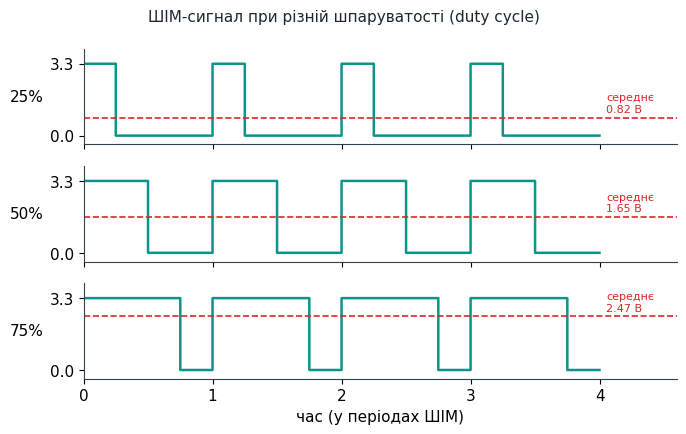

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, axs = plt.subplots(3, 1, figsize=(7, 4.4), sharex=True)
t = np.linspace(0, 4, 4000, endpoint=False)
for ax, duty in zip(axs, [0.25, 0.5, 0.75]):
    v = 3.3 * ((t % 1) < duty)
    ax.plot(t, v, color=ACCENT, lw=1.8, drawstyle="steps-post")
    ax.axhline(3.3 * duty, color="#DC2626", lw=1.2, ls="--")
    ax.text(4.05, 3.3 * duty + 0.15, f"середнє\n{3.3 * duty:.2f} В", fontsize=8, color="#DC2626", va="bottom")
    ax.set_ylim(-0.4, 4.0); ax.set_yticks([0, 3.3])
    ax.set_ylabel(f"{int(duty * 100)}%", rotation=0, ha="right", va="center")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
axs[-1].set_xlabel("час (у періодах ШІМ)")
axs[-1].set_xlim(0, 4.6)
fig.suptitle("ШІМ-сигнал при різній шпаруватості (duty cycle)", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

*Рисунок 5.2. Частота (кількість періодів за секунду) при цьому лишається сталою — змінюється лише частка періоду, коли сигнал високий (шпаруватість $D$), що й визначає «середній» рівень $U_{сер} = 3.3 \cdot D$ (червона пунктирна лінія), який відчуває LED чи сервопривід.*


### 5.4. Порівняння ADC, DAC і PWM {-}

| Інтерфейс | Напрямок | Що дає | Типове застосування |
|---|---|---|---|
| ADC | вхід | цифрове значення, що відповідає виміряній напрузі | потенціометри, аналогові датчики (світло, температура, газ) |
| DAC | вихід | справжня аналогова напруга (2 канали, 8 біт) | генерація простих сигналів, звук низької якості |
| PWM | вихід | цифровий сигнал зі змінною шпаруватістю, що імітує «середній» аналоговий рівень | яскравість LED, керування сервоприводами, керування двигунами через драйвер |


### 5.5. Фільтрація аналогового сигналу {-}

Реальні аналогові сигнали (особливо з довгих проводів чи дешевих давачів) містять шум — випадкові швидкі коливання навколо істинного значення. Два взаємодоповнювальних підходи до боротьби з ним:
- **Апаратний фільтр** — простий RC-фільтр (резистор + конденсатор між лінією сигналу й землею) згладжує швидкі стрибки напруги ще до того, як сигнал потрапляє на пін ADC.
- **Програмне згладжування** — усереднення кількох послідовних вимірювань:
  ```python
  def read_smoothed(adc, samples=10):
      total = 0
      for _ in range(samples):
          total += adc.read_u16()
      return total // samples
  ```
  Простіший, дешевший спосіб (не потребує додаткових деталей), але «з'їдає» трохи часу на кожне вимірювання і згладжує лише випадковий шум, а не систематичну похибку самого давача.


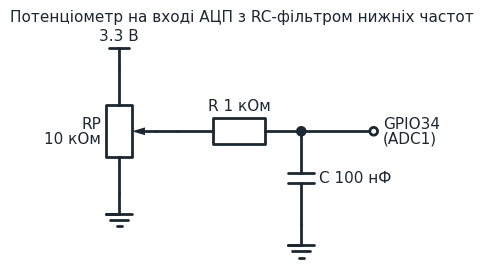

In [13]:
%matplotlib inline
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm

schemdraw.use("matplotlib")
elm.style(elm.STYLE_IEC)          # умовні позначення за ДСТУ/IEC: резистор — прямокутник
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
TEXT = "#1B2733"
schemdraw.config(fontsize=11, color=TEXT)

with schemdraw.Drawing(show=False, unit=2.4) as d:
    d += elm.Vdd().label("3.3 В")
    pot = d.add(elm.Potentiometer().down().label("RP\n10 кОм", loc="top"))
    d += elm.Ground()
    d += elm.Line().at(pot.tap).right(0.4)
    d += elm.Resistor().right().label("R 1 кОм")
    n = d.add(elm.Dot())
    d += elm.Line().right(1.4)
    d += elm.Dot(open=True).label("GPIO34\n(ADC1)", loc="right")
    d += elm.Capacitor().at(n.center).down(1.8).label("C 100 нФ", loc="bottom")
    d += elm.Ground()
bb = d.get_bbox()                 # розмір рисунка — за габаритами схеми, не ширше 8.5 дюйма
k = min(0.5, 8.5 / (bb.xmax - bb.xmin))
fig, ax = plt.subplots(figsize=((bb.xmax - bb.xmin) * k + 0.4, (bb.ymax - bb.ymin) * k + 0.8))
d.draw(canvas=ax)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Потенціометр на вході АЦП з RC-фільтром нижніх частот", fontsize=11, color=TEXT, pad=12)
plt.tight_layout()
plt.show()

*Рисунок 5.3. Потенціометр як дільник напруги подає на вхід АЦП напругу 0–3.3 В, а RC-ланка (1 кОм, 100 нФ) з частотою зрізу $f_c = \frac{1}{2\pi RC} \approx 1.6$ кГц згладжує швидкі завади ще до піна. Вхід підключено до каналу ADC1 (GPIO34), щоб вимірювання працювали й при ввімкненому Wi-Fi.*


### 5.6. Практичний приклад: цифровий вольтметр з калібруванням {-}

Пряме перетворення `read_u16()` у вольти за теоретичною формулою (`value / 65535 * 3.3`) часто дає систематичну похибку через нелінійність реального АЦП. Проста практична калібровка — виміряти два відомі опорні значення (наприклад, 0 В і напругу від стабільного джерела 3.3 В) і побудувати лінійну залежність:

```python
from machine import ADC, Pin

adc = ADC(Pin(34))
adc.atten(ADC.ATTN_11DB)

# Значення, зняті одноразово під час калібрування (приклад — підставте свої):
RAW_AT_0V = 120        # покази adc.read_u16() при вході, з'єднаному з GND
RAW_AT_3V3 = 65000      # покази при вході, з'єднаному з відомим джерелом 3.3 В

def read_voltage():
    raw = adc.read_u16()
    return 3.3 * (raw - RAW_AT_0V) / (RAW_AT_3V3 - RAW_AT_0V)

print("Напруга:", round(read_voltage(), 3), "В")
```

Такий підхід («лінійна калібровка за двома точками») — стандартний прийом не лише для ADC, а й для будь-якого аналогового давача з відомою лінійною характеристикою (наприклад, давачів тиску чи ваги).


### 5.7. Теорема Найквіста—Котельникова у практиці мікроконтролера {-}

Для коректного відтворення частоти сигналу без спотворень (**аліасингу**) частота дискретизації повинна бути щонайменше вдвічі вищою за найвищу значущу частоту в сигналі. Наприклад, якщо потрібно розпізнати биття серця (робочий діапазон приблизно до ~5 Гц), навіть 20–50 вимірювань на секунду — з великим запасом. А от для якісного відтворення звуку (до ~20 кГц) потрібна дискретизація в десятки кГц — саме тому в Розділі 9 для звукових задач ESP32 використовує окремий апаратний блок I2S, а не звичайний ADC у циклі: `machine.ADC.read_u16()` у Python-циклі MicroPython просто не встигає викликатись достатньо часто й регулярно для якісного звуку.

**Практичний наслідок:** перед тим, як писати код для будь-якого аналогового давача, варто оцінити орієнтовну верхню частоту сигналу, що вимірюється, і звідси — мінімально потрібну частоту опитування, а не покладатись на «як швидко вийде» у циклі `while True`.


### 5.8. Типові помилки при роботі з аналоговими інтерфейсами {-}

| Помилка | Наслідок |
|---|---|
| Підключення 5-вольтового аналогового давача напряму до ADC | Перевищення допустимих 3.3 В може пошкодити пін або весь чип; потрібен дільник напруги |
| Використання `read_u16()` без урахування `atten` | Значення виглядають «затиснутими» біля максимуму чи мінімуму шкали, якщо реальний діапазон сигналу не відповідає обраному `atten` |
| Читання ADC2 при увімкненому Wi-Fi | Нестабільні або недоступні покази (Розділ 5.1 і Розділ 3.8) |
| Довге навантаження на вихід DAC (наприклад, безпосередньо потужний динамік) | DAC розрахований на невеликий струм навантаження — для реального звуку потрібен зовнішній підсилювач |
| Ігнорування шуму без жодної фільтрації | Різкі, «стрибаючі» покази датчика навіть за стабільної фізичної величини |



### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чим ADC1 відрізняється від ADC2 на ESP32 і чому це важливо в проєктах з Wi-Fi?</summary>

> **Відповідь:** ADC1 — піни `GPIO32–GPIO39`, ADC2 — частина пінів `GPIO0–GPIO27`. ADC2 конфліктує з Wi-Fi: коли модуль Wi-Fi активний, читання з каналів ADC2 може бути недоступним або нестабільним, тому в проєктах з Wi-Fi датчики варто підключати до пінів ADC1.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Як параметр `atten` впливає на діапазон коректно вимірюваної напруги АЦП?</summary>

> **Відповідь:** Він визначає максимальну напругу коректного вимірювання: `ATTN_0DB` — приблизно 0–1.1 В, `ATTN_2_5DB` — 0–1.5 В, `ATTN_6DB` — 0–2.2 В, `ATTN_11DB` — 0–3.3 В (найчастіше використовується).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Скільки каналів DAC доступно на ESP32 і на яких саме пінах?</summary>

> **Відповідь:** Два 8-бітні канали, жорстко прив'язані до пінів `GPIO25` і `GPIO26`.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Чим справжній аналоговий вихід (DAC) принципово відрізняється від ШІМ-сигналу (PWM)?</summary>

> **Відповідь:** DAC видає справжню аналогову напругу безпосередньо, тоді як ШІМ лише імітує «середній» аналоговий рівень цифровим сигналом зі змінною шпаруватістю.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому кілька PWM-виходів на ESP32 не завжди можуть мати абсолютно незалежну частоту одне від одного?</summary>

> **Відповідь:** Тому що ESP32 має обмежену кількість незалежних ШІМ-каналів і «груп» частот — піни, що використовують один і той самий базовий таймер, змушені працювати з однаковою (або кратною) частотою.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> У якій ситуації варто обрати DAC замість PWM для аналогового виходу?</summary>

> **Відповідь:** Коли потрібна саме справжня, плавна аналогова напруга чи сигнал (наприклад, генерація простої синусоїди для звуку низької якості), а не імітований «середній» рівень.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Наведіть приклад проєкту, де одночасно потрібні ADC, DAC і PWM, і поясніть роль кожного інтерфейсу в ньому.</summary>

> **Відповідь:** *Приклад (за аналогією з таблицею 5.4, а не з окремого тексту курсу):* найпростіший аудіопристрій з індикацією — ADC зчитує положення потенціометра гучності, DAC формує простий тоновий сигнал, а PWM керує яскравістю світлодіодного індикатора рівня. Це радше вправа на застосування таблиці 5.4, ніж переказ конкретного прикладу з тексту.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Чому для якісної роботи зі звуком на ESP32 використовують I2S (Розділ 9), а не читання ADC у циклі `while True`?</summary>

> **Відповідь:** За теоремою Найквіста—Котельникова для звуку (до ~20 кГц) потрібна дискретизація в десятки кГц зі стабільним інтервалом між вимірюваннями; звичайний Python-цикл MicroPython не встигає викликати `read_u16()` достатньо часто й регулярно для такої частоти, тоді як I2S — апаратний блок, що робить це «у залізі».

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Чому не можна підключати 5-вольтовий аналоговий давач напряму до входу ADC ESP32?</summary>

> **Відповідь:** Логічні рівні ESP32 розраховані на максимум 3.3 В; перевищення цієї напруги може пошкодити пін або весь чип. Потрібен дільник напруги або мікросхема зсуву рівнів.

</details>


```{=latex}
\end{selfcheckbox}
```

# 📘 Розділ 6. UART — асинхронний послідовний зв'язок

### Після опрацювання розділу ви зможете: {-}
- пояснити принцип асинхронної передачі даних і роль швидкості (baud rate)
- налаштовувати додаткові параметри UART: біти даних, парність, стоп-біти
- організовувати надійний обмін повідомленнями за протоколом власного дизайну
- розрізняти застосування UART0 (REPL) та додаткових UART для власних потреб
- будувати схему з'єднання двох плат по UART, включно зі спільною землею


### 6.1. Асинхронна передача: чому потрібна узгоджена швидкість {-}

UART називають **асинхронним**, бо передавач і приймач не мають спільної лінії тактування (на відміну від SPI) — кожна сторона самостійно відраховує тривалість одного біта на основі наперед узгодженої швидкості (**baud rate**, наприклад 115200 біт/с). Якщо швидкості двох пристроїв не збігаються навіть трохи, приймач невірно визначає межі бітів і отримує «сміття» замість даних.

Кожен байт даних обрамляється **старт-бітом** (сигналізує початок передачі) і одним чи кількома **стоп-бітами** (сигналізують завершення) — це і є «framing», про який згадувалось у Лабораторній №3.


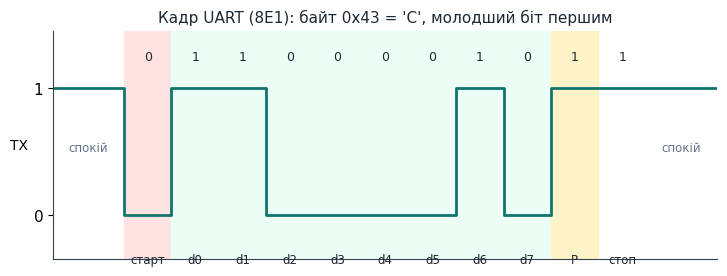

In [14]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _wave(ax, changes, t_end, color=ACCENT_DARK, lw=2):
    """changes: [(t, level), ...] — рівень level діє від моменту t до наступної зміни."""
    t = [c[0] for c in changes] + [t_end]
    v = [c[1] for c in changes] + [changes[-1][1]]
    ax.step(t, v, where="post", color=color, lw=lw)

def _style(ax, name):
    ax.set_ylim(-0.35, 1.45); ax.set_yticks([0, 1])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

# Кадр 8E1: передається байт 0x43 ('C') молодшим бітом уперед, парність парна (even)
byte = 0x43
data = [(byte >> i) & 1 for i in range(8)]       # LSB першим
parity = sum(data) % 2                           # even: доповнює кількість одиниць до парної
bits = [0] + data + [parity] + [1]               # старт + дані + парність + стоп
names = ["старт"] + [f"d{i}" for i in range(8)] + ["P", "стоп"]

fig, ax = plt.subplots(figsize=(7.4, 2.9))
changes = [(-1.5, 1)] + [(i, b) for i, b in enumerate(bits)] + [(len(bits), 1)]
_wave(ax, changes, len(bits) + 1.5)
_style(ax, "TX")
for i, (b, n) in enumerate(zip(bits, names)):
    ax.axvline(i, color=GRID, lw=0.8, zorder=0)
    ax.text(i + 0.5, 1.22, str(b), ha="center", fontsize=9, color=TEXT)
    ax.text(i + 0.5, -0.3, n, ha="center", va="top", fontsize=8.5, color=TEXT)
ax.axvspan(0, 1, color="#FEE2E2", zorder=0)
ax.axvspan(1, 9, color="#ECFDF5", zorder=0)
ax.axvspan(9, 10, color="#FEF3C7", zorder=0)
ax.text(-0.75, 0.5, "спокій", ha="center", fontsize=8.5, color="#64748B")
ax.text(len(bits) + 0.75, 0.5, "спокій", ha="center", fontsize=8.5, color="#64748B")
ax.set_xticks([])
ax.set_xlim(-1.5, len(bits) + 1.5)
ax.set_title("Кадр UART (8E1): байт 0x43 = 'C', молодший біт першим", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

*Рисунок 6.1. Лінія в стані «спокою» (idle) утримується високою; старт-біт — перехід у 0, що «попереджає» приймача про початок байта. У прикладі передається байт 0x43 (символ 'C') у форматі 8E1: 8 біт даних молодшим бітом уперед, біт парності P та один стоп-біт. У байті три одиниці, тому при парній парності (even) біт P = 1 — загальна кількість одиниць стає парною.*


### 6.2. Додаткові параметри UART {-}

```python
from machine import UART

uart = UART(
    2,
    baudrate=9600,
    bits=8,            # кількість біт даних (зазвичай 8)
    parity=None,        # контроль парності: None, 0 (парний), 1 (непарний)
    stop=1,              # кількість стоп-бітів: 1 або 2
    tx=17, rx=16,
    timeout=100,         # мс очікування при читанні перед поверненням
)
```

- **Парність (parity)** — простий метод виявлення помилок передачі: додатковий біт, що робить суму одиниць у байті парною/непарною; якщо на прийомі парність не збігається — байт пошкоджений.
- Обидва пристрої в парі повинні мати **однакові** значення `baudrate`, `bits`, `parity` і `stop` — інакше зв'язок не працюватиме навіть при правильному підключенні дротів.


### 6.3. UART0, REPL і додаткові UART {-}

`UART(0)` на більшості плат ESP32 фізично зв'язаний з тим самим USB-мостом, через який працює REPL і виводяться повідомлення `print()` під час звичайної розробки. Використовувати `UART(0)` для власного протоколу зв'язку з іншим пристроєм цілком можливо (як у Лабораторній №3, Завдання 3–4), але слід пам'ятати: усі стандартні `print()`-повідомлення й самого MicroPython підуть тим самим каналом і можуть «змішатися» з даними вашого протоколу.

Для проєктів, де потрібен «чистий» канал зв'язку без утручання службових повідомлень плати, обирають окремий `UART(1)` або `UART(2)` на довільних вільних GPIO — так, як ми робили при з'єднанні двох плат між собою.


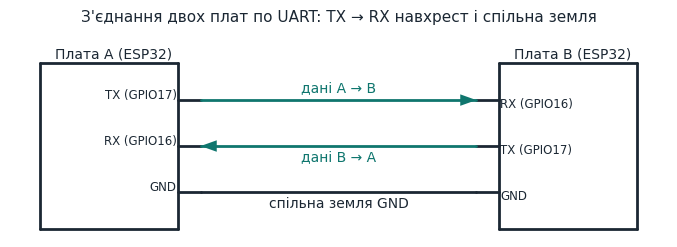

In [15]:
%matplotlib inline
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm

schemdraw.use("matplotlib")
elm.style(elm.STYLE_IEC)          # умовні позначення за ДСТУ/IEC: резистор — прямокутник
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
TEXT = "#1B2733"
schemdraw.config(fontsize=11, color=TEXT)

def chip(d, x, y, w, h, title, pins, title_at="center"):
    """Модуль/мікросхема: прямокутник з виводами довжиною 0.5.
    pins: {ключ: (сторона "L"/"R"/"T"/"B", зсув уздовж сторони від лівого/нижнього кута, підпис)}.
    Повертає словник координат кінців виводів."""
    corners = [(x, y), (x + w, y), (x + w, y + h), (x, y + h), (x, y)]
    for p1, p2 in zip(corners, corners[1:]):
        d += elm.Line().at(p1).to(p2)
    tx, ty, tv = {"center": (x + w / 2, y + h / 2, "center"), "above": (x + w / 2, y + h + 0.15, "bottom"),
                  "below": (x + w / 2, y - 0.15, "top")}[title_at]
    d += elm.Label().at((tx, ty)).label(title, fontsize=10, halign="center", valign=tv)
    ends = {}
    for key, (side, off, text) in pins.items():
        p, out, lab, ha, va = {
            "L": ((x, y + off), (-0.5, 0), (x + 0.12, y + off), "left", "center"),
            "R": ((x + w, y + off), (0.5, 0), (x + w - 0.12, y + off), "right", "center"),
            "T": ((x + off, y + h), (0, 0.5), (x + off, y + h - 0.12), "center", "top"),
            "B": ((x + off, y), (0, -0.5), (x + off, y + 0.12), "center", "bottom"),
        }[side]
        q = (p[0] + out[0], p[1] + out[1])
        d += elm.Line().at(p).to(q)
        d += elm.Label().at(lab).label(text, fontsize=8.5, halign=ha, valign=va)
        ends[key] = q
    return ends

with schemdraw.Drawing(show=False, unit=2.5) as d:
    a = chip(d, 0, 0, 3.0, 3.6, "Плата A (ESP32)", {
        "TX": ("R", 2.8, "TX (GPIO17)"), "RX": ("R", 1.8, "RX (GPIO16)"), "GND": ("R", 0.8, "GND")}, title_at="above")
    b = chip(d, 10, 0, 3.0, 3.6, "Плата B (ESP32)", {
        "RX": ("L", 2.8, "RX (GPIO16)"), "TX": ("L", 1.8, "TX (GPIO17)"), "GND": ("L", 0.8, "GND")}, title_at="above")
    # TX однієї плати — до RX іншої («навхрест»); стрілка показує напрямок даних
    d += elm.Line().at(a["TX"]).to(b["RX"]).color(ACCENT_DARK).label("дані A → B", fontsize=10)
    d += elm.Arrowhead(headwidth=0.25, headlength=0.35).at(b["RX"]).right().color(ACCENT_DARK)
    d += elm.Line().at(b["TX"]).to(a["RX"]).color(ACCENT_DARK).label("дані B → A", fontsize=10, loc="bottom")
    d += elm.Arrowhead(headwidth=0.25, headlength=0.35).at(a["RX"]).left().color(ACCENT_DARK)
    d += elm.Line().at(a["GND"]).to(b["GND"]).label("спільна земля GND", fontsize=10, loc="bottom")
bb = d.get_bbox()                 # розмір рисунка — за габаритами схеми, не ширше 8.5 дюйма
k = min(0.5, 8.5 / (bb.xmax - bb.xmin))
fig, ax = plt.subplots(figsize=((bb.xmax - bb.xmin) * k + 0.4, (bb.ymax - bb.ymin) * k + 0.8))
d.draw(canvas=ax)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("З'єднання двох плат по UART: TX → RX навхрест і спільна земля", fontsize=11, color=TEXT, pad=24)
plt.tight_layout()
plt.show()

*Рисунок 6.2. Типова помилка новачків — з'єднати TX з TX і RX з RX; правильно завжди навхрест (TX однієї плати — до RX іншої), і обов'язково зі спільною землею GND, інакше рівні напруги «пливтимуть» і зв'язок буде нестабільним.*


### 6.4. Надійність простого протоколу {-}

UART сам собою не гарантує доставку повідомлення — якщо приймач тимчасово «зайнятий» або дріт відключений на мить, дані буде втрачено без жодного попередження. Для підвищення надійності саморобного протоколу застосовують прості прийоми:

- **Термінатор рядка** (`\n`) — приймач читає до символу кінця рядка через `uart.readline()`, тому легко відрізняє одне повідомлення від іншого.
- **Контрольна сума** — додаткове числове поле в кінці повідомлення, яке приймач перераховує самостійно й порівнює; розбіжність означає пошкоджені дані.
- **Підтвердження (ACK)** — приймач надсилає у відповідь коротке повідомлення «отримано», і якщо передавач не отримав підтвердження за розумний час — повторює відправку.

Ці прийоми ми частково застосовували в Лабораторній №3 (Завдання 5) і можемо розширювати в самостійних проєктах.


### 6.5. UART проти нативного USB (CDC) {-}

На класичному ESP32 єдиний спосіб зв'язку з комп'ютером через USB-роз'єм — окрема мікросхема-міст (CP2102, CH340), яка перетворює USB на UART; сам мікроконтролер «бачить» тільки UART. На новіших чипах (ESP32-S2, ESP32-S3, ESP32-C3) є **вбудований апаратний USB**, здатний працювати як USB CDC (Communication Device Class) напряму, без окремого моста. Практично для роботи з REPL/Jupyter різниця непомітна (обидва варіанти виглядають як звичайний послідовний порт у системі), але вбудований USB означає на одну мікросхему менше на платі, потенційно нижчу ціну модуля, і в деяких прошивках — можливість одночасно емулювати кілька USB-пристроїв (наприклад, і послідовний порт, і флеш-накопичувач).


### 6.6. Практичний приклад: простий протокол з контрольною сумою {-}

Розширимо ідею з Розділу 6.4 повноцінним прикладом коду, що перевіряє цілісність кожного повідомлення перед його обробкою:

```python
from machine import UART
import time

uart = UART(2, baudrate=115200, tx=17, rx=16)

def checksum(payload: str) -> int:
    return sum(payload.encode()) % 256

def send(payload: str):
    line = f"{payload}*{checksum(payload)}\n"
    uart.write(line)

def try_receive():
    if not uart.any():
        return None
    line = uart.readline()
    if not line:
        return None
    try:
        text = line.decode().strip()
        payload, chk = text.rsplit("*", 1)
        if checksum(payload) == int(chk):
            return payload
        print("Пошкоджене повідомлення, відкинуто:", text)
    except (ValueError, UnicodeError):
        print("Некоректний формат рядка:", line)
    return None

# Передавач:
send("TEMP:23.4")

# Приймач (в іншому місці / на іншій платі):
while True:
    msg = try_receive()
    if msg:
        print("Прийнято й перевірено:", msg)
    time.sleep_ms(50)
```

Формат `<дані>*<контрольна сума>\n` — простий, людинозрозумілий (видно в Serial Monitor «як є») і достатній для навчальних і більшості аматорських проєктів; для промислових застосунків використовують стандартизованіші протоколи (Modbus, CRC-16 тощо).


### 6.7. Вплив довжини та якості проводів {-}

UART без додаткових заходів захисту (на відміну від промислового RS-485) розрахований на короткі відстані — типово до кількох метрів на високих швидкостях (115200 біт/с і вище) звичайним нескрученим дротом. На довших лініях або в умовах електромагнітних завад (поруч із двигунами, потужними реле) сигнал спотворюється, і приймач починає отримувати биті помилки чи «сміття». Практичні поради:
- на прототипній макетній платі тримайте провід UART якомога коротшим;
- при потребі передавати дані на десятки метрів — знижуйте швидкість (наприклад, до 9600 біт/с) або переходьте на диференціальний інтерфейс на кшталт RS-485, стійкіший до завад;
- за можливості уникайте прокладання проводів UART паралельно й впритул до силових кабелів двигунів чи реле.


### 6.8. Коли UART — не найкращий вибір {-}

UART зручний завдяки простоті (лише два дроти для даних плюс земля, немає потреби узгоджувати адреси пристроїв), але має природні межі застосування:
- **Більше двох пристроїв на одній лінії** — стандартний UART розрахований рівно на пару «передавач-приймач»; для мережі з кількома пристроями природніше підходять I2C (Розділ 7) чи SPI (Розділ 8), де адресація чи вибір пристрою вбудовані в сам протокол.
- **Дуже високі швидкості передачі** (мегабайти на секунду, наприклад для дисплеїв чи SD-карток) — тут SPI (Розділ 8) зазвичай ефективніший завдяки апаратному тактовому сигналу.
- **Гарантована доставка без власноруч написаного протоколу** — якщо потрібна вбудована перевірка цілісності й підтвердження без ручної реалізації (Розділ 6.4), варто розглянути мережеві протоколи вищого рівня (наприклад, поверх Wi-Fi, Розділ 14), де ці механізми вже є в стеку TCP.


### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому UART називають асинхронним протоколом і яку роль у ньому відіграє baud rate?</summary>

> **Відповідь:** Бо передавач і приймач не мають спільної лінії тактування (на відміну від SPI) — кожна сторона самостійно відраховує тривалість одного біта на основі наперед узгодженої швидкості (baud rate).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Що станеться, якщо швидкості передавача й приймача на UART не збігаються?</summary>

> **Відповідь:** Приймач невірно визначає межі бітів і отримує «сміття» замість даних.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Для чого призначений біт парності і як він допомагає виявити помилку передачі?</summary>

> **Відповідь:** Це простий метод виявлення помилок: додатковий біт робить суму одиниць у байті парною/непарною; якщо на прийомі парність не збігається — байт вважається пошкодженим.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Які параметри UART обов'язково повинні збігатись з обох сторін з'єднання?</summary>

> **Відповідь:** `baudrate`, `bits`, `parity` і `stop` — інакше зв'язок не працюватиме навіть при правильному підключенні дротів.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому використання UART0 для власного протоколу може ускладнити налагодження коду?</summary>

> **Відповідь:** UART0 фізично зв'язаний з тим самим USB-мостом, через який працює REPL і виводяться повідомлення `print()`, тому службові повідомлення плати можуть «змішатися» з даними власного протоколу.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Чим ризикована передача даних по UART без будь-якого механізму підтвердження чи контрольної суми?</summary>

> **Відповідь:** UART сам собою не гарантує доставку повідомлення — якщо приймач тимчасово зайнятий або дріт відключений на мить, дані буде втрачено без жодного попередження.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Опишіть, як термінатор рядка допомагає приймачу коректно розбирати повідомлення.</summary>

> **Відповідь:** Термінатор (`\n`) дозволяє приймачу читати через `uart.readline()` до символу кінця рядка, тому легко відрізнити одне повідомлення від іншого.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Запропонуйте власний простий протокол обміну (формат повідомлення) для передачі показань двох датчиків одним UART-каналом.</summary>

> **Відповідь:** *Відкрите завдання — єдиної «правильної» відповіді немає.* Один з варіантів за аналогією з форматом розділу 6.6: `<ID_давача>:<значення>*<контрольна_сума>\n`, наприклад `T:23.4*118\n` для температури й `H:60*94\n` для вологості — ідентифікатор дозволяє приймачу розрізняти показання різних давачів у спільному потоці.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Чому TX однієї плати з'єднують саме з RX іншої (навхрест), а не TX з TX?</summary>

> **Відповідь:** TX (transmit) — вихід, RX (receive) — вхід; для передачі даних вихід передавача повинен бути з'єднаний зі входом приймача. З'єднання TX-TX або RX-RX з'єднує два виходи або два входи між собою, і зв'язок не працюватиме.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 10.</b> У яких ситуаціях краще обрати I2C або SPI замість UART?</summary>

> **Відповідь:** Коли на одній лінії потрібно кілька пристроїв одночасно (стандартний UART розрахований лише на пару «передавач-приймач») або коли потрібна дуже висока швидкість передачі (наприклад, для дисплеїв чи SD-карток) — тоді SPI зазвичай ефективніший завдяки апаратному тактовому сигналу.

</details>


```{=latex}
\end{selfcheckbox}
```

# 📘 Розділ 7. Шина I2C

### Після опрацювання розділу ви зможете: {-}
- пояснити принцип адресації пристроїв на спільній шині I2C
- розрізняти програмну (SoftI2C) та апаратну (I2C) реалізації на ESP32
- діагностувати типові проблеми підключення I2C-пристроїв
- оцінювати компроміс між швидкістю і кількістю пристроїв на шині
- обирати резистори підтяжки й тактову частоту відповідно до довжини шини
- читати багатобайтові регістри пристроїв через `readfrom_mem`/`writeto_mem`


### 7.1. Принцип роботи I2C {-}

I2C (Inter-Integrated Circuit) — шина типу «master-slave» на двох спільних лініях (`SDA`, `SCL`), до якої паралельно підключається багато пристроїв. Головний пристрій (master, у нашому випадку — ESP32) ініціює будь-яку передачу і адресує конкретного підпорядкованого учасника (slave) за його унікальною адресою — тому кількість дротів не залежить від кількості пристроїв на шині, на відміну від SPI.

Лінії потребують підтягуючих резисторів до напруги живлення (типово 4.7 кОм), бо пристрої на I2C керують лінією лише «притягуючи до нуля» (open-drain), а повертають її до одиниці саме резистори підтяжки.

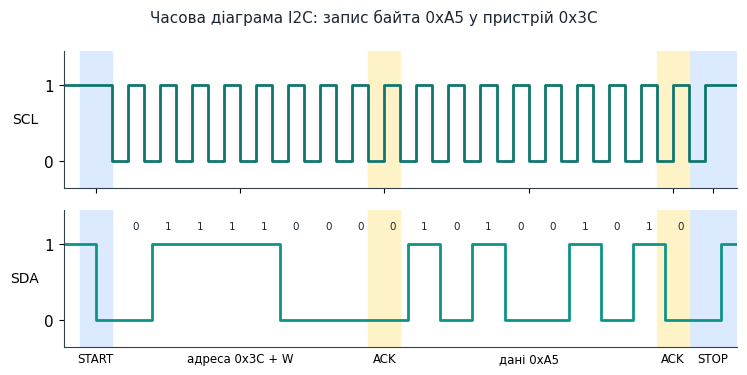

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _wave(ax, changes, t_end, color=ACCENT_DARK, lw=2):
    """changes: [(t, level), ...] — рівень level діє від моменту t до наступної зміни."""
    t = [c[0] for c in changes] + [t_end]
    v = [c[1] for c in changes] + [changes[-1][1]]
    ax.step(t, v, where="post", color=color, lw=lw)

def _style(ax, name):
    ax.set_ylim(-0.35, 1.45); ax.set_yticks([0, 1])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

# Запис одного байта 0xA5 у пристрій з адресою 0x3C (типова адреса OLED SSD1306).
# Кожен біт займає 2 одиниці часу: SCL низький [t, t+1), високий [t+1, t+2).
# SDA змінюється лише посередині низького рівня SCL і стабільний, поки SCL високий.
addr, data = 0x3C, 0xA5
bits = [(addr >> (6 - i)) & 1 for i in range(7)] + [0]            # 7 біт адреси + R/W = 0 (запис)
bits += [0]                                                       # ACK від підпорядкованого
bits += [(data >> (7 - i)) & 1 for i in range(8)] + [0]           # 8 біт даних (старший першим) + ACK
labels = [f"A{6 - i}" for i in range(7)] + ["W", "ACK"] + [f"D{7 - i}" for i in range(8)] + ["ACK"]
t0 = 2                                                            # початок першого біта
n = len(bits)
t_stop = t0 + 2 * n

scl = [(-1, 1), (t0, 0)]
for k in range(n):
    scl += [(t0 + 2 * k + 1, 1), (t0 + 2 * k + 2, 0)]
scl += [(t_stop + 1, 1)]

sda = [(-1, 1), (1, 0)]                                           # START: SDA ↓, поки SCL = 1
for k, b in enumerate(bits):
    sda.append((t0 + 2 * k + 0.5, b))
sda += [(t_stop + 0.5, 0), (t_stop + 2, 1)]                       # STOP: SDA ↑, поки SCL = 1

fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.6, 3.8), sharex=True)
_wave(a1, scl, t_stop + 3, color=ACCENT_DARK)
_wave(a2, sda, t_stop + 3, color=ACCENT)
_style(a1, "SCL"); _style(a2, "SDA")
for ax in (a1, a2):
    ax.axvspan(0, t0, color="#DBEAFE", zorder=0)
    ax.axvspan(t_stop, t_stop + 3, color="#DBEAFE", zorder=0)
    for k, lab in enumerate(labels):
        if lab == "ACK":
            ax.axvspan(t0 + 2 * k, t0 + 2 * k + 2, color="#FEF3C7", zorder=0)
for k, (b, lab) in enumerate(zip(bits, labels)):
    a2.text(t0 + 2 * k + 1.5, 1.2, str(b), ha="center", fontsize=7.5, color=TEXT)
a2.set_xticks([1, t0 + 8, t0 + 17, t0 + 26, t0 + 35, t_stop + 1.5])
a2.set_xticklabels(["START", "адреса 0x3C + W", "ACK", "дані 0xA5", "ACK", "STOP"], fontsize=8.5)
a2.tick_params(axis="x", length=0)
a2.set_xlim(-1, t_stop + 3)
fig.suptitle("Часова діаграма I2C: запис байта 0xA5 у пристрій 0x3C", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

На діаграмі вище показано повний цикл запису одного байта: `SDA` падає, поки `SCL` ще високий (умова **START**); далі йдуть 8 тактів `SCL` для адреси (7 біт адреси + 1 біт напряму R/W) і 9-й такт — підтвердження **ACK**, коли приймач сам тримає `SDA` низько; потім 8 тактів даних і знову 9-й такт **ACK**; насамкінець `SDA` підіймається, поки `SCL` високий (умова **STOP**) — так лінія повертається у вихідний («неактивний») стан. Зверніть увагу: під час передачі біта `SDA` змінюється лише тоді, коли `SCL` низький; зміна `SDA` при високому `SCL` — це завжди START або STOP.

### 7.2. Апаратний I2C проти SoftI2C {-}

MicroPython на ESP32 надає два способи роботи з I2C:
```python
from machine import I2C, SoftI2C, Pin

# Апаратний I2C — використовує вбудований периферійний блок чипа
i2c_hw = I2C(0, scl=Pin(22), sda=Pin(21), freq=400000)

# Програмний I2C — емулює протокол програмно на довільних пінах
i2c_sw = SoftI2C(scl=Pin(25), sda=Pin(26), freq=100000)
```
| | Апаратний I2C | SoftI2C |
|---|---|---|
| Швидкість і стабільність | вища, менше навантаження на процесор | нижча, залежить від точності програмних затримок |
| Вибір пінів | обмежений конкретними виводами чипа | практично будь-які вільні GPIO |
| Кількість незалежних шин одночасно | обмежена кількістю апаратних блоків | необмежена (кожна — окремий об'єкт) |

Апаратний I2C обирають за замовчуванням; SoftI2C — коли апаратні піни вже зайняті іншою периферією, або потрібно кілька незалежних шин одночасно.

### 7.3. Діагностика проблем I2C {-}

Найпоширеніший перший крок при роботі з новим I2C-пристроєм — сканування шини (`i2c.scan()`, як у Лабораторній №4). Якщо пристрій не знайдено:

1. Перевірте, чи не переплутані `SDA`/`SCL` місцями.
2. Перевірте наявність підтягуючих резисторів (на готових модулях вони зазвичай вже впаяні; при самостійному монтажі на макетній платі — можуть бути відсутні).
3. Перевірте живлення модуля (деякі I2C-пристрої розраховані на 5 В, інші — на 3.3 В; невідповідна напруга живлення — часта причина «мовчання» пристрою).
4. Перевірте спільну «землю» (GND) між платою й модулем — без спільного GND сигнальні рівні не мають опорної точки.
5. Якщо кілька пристроїв мають однакову фіксовану адресу (наприклад два однакові давачі), потрібен пристрій із перемичкою для зміни адреси, або окрема шина `SoftI2C` для кожного.

### 7.4. Мультиплексування I2C при конфлікті адрес {-}

Іноді потрібно підключити кілька **однакових** I2C-давачів з однаковою фіксованою адресою (наприклад, два датчики відстані одного типу). Оскільки на одній шині I2C кожна адреса має бути унікальною, є три типові розв'язки:
1. **Апаратний мультиплексор** (наприклад, мікросхема TCA9548A) — підключається як звичайний I2C-пристрій зі своєю адресою, а вже до нього підключаються кілька незалежних «під-шин», між якими мультиплексор перемикається програмно.
2. **Кілька незалежних шин `SoftI2C`** — кожен давач на своїй парі GPIO-пінів (обмежено кількістю вільних пінів).
3. **Зміна адреси програмно/перемичкою** — деякі давачі мають вивід `ADDR` або DIP-перемикач, що дозволяє вибрати одну з 2–4 альтернативних адрес.

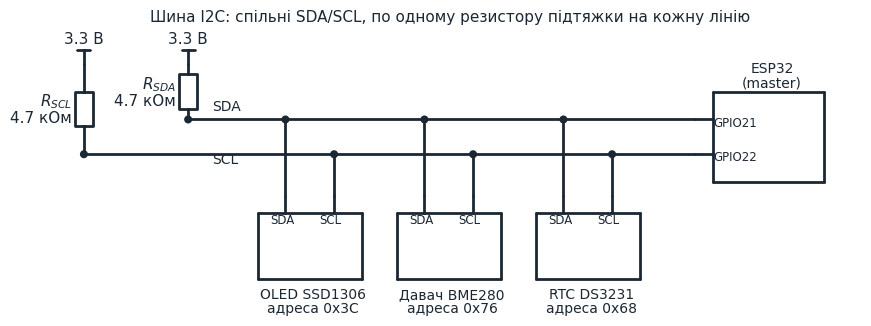

In [17]:
%matplotlib inline
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm

schemdraw.use("matplotlib")
elm.style(elm.STYLE_IEC)          # умовні позначення за ДСТУ/IEC: резистор — прямокутник
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
TEXT = "#1B2733"
schemdraw.config(fontsize=11, color=TEXT)

def chip(d, x, y, w, h, title, pins, title_at="center"):
    """Модуль/мікросхема: прямокутник з виводами довжиною 0.5.
    pins: {ключ: (сторона "L"/"R"/"T"/"B", зсув уздовж сторони від лівого/нижнього кута, підпис)}.
    Повертає словник координат кінців виводів."""
    corners = [(x, y), (x + w, y), (x + w, y + h), (x, y + h), (x, y)]
    for p1, p2 in zip(corners, corners[1:]):
        d += elm.Line().at(p1).to(p2)
    tx, ty, tv = {"center": (x + w / 2, y + h / 2, "center"), "above": (x + w / 2, y + h + 0.15, "bottom"),
                  "below": (x + w / 2, y - 0.15, "top")}[title_at]
    d += elm.Label().at((tx, ty)).label(title, fontsize=10, halign="center", valign=tv)
    ends = {}
    for key, (side, off, text) in pins.items():
        p, out, lab, ha, va = {
            "L": ((x, y + off), (-0.5, 0), (x + 0.12, y + off), "left", "center"),
            "R": ((x + w, y + off), (0.5, 0), (x + w - 0.12, y + off), "right", "center"),
            "T": ((x + off, y + h), (0, 0.5), (x + off, y + h - 0.12), "center", "top"),
            "B": ((x + off, y), (0, -0.5), (x + off, y + 0.12), "center", "bottom"),
        }[side]
        q = (p[0] + out[0], p[1] + out[1])
        d += elm.Line().at(p).to(q)
        d += elm.Label().at(lab).label(text, fontsize=8.5, halign=ha, valign=va)
        ends[key] = q
    return ends

with schemdraw.Drawing(show=False, unit=2.0) as d:
    Y_SDA, Y_SCL, X_END = 2.0, 1.0, 17.6
    # Резистори підтяжки — по одному на кожну лінію шини, до +3.3 В
    d += elm.Vdd().at((0, 3.6)).label("3.3 В")
    d += elm.Resistor().down(2.6).label("$R_{SCL}$\n4.7 кОм", loc="top")
    d += elm.Dot()
    d += elm.Line().to((X_END, Y_SCL))
    d += elm.Vdd().at((3.0, 3.6)).label("3.3 В")
    d += elm.Resistor().down(1.6).label("$R_{SDA}$\n4.7 кОм", loc="top")
    d += elm.Dot()
    d += elm.Line().to((X_END, Y_SDA))
    d += elm.Label().at((3.6, Y_SDA + 0.25)).label("SDA", fontsize=10, halign="left")
    d += elm.Label().at((3.6, Y_SCL - 0.25)).label("SCL", fontsize=10, halign="left")
    # Підпорядковані пристрої (slave) під шиною: кожен з'єднаний з обома лініями
    for x, name in [(5.0, "OLED SSD1306\nадреса 0x3C"), (9.0, "Давач BME280\nадреса 0x76"),
                    (13.0, "RTC DS3231\nадреса 0x68")]:
        p = chip(d, x, -2.6, 3.0, 1.9, name, {"SDA": ("T", 0.8, "SDA"), "SCL": ("T", 2.2, "SCL")}, title_at="below")
        d += elm.Line().at(p["SDA"]).toy(Y_SDA)
        d += elm.Dot()
        d += elm.Line().at(p["SCL"]).toy(Y_SCL)
        d += elm.Dot()
    # Master праворуч: шина підходить до його виводів без перетинів
    chip(d, X_END + 0.5, 0.2, 3.2, 2.6, "ESP32\n(master)", {
        "SDA": ("L", Y_SDA - 0.2, "GPIO21"), "SCL": ("L", Y_SCL - 0.2, "GPIO22")}, title_at="above")
bb = d.get_bbox()                 # розмір рисунка — за габаритами схеми, не ширше 8.5 дюйма
k = min(0.5, 8.5 / (bb.xmax - bb.xmin))
fig, ax = plt.subplots(figsize=((bb.xmax - bb.xmin) * k + 0.4, (bb.ymax - bb.ymin) * k + 0.8))
d.draw(canvas=ax)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Шина I2C: спільні SDA/SCL, по одному резистору підтяжки на кожну лінію",
                 fontsize=11, color=TEXT, pad=12)
plt.tight_layout()
plt.show()

### 7.5. Тактові частоти та вибір резисторів підтяжки {-}

Специфікація I2C-bus визначає кілька стандартних режимів швидкості: **Standard-mode** (до 100 кГц), **Fast-mode** (до 400 кГц) і **Fast-mode Plus** (до 1 МГц) — саме ці значення передають у параметр `freq` конструктора `I2C`/`SoftI2C`. Реальна максимальна частота, яку витримає конкретна шина, залежить не лише від давача, а й від опору резисторів підтяжки та ємності самої шини (довжини дротів, кількості підключених пристроїв):

- **Занадто великий опір** — лінія повільно «підтягується» назад до одиниці (постійна часу RC-кола зростає), і на високій частоті сигнал просто не встигає досягти порогового рівня до наступного такту — виникають помилки зчитування.
- **Занадто малий опір** — зростає струм, що протікає через відкритий (притягнутий до нуля) вихід пристрою, збільшується споживання і тепловиділення, а деякі мікросхеми мають обмеження на максимальний струм такого виходу.

Конкретне значення підбирають за таблицями зі специфікації I2C-bus (NXP UM10204) залежно від довжини шини й потрібної швидкості; **4.7 кОм** — типовий безпечний вибір для короткої шини (макетна плата, кілька давачів) на Standard/Fast-mode, який підходить для більшості навчальних проєктів.

### 7.6. Clock stretching {-}

Деякі I2C-пристрої не встигають обробити дані в темпі, який задає master, і тимчасово **тримають лінію `SCL` низько**, змушуючи master почекати — це називається **clock stretching**. Коректна реалізація master (у тому числі апаратний I2C-периферійний блок ESP32) перевіряє, що `SCL` дійсно піднявся до одиниці, перш ніж вважати такт завершеним, і просто чекає, поки повільний пристрій сам відпустить лінію.

На практиці це проявляється рідко, але варто пам'ятати: якщо пристрій «зависає» надовго (несправність або помилка в його власній прошивці) й тримає `SCL` низько занадто довго, обмін перериється з помилкою `OSError`, а сама шина може здаватись «зайнятою» для інших пристроїв, доки її не звільнять (деякі бібліотеки для відновлення такої ситуації примусово «розхитують» `SCL` кількома імпульсами вручну).

### 7.7. Читання багатобайтових регістрів: `readfrom_mem`/`writeto_mem` {-}

Більшість реальних I2C-давачів (не лише проста EEPROM з прикладу нижче) організовані як набір **регістрів**, що адресуються одним байтом: спочатку master пише адресу потрібного регістра, а потім читає з нього один або кілька байтів. Замість ручного виклику `writeto()` і `readfrom()` окремо, MicroPython надає для цього готові методи:

```python
from machine import I2C, Pin
import struct

i2c = I2C(0, scl=Pin(22), sda=Pin(21))
SENSOR_ADDR = 0x76
TEMP_REG = 0xFA

# читає 3 байти, починаючи з регістра TEMP_REG, за один виклик
raw = i2c.readfrom_mem(SENSOR_ADDR, TEMP_REG, 3)

# запис одного байта в регістр конфігурації (наприклад, режиму роботи)
i2c.writeto_mem(SENSOR_ADDR, 0xF4, bytes([0x27]))
```

Ці методи виконують той самий «запис адреси регістра, потім читання» під капотом, але без потреби вручну керувати `writeto`/`readfrom` і слідкувати за repeated START — тому для будь-якого регістрового давача варто починати саме з них, а не з низькорівневих `writeto`/`readfrom`, які лишаються потрібними хіба для нестандартних протоколів (як у прикладі з EEPROM нижче, де запис адреси і даних об'єднано в один пакет).

### 7.8. Практичний приклад: власний міні-драйвер для I2C EEPROM {-}

Не для кожного I2C-пристрою існує готова бібліотека — часто доводиться писати простий драйвер самостійно за документацією (datasheet) мікросхеми. Розглянемо спрощений приклад для типової I2C EEPROM (енергонезалежна пам'ять, що зберігає дані навіть без живлення):

```python
from machine import I2C, Pin
import time

i2c = I2C(0, scl=Pin(22), sda=Pin(21))
EEPROM_ADDR = 0x50          # типова адреса для мікросхем родини 24LCxx

def eeprom_write_byte(mem_addr, value):
    i2c.writeto(EEPROM_ADDR, bytes([mem_addr, value]))
    time.sleep_ms(5)          # мікросхемі потрібен час на внутрішній запис

def eeprom_read_byte(mem_addr):
    i2c.writeto(EEPROM_ADDR, bytes([mem_addr]))
    return i2c.readfrom(EEPROM_ADDR, 1)[0]

eeprom_write_byte(0, 42)
print("Прочитано з EEPROM:", eeprom_read_byte(0))
```

Загальний рецепт написання власного драйвера: (1) знайти datasheet мікросхеми, (2) знайти в ньому таблицю адрес внутрішніх регістрів і формат команд, (3) реалізувати мінімальний набір функцій (`write`/`read`) через `i2c.writeto()`/`i2c.readfrom()` (або `writeto_mem`/`readfrom_mem`, якщо мікросхема саме регістрового типу), орієнтуючись на цю таблицю.

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому на шині I2C кількість дротів не залежить від кількості підключених пристроїв?</summary>

> **Відповідь:** Бо I2C — шина типу master-slave на двох спільних лініях (`SDA`, `SCL`); головний пристрій адресує конкретного учасника за унікальною адресою, тому додавання нових пристроїв не вимагає нових дротів (на відміну від SPI).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Навіщо потрібні підтягуючі резистори на лініях SDA/SCL і що станеться без них?</summary>

> **Відповідь:** Пристрої на I2C керують лінією лише «притягуючи до нуля» (open-drain), а повертають її до одиниці саме резистори підтяжки. Без них лінія не матиме визначеного високого рівня, і зв'язок не працюватиме.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Порівняйте апаратний I2C і SoftI2C за швидкістю, гнучкістю вибору пінів і кількістю одночасних шин.</summary>

> **Відповідь:** Апаратний I2C — вища швидкість і стабільність, менше навантаження на процесор, але обмежений вибір пінів і обмежена кількість одночасних шин (апаратних блоків). SoftI2C — нижча швидкість (залежить від точності програмних затримок), зате практично будь-які вільні GPIO і необмежена кількість одночасних шин (кожна — окремий об'єкт).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> У якій ситуації доцільно обрати SoftI2C замість апаратного I2C?</summary>

> **Відповідь:** Коли апаратні піни I2C вже зайняті іншою периферією, або коли потрібно кілька незалежних шин одночасно.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Опишіть покроковий алгоритм діагностики, якщо `i2c.scan()` повертає порожній список.</summary>

> **Відповідь:** 1) Перевірити, чи не переплутані SDA/SCL місцями; 2) перевірити наявність підтягуючих резисторів; 3) перевірити живлення модуля (5 В чи 3.3 В); 4) перевірити спільний GND між платою й модулем; 5) якщо кілька пристроїв мають однакову фіксовану адресу — потрібен пристрій зі зміною адреси або окрема SoftI2C-шина.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Що робити, якщо потрібно підключити два однакові I2C-датчики з однаковою фіксованою адресою?</summary>

> **Відповідь:** Один з трьох варіантів: апаратний мультиплексор (наприклад TCA9548A); кілька незалежних шин SoftI2C (по одній на давач); або зміна адреси програмно/перемичкою, якщо давач це підтримує (вивід ADDR чи DIP-перемикач).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Яку роль відіграє спільний GND між платою та I2C-модулем?</summary>

> **Відповідь:** Без спільного GND сигнальні рівні не мають опорної точки, тому спільна «земля» необхідна для коректної роботи шини.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Що станеться, якщо резистор підтяжки на шині I2C обрати занадто великим або занадто малим?</summary>

> **Відповідь:** Занадто великий опір уповільнює наростання сигналу (зростає постійна часу RC-кола) і на високій частоті лінія не встигає досягти потрібного рівня — виникають помилки. Занадто малий опір збільшує струм через відкритий вихід пристрою й тепловиділення, що може перевищити допустимий струм мікросхеми.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Чим `readfrom_mem`/`writeto_mem` зручніші за окремі виклики `writeto`/`readfrom` при роботі з регістровими давачами?</summary>

> **Відповідь:** Вони виконують типовий шаблон «запис адреси регістра, потім читання/запис даних» за один виклик, без потреби вручну керувати repeated START і послідовністю writeto/readfrom.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 8. Шина SPI

### Після опрацювання розділу ви зможете: {-}
- пояснити принцип роботи SPI та роль лінії CS
- налаштовувати режим SPI (polarity, phase) відповідно до документації пристрою
- порівнювати SPI з I2C за швидкістю, кількістю дротів і масштабованістю
- підключати кілька SPI-пристроїв до однієї шини
- оцінювати практичні обмеження швидкості SPI на макетній платі
- застосовувати SPI для читання ідентифікаційних даних мікросхем


### 8.1. Принцип роботи SPI {-}

SPI (Serial Peripheral Interface) — також шина типу «master-slave», але на відміну від I2C використовує окремі лінії для передачі (`MOSI`) і прийому (`MISO`), спільну лінію тактування (`SCK`), а головне — **окрему лінію вибору (`CS`, Chip Select) для кожного підпорядкованого пристрою**. Дані передаються синхронно з тактовим сигналом: на кожен імпульс `SCK` передається один біт, тому SPI не потребує узгодження швидкості наперед (на відміну від UART) — швидкість визначає сам master.

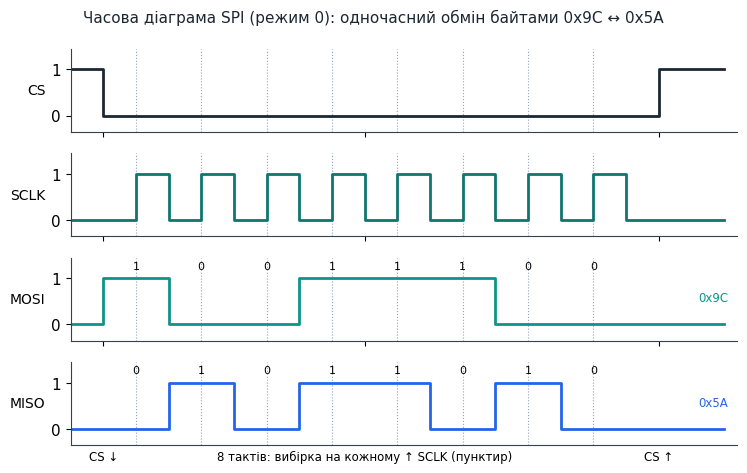

In [18]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _wave(ax, changes, t_end, color=ACCENT_DARK, lw=2):
    """changes: [(t, level), ...] — рівень level діє від моменту t до наступної зміни."""
    t = [c[0] for c in changes] + [t_end]
    v = [c[1] for c in changes] + [changes[-1][1]]
    ax.step(t, v, where="post", color=color, lw=lw)

def _style(ax, name):
    ax.set_ylim(-0.35, 1.45); ax.set_yticks([0, 1])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

# SPI, режим 0 (CPOL = 0, CPHA = 0), старший біт першим.
# Обидві сторони виставляють біт до висхідного фронту SCLK, вибірка — на висхідному фронті (↑),
# наступний біт виставляється на спадному фронті (↓).
mosi_byte, miso_byte = 0x9C, 0x5A
mosi = [(mosi_byte >> (7 - i)) & 1 for i in range(8)]
miso = [(miso_byte >> (7 - i)) & 1 for i in range(8)]
t0 = 1.0                                               # CS ↓
t_end = t0 + 18

cs = [(0, 1), (t0, 0), (t0 + 17, 1)]
sclk = [(0, 0)]
for k in range(8):
    sclk += [(t0 + 1 + 2 * k, 1), (t0 + 2 + 2 * k, 0)]           # ↑ — вибірка, ↓ — зміна даних
mo = [(0, 0)] + [(t0 + 2 * k, b) for k, b in enumerate(mosi)] + [(t0 + 16, 0)]
mi = [(0, 0)] + [(t0 + 2 * k, b) for k, b in enumerate(miso)] + [(t0 + 16, 0)]

fig, axs = plt.subplots(4, 1, figsize=(7.6, 4.8), sharex=True)
for ax, w, name, color in zip(axs, [cs, sclk, mo, mi], ["CS", "SCLK", "MOSI", "MISO"],
                              [TEXT, ACCENT_DARK, ACCENT, "#2563EB"]):
    _wave(ax, w, t_end + 1, color=color)
    _style(ax, name)
    for k in range(8):
        ax.axvline(t0 + 1 + 2 * k, color="#94A3B8", lw=0.8, ls=":", zorder=0)
for k in range(8):
    axs[2].text(t0 + 1 + 2 * k, 1.2, str(mosi[k]), ha="center", fontsize=8)
    axs[3].text(t0 + 1 + 2 * k, 1.2, str(miso[k]), ha="center", fontsize=8)
axs[2].text(t_end + 0.2, 0.5, "0x9C", fontsize=8.5, color=ACCENT)
axs[3].text(t_end + 0.2, 0.5, "0x5A", fontsize=8.5, color="#2563EB")
axs[-1].set_xticks([t0, t0 + 8, t0 + 17])
axs[-1].set_xticklabels(["CS ↓", "8 тактів: вибірка на кожному ↑ SCLK (пунктир)", "CS ↑"], fontsize=8.5)
axs[-1].tick_params(axis="x", length=0)
axs[-1].set_xlim(0, t_end + 1.4)
fig.suptitle("Часова діаграма SPI (режим 0): одночасний обмін байтами 0x9C ↔ 0x5A", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

Діаграма вище показує обмін одним байтом одночасно в обидва боки: поки `CS` опущений (активний), на кожен з 8 тактів `SCLK` master виставляє черговий біт на `MOSI`, а підпорядкований пристрій одночасно виставляє свій біт на `MISO` — обмін повністю дуплексний, на відміну від I2C, де в кожен момент даними обмінюється лише одна сторона.

### 8.2. Апаратний SPI проти SoftSPI {-}

```python
from machine import SPI, SoftSPI, Pin

spi_hw = SPI(1, baudrate=10_000_000, polarity=0, phase=0,
             sck=Pin(18), mosi=Pin(23), miso=Pin(19))

spi_sw = SoftSPI(baudrate=1_000_000, polarity=0, phase=0,
                  sck=Pin(14), mosi=Pin(13), miso=Pin(12))
```
Як і у випадку з I2C, апаратна версія швидша й ефективніша, а програмна — гнучкіша у виборі пінів. Оскільки SPI часто використовують для пристроїв, що вимагають високої пропускної здатності (дисплеї, SD-картки), апаратний варіант застосовують значно частіше, ніж SoftSPI.

### 8.3. Параметри polarity й phase {-}

Параметри `polarity` (CPOL) і `phase` (CPHA) визначають, у який момент відносно тактового сигналу дані вважаються дійсними — так званий «режим SPI» (SPI mode 0–3). Різні мікросхеми розраховані на різні режими, і невідповідність призводить до того, що пристрій «не відповідає» або повертає некоректні дані, хоча підключення фізично правильне:

| Режим | polarity | phase |
|---|---|---|
| Mode 0 | 0 | 0 |
| Mode 1 | 0 | 1 |
| Mode 2 | 1 | 0 |
| Mode 3 | 1 | 1 |

Потрібні значення завжди беруться з документації конкретного пристрою (наприклад, дисплея чи модуля SD-картки) — універсального «правильного» режиму не існує.

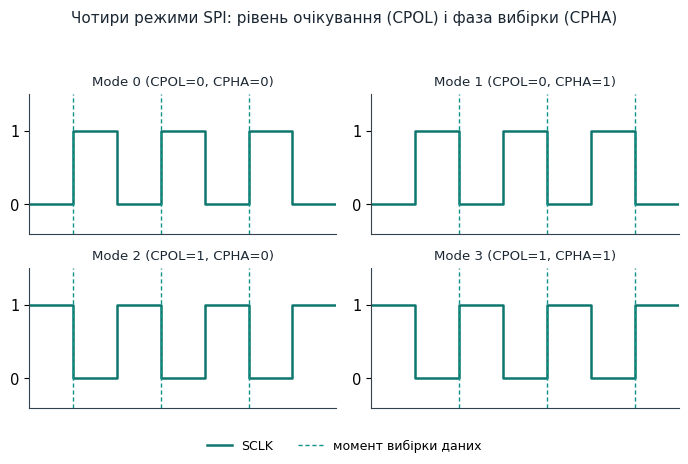

In [19]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"font.size": 10.5, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

modes = [
    (0, 0, "Mode 0 (CPOL=0, CPHA=0)"),
    (0, 1, "Mode 1 (CPOL=0, CPHA=1)"),
    (1, 0, "Mode 2 (CPOL=1, CPHA=0)"),
    (1, 1, "Mode 3 (CPOL=1, CPHA=1)"),
]

fig, axes = plt.subplots(2, 2, figsize=(7, 4.6))

for ax_, (cpol, cpha, title) in zip(axes.flat, modes):
    idle = cpol
    xs, ys = [0], [idle]
    t = 0.5
    sample_points = []
    for i in range(3):
        first_edge_level = 1 - idle
        xs += [t]; ys += [first_edge_level]
        if cpha == 0:
            sample_points.append(t)
        t += 0.5
        xs += [t]; ys += [idle]
        if cpha == 1:
            sample_points.append(t)
        t += 0.5
    xs += [t]; ys += [idle]
    ax_.step(xs, ys, where="post", color=ACCENT_DARK, linewidth=1.8)
    for sp in sample_points:
        ax_.axvline(sp, color=ACCENT, linewidth=1.0, linestyle=(0, (3, 2)))
    ax_.set_ylim(-0.4, 1.5)
    ax_.set_yticks([0, 1])
    ax_.set_xticks([])
    ax_.set_xlim(0, t)
    ax_.set_title(title, fontsize=9.5, color=TEXT)
    ax_.spines[["top", "right"]].set_visible(False)

fig.legend(
    handles=[
        plt.Line2D([0], [0], color=ACCENT_DARK, lw=1.8, label="SCLK"),
        plt.Line2D([0], [0], color=ACCENT, lw=1.0, ls=(0, (3, 2)), label="момент вибірки даних"),
    ],
    loc="lower center", ncol=2, frameon=False, fontsize=9,
)
fig.suptitle("Чотири режими SPI: рівень очікування (CPOL) і фаза вибірки (CPHA)", fontsize=11, color=TEXT, y=0.98)
fig.tight_layout(rect=[0, 0.08, 1, 0.94])
plt.show()


`polarity` визначає рівень `SCLK` у стані спокою (0 чи 1), а `phase` — на якому саме перепаді такту (першому чи другому в межах біта) дані вважаються дійсними й зчитуються. На діаграмі вище пунктирна лінія позначає саме цей момент вибірки для кожного з чотирьох режимів: у Mode 0 і Mode 3 вибірка відбувається на «висхідному» відносно напряму зміни такту фронті, у Mode 1 і Mode 2 — на протилежному.

### 8.4. Кілька пристроїв на одній шині SPI {-}

Лінії `SCK`, `MOSI`, `MISO` є спільними для всіх пристроїв на шині, а `CS` — індивідуальна для кожного:
```python
from machine import SPI, Pin

spi = SPI(1, baudrate=10_000_000, sck=Pin(18), mosi=Pin(23), miso=Pin(19))

cs_display = Pin(5, Pin.OUT, value=1)
cs_sdcard = Pin(15, Pin.OUT, value=1)

def select(cs_pin):
    cs_display.value(1)
    cs_sdcard.value(1)
    cs_pin.value(0)     # активуємо лише потрібний пристрій (сигнал активний по нулю)
```
У стані «неактивно» `CS` тримають у `1` (високий рівень), і лише на час обміну з конкретним пристроєм опускають саме його `CS` до `0` — так шину «чує» лише один пристрій одночасно, і дані не змішуються.

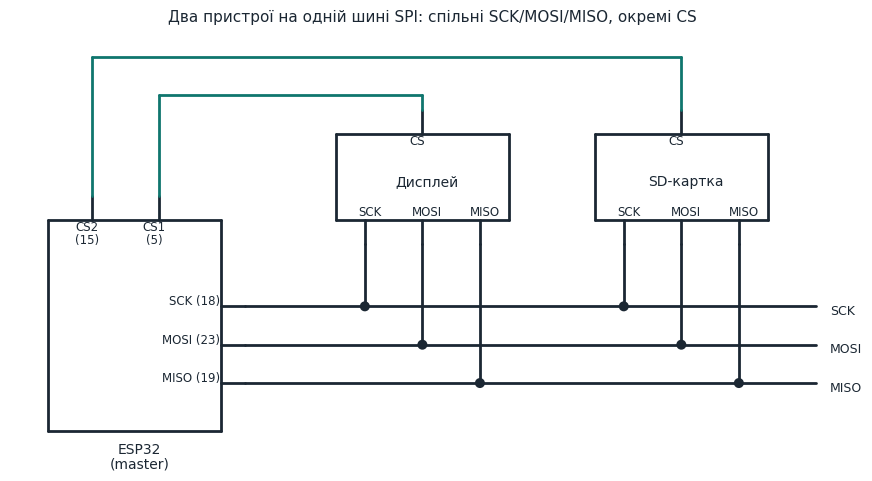

In [20]:
%matplotlib inline
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm

schemdraw.use("matplotlib")
elm.style(elm.STYLE_IEC)          # умовні позначення за ДСТУ/IEC: резистор — прямокутник
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
TEXT = "#1B2733"
schemdraw.config(fontsize=11, color=TEXT)

def chip(d, x, y, w, h, title, pins, title_at="center"):
    """Модуль/мікросхема: прямокутник з виводами довжиною 0.5.
    pins: {ключ: (сторона "L"/"R"/"T"/"B", зсув уздовж сторони від лівого/нижнього кута, підпис)}.
    Повертає словник координат кінців виводів."""
    corners = [(x, y), (x + w, y), (x + w, y + h), (x, y + h), (x, y)]
    for p1, p2 in zip(corners, corners[1:]):
        d += elm.Line().at(p1).to(p2)
    tx, ty, tv = {"center": (x + w / 2, y + h / 2, "center"), "above": (x + w / 2, y + h + 0.15, "bottom"),
                  "below": (x + w / 2, y - 0.15, "top")}[title_at]
    d += elm.Label().at((tx, ty)).label(title, fontsize=10, halign="center", valign=tv)
    ends = {}
    for key, (side, off, text) in pins.items():
        p, out, lab, ha, va = {
            "L": ((x, y + off), (-0.5, 0), (x + 0.12, y + off), "left", "center"),
            "R": ((x + w, y + off), (0.5, 0), (x + w - 0.12, y + off), "right", "center"),
            "T": ((x + off, y + h), (0, 0.5), (x + off, y + h - 0.12), "center", "top"),
            "B": ((x + off, y), (0, -0.5), (x + off, y + 0.12), "center", "bottom"),
        }[side]
        q = (p[0] + out[0], p[1] + out[1])
        d += elm.Line().at(p).to(q)
        d += elm.Label().at(lab).label(text, fontsize=8.5, halign=ha, valign=va)
        ends[key] = q
    return ends

with schemdraw.Drawing(show=False, unit=2.0) as d:
    Y = {"SCK": 2.6, "MOSI": 1.8, "MISO": 1.0}
    m = chip(d, 0, 0, 3.6, 4.4, "ESP32\n(master)", {
        "SCK": ("R", Y["SCK"], "SCK (18)"), "MOSI": ("R", Y["MOSI"], "MOSI (23)"), "MISO": ("R", Y["MISO"], "MISO (19)"),
        "CS2": ("T", 0.9, "CS2\n(15)"), "CS1": ("T", 2.3, "CS1\n(5)")}, title_at="below")
    X_END = 16.0
    for k, y in Y.items():                       # спільні лінії шини
        d += elm.Line().at(m[k]).to((X_END, y))
    slaves = []
    for x, name in [(6.0, "Дисплей"), (11.4, "SD-картка")]:
        s = chip(d, x, 4.4, 3.6, 1.8, name, {
            "CS": ("T", 1.8, "CS"), "SCK": ("B", 0.6, "SCK"), "MOSI": ("B", 1.8, "MOSI"), "MISO": ("B", 3.0, "MISO")})
        for k in ("SCK", "MOSI", "MISO"):
            d += elm.Line().at(s[k]).toy(Y[k])
            d += elm.Dot()
        slaves.append(s)
    # Індивідуальні лінії CS прокладено над пристроями — кожна лише до «свого» пристрою
    for pin, s, y_top in [("CS1", slaves[0], 7.0), ("CS2", slaves[1], 7.8)]:
        d += elm.Line().at(m[pin]).toy(y_top).color(ACCENT_DARK)
        d += elm.Line().tox(s["CS"][0]).color(ACCENT_DARK)
        d += elm.Line().toy(s["CS"][1]).color(ACCENT_DARK)
    d += elm.Label().at((X_END + 0.2, Y["SCK"])).label("SCK", halign="left", fontsize=9)
    d += elm.Label().at((X_END + 0.2, Y["MOSI"])).label("MOSI", halign="left", fontsize=9)
    d += elm.Label().at((X_END + 0.2, Y["MISO"])).label("MISO", halign="left", fontsize=9)
bb = d.get_bbox()                 # розмір рисунка — за габаритами схеми, не ширше 8.5 дюйма
k = min(0.5, 8.5 / (bb.xmax - bb.xmin))
fig, ax = plt.subplots(figsize=((bb.xmax - bb.xmin) * k + 0.4, (bb.ymax - bb.ymin) * k + 0.8))
d.draw(canvas=ax)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Два пристрої на одній шині SPI: спільні SCK/MOSI/MISO, окремі CS",
                 fontsize=11, color=TEXT, pad=12)
plt.tight_layout()
plt.show()

Схема вище відповідає коду: лінії `SCK`, `MOSI`, `MISO` спільні для дисплея й SD-картки, а кожен пристрій має власну лінію `CS` (`GPIO5` і `GPIO15`). Пристрій з неактивним (високим) `CS` переводить свій вихід `MISO` у високоімпедансний стан і не заважає обміну — тому одна шина обслуговує кілька пристроїв без конфліктів.


### 8.5. SPI проти I2C: коли що обирати {-}

| Критерій | I2C | SPI |
|---|---|---|
| Кількість дротів | 2 (спільні для всіх пристроїв) | 3 + по одному CS на пристрій |
| Швидкість | нижча (типово до 400 кБіт/с — 1 МБіт/с) | значно вища (одиниці — десятки МБіт/с) |
| Масштабованість (багато пристроїв) | проста (лише додати новий на ті самі 2 дроти) | вимагає додаткового піна CS на кожен новий пристрій |
| Типове застосування | датчики, RTC-модулі, дисплеї малого обсягу даних | дисплеї TFT, SD-картки, пристрої з великим потоком даних |

### 8.6. Практична межа швидкості SPI {-}

Параметр `baudrate` — це *запит* бажаної частоти, а не гарантія: реальний апаратний блок SPI ESP32 генерує тактову частоту діленням від свого внутрішнього тактового генератора, тому фактично встановлена частота округляється до найближчого досяжного значення (як правило — трохи нижче запитаної).

Значно важливіше на практиці інше обмеження: на макетній платі з довгими проводами-перемичками паразитна ємність і індуктивність довгих провідників спотворюють фронти сигналу тим сильніше, чим вища частота — тому навіть якщо периферійний блок теоретично здатний на десятки МГц, надійна робота на макетці часто обмежується одиницями МГц. Для короткого й акуратного монтажу (плата з дисплеєм, що вставляється напряму) можна працювати на значно вищих частотах, ніж для того самого дисплея, підключеного довгими проводами.

### 8.7. Практичний приклад: зчитування JEDEC ID SPI flash-мікросхеми {-}

Майже всі SPI NOR flash-мікросхеми (наприклад, ті, що використовуються як зовнішня пам'ять для зображень чи вебсторінок) підтримують стандартну команду `0x9F` — читання ідентифікатора виробника й типу мікросхеми (JEDEC ID), яка працює однаково незалежно від конкретної моделі:

```python
from machine import SPI, Pin

spi = SPI(1, baudrate=1_000_000, polarity=0, phase=0,
          sck=Pin(18), mosi=Pin(23), miso=Pin(19))
cs = Pin(5, Pin.OUT, value=1)

def read_jedec_id():
    cs.value(0)
    spi.write(bytes([0x9F]))               # команда "Read JEDEC ID"
    manufacturer_type_capacity = spi.read(3)
    cs.value(1)
    return manufacturer_type_capacity

mfr_id, mem_type, capacity = read_jedec_id()
print(f"Виробник: 0x{mfr_id:02X}, тип: 0x{mem_type:02X}, ємність: 0x{capacity:02X}")
```

Цей приклад — гарний перший тест будь-якої нової SPI-мікросхеми: якщо `read_jedec_id()` повертає `(0xFF, 0xFF, 0xFF)` або `(0x00, 0x00, 0x00)`, це майже завжди означає проблему з підключенням (переплутані `MOSI`/`MISO`, відсутнє живлення чи неправильний `CS`), а не з самою мікросхемою.

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чим лінія CS у SPI принципово відрізняється від принципу адресації в I2C?</summary>

> **Відповідь:** У SPI кожен підпорядкований пристрій вибирається окремою фізичною лінією `CS` (Chip Select), тоді як в I2C усі пристрої ділять спільні лінії, а вибір відбувається через унікальну адресу на цих спільних лініях.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Чому SPI не потребує попереднього узгодження швидкості між пристроями, на відміну від UART?</summary>

> **Відповідь:** Бо SPI передає дані синхронно зі спільним тактовим сигналом (`SCK`) — на кожен імпульс `SCK` передається один біт, тому швидкість визначає сам master у реальному часі, без потреби наперед узгоджувати baud rate, як в UART.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Що визначають параметри polarity і phase та звідки береться потрібне значення для конкретного пристрою?</summary>

> **Відповідь:** Вони визначають, у який момент відносно тактового сигналу дані вважаються дійсними (режим SPI 0–3). Потрібні значення завжди беруться з документації конкретного пристрою — універсального «правильного» режиму не існує.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Опишіть, як коректно перемикатись між двома SPI-пристроями на одній шині, не змішуючи дані.</summary>

> **Відповідь:** Лінії `SCK`, `MOSI`, `MISO` спільні, а `CS` — індивідуальна для кожного пристрою; у неактивному стані всі `CS` тримають високими (1), і лише на час обміну з конкретним пристроєм опускають саме його `CS` до 0, після чого повертають назад до 1.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> У якому стані (0 чи 1) лінію CS тримають, коли пристрій неактивний? Чому?</summary>

> **Відповідь:** У стані 1 (високому), бо сигнал `CS` активний по нулю — опускання до 0 активує саме цей пристрій.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Порівняйте I2C та SPI за швидкістю та зручністю масштабування (додавання нових пристроїв).</summary>

> **Відповідь:** I2C: 2 спільні дроти для всіх пристроїв, проста масштабованість (новий пристрій — ті самі 2 дроти), нижча швидкість (типово до 400 кБіт/с — 1 МБіт/с). SPI: 3 дроти + по одному CS на пристрій, значно вища швидкість (одиниці — десятки МБіт/с), але масштабування вимагає додаткового піна CS на кожен новий пристрій.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Наведіть приклад пристрою, для якого доцільніше обрати SPI, а не I2C, і поясніть чому.</summary>

> **Відповідь:** Дисплей TFT або SD-картка — пристрої з великим потоком даних, для яких важлива значно вища пропускна здатність SPI, як зазначено в таблиці порівняння 8.5.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Чому реальна швидкість SPI на макетній платі з довгими проводами часто значно нижча за теоретичний максимум периферійного блока?</summary>

> **Відповідь:** Довгі проводи-перемички вносять паразитну ємність і індуктивність, які спотворюють фронти сигналу тим сильніше, чим вища частота — тому надійна робота на макетці обмежується значно нижчими частотами, ніж дозволяє сам апаратний блок.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Про що свідчить, якщо читання JEDEC ID (команда 0x9F) повертає лише байти 0xFF або 0x00?</summary>

> **Відповідь:** Це майже завжди ознака проблеми з підключенням (переплутані MOSI/MISO, відсутнє живлення, неправильний CS), а не несправності самої мікросхеми.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 9. Шина I2S та цифровий звук

### Після опрацювання розділу ви зможете: {-}
- пояснити принцип передачі цифрового аудіопотоку через I2S
- розрізняти роль ліній BCK, WS та SD
- описати типові застосування I2S на ESP32 (мікрофони, аудіовихід)
- розраховувати обсяг пам'яті, потрібний для аудіобуфера заданої тривалості
- організовувати потокове (по частинах) відтворення без надлишкового використання RAM


### 9.1. Навіщо потрібна окрема шина для звуку {-}

Звук — це безперервний потік вибірок (samples), що надходять з фіксованою частотою (наприклад, 44100 разів за секунду для якості аудіо-CD). Жодна з розглянутих раніше шин (UART, I2C, SPI) не гарантує настільки строгої й безперервної синхронізації в часі, потрібної, щоб відтворення чи запис звуку не «заїкались». Для цього призначена спеціалізована шина **I2S (Inter-IC Sound)**.

### 9.2. Лінії I2S {-}

| Лінія | Призначення |
|---|---|
| `SCK`/`BCK` (Bit Clock) | тактовий сигнал для кожного окремого біта аудіоданих |
| `WS` (Word Select) | визначає, до якого каналу (лівого чи правого) належить поточна вибірка |
| `SD` (Serial Data) | сам потік аудіоданих |

```python
from machine import I2S, Pin

audio_out = I2S(
    0,
    sck=Pin(14), ws=Pin(15), sd=Pin(22),
    mode=I2S.TX,               # передача (відтворення); I2S.RX — прийом (запис з мікрофона)
    bits=16,                    # розрядність вибірки
    format=I2S.STEREO,
    rate=44100,                 # частота дискретизації, Гц
    ibuf=20000,                  # розмір внутрішнього буфера
)
audio_out.write(audio_bytes)     # надіслати блок готових аудіоданих (bytes)
```

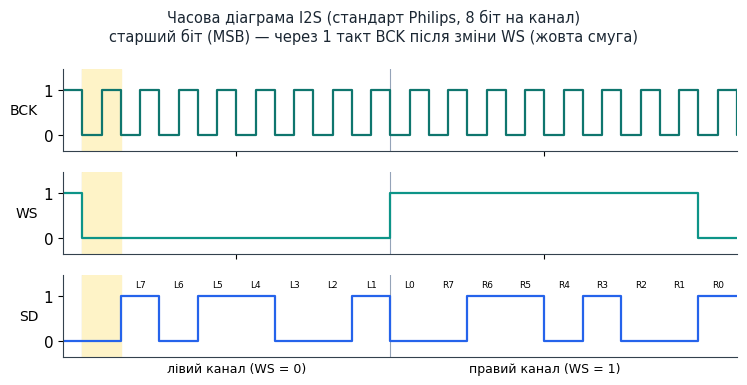

In [21]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _wave(ax, changes, t_end, color=ACCENT_DARK, lw=2):
    """changes: [(t, level), ...] — рівень level діє від моменту t до наступної зміни."""
    t = [c[0] for c in changes] + [t_end]
    v = [c[1] for c in changes] + [changes[-1][1]]
    ax.step(t, v, where="post", color=color, lw=lw)

def _style(ax, name):
    ax.set_ylim(-0.35, 1.45); ax.set_yticks([0, 1])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

# Стандарт I2S (Philips): WS = 0 — лівий канал, WS = 1 — правий.
# WS і SD змінюються на спадному фронті BCK, приймач читає SD на висхідному.
# Старший біт (MSB) слова з'являється через ОДИН такт BCK після зміни WS.
N = 8                                                   # спрощено: 8 біт на канал
left = [1, 0, 1, 1, 0, 0, 1, 0]
right = [0, 1, 1, 0, 1, 0, 0, 1]
T = 2 * N                                               # тривалість слова (1 біт = 2 одиниці часу)
t_end = 2 * T + 3
bck = [(0, 1)]
for k in range(int(t_end / 2) + 1):
    bck += [(2 * k + 1, 0), (2 * k + 2, 1)]
ws = [(0, 1), (1, 0), (1 + T, 1), (1 + 2 * T, 0)]
sd = [(0, 0)]
prev = 0
for k, b in enumerate(left + right + [left[0]]):
    sd.append((1 + 2 * (k + 1), b))                     # зсув на 1 такт відносно WS

fig, axs = plt.subplots(3, 1, figsize=(7.6, 3.9), sharex=True)
for ax, w, name, color in zip(axs, [bck, ws, sd], ["BCK", "WS", "SD"], [ACCENT_DARK, ACCENT, "#2563EB"]):
    _wave(ax, w, t_end, color=color, lw=1.6)
    _style(ax, name)
    ax.axvline(1, color="#94A3B8", lw=0.8, zorder=0)
    ax.axvline(1 + T, color="#94A3B8", lw=0.8, zorder=0)
for k in range(2 * N):
    axs[2].text(1 + 2 * (k + 1) + 1, 1.2, ("L" if k < N else "R") + str(N - 1 - k % N), ha="center", fontsize=6.5)
for ax in axs:
    ax.axvspan(1, 3, color="#FEF3C7", zorder=0)                 # затримка MSB на 1 такт BCK
axs[-1].set_xticks([1 + T / 2, 1 + 1.5 * T])
axs[-1].set_xticklabels(["лівий канал (WS = 0)", "правий канал (WS = 1)"], fontsize=9)
axs[-1].tick_params(axis="x", length=0)
axs[-1].set_xlim(0, t_end)
fig.suptitle("Часова діаграма I2S (стандарт Philips, 8 біт на канал)\nстарший біт (MSB) — через 1 такт BCK після зміни WS (жовта смуга)", fontsize=10.5, color=TEXT)
plt.tight_layout()
plt.show()

Діаграма вище (спрощена до 8 біт на канал замість реальних 16–32) показує головний принцип: `WS` тримається на одному рівні впродовж цілого «слова» (набору біт одного каналу) і перемикається рівно посередині кадру — саме перепад `WS` і повідомляє приймачу «наступні біти — вже для іншого каналу». У стандартному форматі I2S (Philips) старший біт слова передається із затримкою на один такт `BCK` після перепаду `WS`, тому молодший біт лівого каналу (L0) припадає вже на перший такт з `WS = 1`.

### 9.3. Типові застосування {-}

- Підключення цифрового мікрофона (наприклад, INMP441) для запису звуку чи розпізнавання голосових команд.
- Відтворення звуку через зовнішній I2S DAC-модуль (наприклад, MAX98357A) з якістю, значно вищою за простий DAC/PWM-вихід самого ESP32.
- Побудова простих аудіопроєктів «інтернету речей»: голосові сповіщення, розпізнавання простих звукових патернів, мережеві радіоприймачі.

I2S — більш ресурсоємна периферія (потребує суттєвого об'єму пам'яті під буфери й стабільного постачання даних), тому застосовується переважно в проєктах, де саме якісний звук — основна функція пристрою.

### 9.4. DMA та обмеження апаратних буферів {-}

Аудіодані надходять/відправляються безперервним потоком, тому I2S на апаратному рівні спирається на **DMA (Direct Memory Access)** — периферія самостійно читає/пише дані з/у пам'ять, минаючи процесор для кожного окремого байта. Параметр `ibuf` у конструкторі `I2S` (Розділ 9.2) задає розмір цього внутрішнього буфера: занадто малий буфер призводить до переривань/тріску звуку (буфер спорожнюється швидше, ніж програма встигає його поповнювати), занадто великий — витрачає дорогоцінну оперативну пам'ять плати й збільшує затримку (latency) між подією та звуком.

### 9.5. Формати вибірок і байтовий порядок {-}

Параметр `bits` задає розрядність кожної вибірки (найчастіше 16 або 32), а `format` — кількість каналів (`I2S.MONO`/`I2S.STEREO`). Байти вибірки передаються у форматі little-endian (молодший байт першим) — саме тому в прикладі нижче (9.6) значення пакується через `value.to_bytes(2, "little", True)`, де останній аргумент `True` означає «число зі знаком» (signed), бо аудіосигнал коливається навколо нуля в обидва боки.

Деякі зовнішні DAC-мікросхеми вимагають саме 32-бітний кадр на канал, навіть якщо змістовна інформація займає лише 16 біт (решта розрядів — нулі-заповнювачі): такі вимоги завжди беруться з документації конкретного DAC-модуля, а не обираються довільно.

### 9.6. Скільки пам'яті займає звук: практичний розрахунок {-}

Перш ніж будувати аудіопроєкт, корисно прикинути обсяг пам'яті наперед. Одна секунда стереозвуку за параметрами CD-якості (`rate=44100`, `bits=16`, стерео — 2 канали):

$$
44100 \text{ Гц} \times 2 \text{ байти/вибірку} \times 2 \text{ канали} = 176\,400 \text{ байт} \approx 172 \text{ КБ на одну секунду}
$$

ESP32 має лише декілька сотень кілобайтів вільної оперативної пам'яті (значна частина вже зайнята стеком Wi-Fi/Bluetooth та іншими підсистемами) — тому ціла хвилина такого запису (понад 10 МБ) у RAM просто не поміститься. Звідси прямий практичний висновок: короткі звукові ефекти (сигнали, підтвердження) можна тримати в пам'яті цілком, а для музики чи мовлення обов'язково потрібне **потокове відтворення** невеликими частинами (Розділ 9.7), як правило — прямо з файлу на SD-картці (Розділ 12).

### 9.7. Буферизація «на льоту» для тривалого відтворення {-}

```python
from machine import I2S, Pin

i2s = I2S(0, sck=Pin(14), ws=Pin(15), sd=Pin(22),
          mode=I2S.TX, bits=16, format=I2S.STEREO, rate=44100, ibuf=20000)

CHUNK = 4096
with open("/sd/song.pcm", "rb") as f:      # готовий "сирий" PCM-потік без заголовків
    while True:
        chunk = f.read(CHUNK)
        if not chunk:
            break
        i2s.write(chunk)                    # блокується, поки DMA не звільнить місце в буфері

i2s.deinit()
```

Такий підхід («прочитати шматок → надіслати → повторити») тримає в пам'яті одночасно лише один невеликий фрагмент незалежно від загальної тривалості запису — принципова відмінність від підходу з Розділу 9.8, де короткий сигнал обчислюється й тримається в пам'яті цілком заздалегідь.

### 9.8. I2S для прийому: підключення цифрового мікрофона {-}

Режим `I2S.RX` дозволяє записувати звук з цифрового мікрофона (наприклад, INMP441), який на відміну від аналогового не потребує окремого ADC — сам мікрофон вже віддає цифровий I2S-потік:

```python
from machine import I2S, Pin

mic = I2S(0, sck=Pin(14), ws=Pin(15), sd=Pin(32),
          mode=I2S.RX, bits=16, format=I2S.MONO, rate=16000, ibuf=4000)

buf = bytearray(2048)
mic.readinto(buf)      # заповнити буфер сирими даними з мікрофона
mic.deinit()
```

Записаний у `buf` потік — це ті самі байти, що й у прикладі 9.6/9.9 (16-бітні відліки little-endian), тому подальша обробка (пошук піків гучності, найпростіше розпізнавання патернів) працює з ним так само, як і зі згенерованим сигналом.

### 9.9. Практичний приклад: генерація простого тону через I2S {-}

На відміну від PWM-зумера (Розділ 5), I2S дозволяє відтворювати справжню сформовану хвилю (наприклад, синусоїду), а не просто вмикання/вимикання на частоті:

```python
from machine import I2S, Pin
import math

i2s = I2S(0, sck=Pin(14), ws=Pin(15), sd=Pin(22),
          mode=I2S.TX, bits=16, format=I2S.MONO, rate=16000, ibuf=4000)

SAMPLE_RATE = 16000
FREQ = 440                      # нота Ля (A4)
samples = bytearray()
for i in range(SAMPLE_RATE):     # одна секунда звучання
    value = int(3000 * math.sin(2 * math.pi * FREQ * i / SAMPLE_RATE))
    samples += value.to_bytes(2, "little", True)

i2s.write(samples)
i2s.deinit()
```

Обчислення синусоїди наперед (у список/буфер) і лише потім `write()` — типовий підхід для коротких сигналів (тут — рівно 32 КБ, за формулою з Розділу 9.6); для тривалого чи динамічного звуку застосовують потокову передачу частинами, як у Розділі 9.7.

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому для передачі звуку недостатньо шин UART/I2C/SPI і знадобилась окрема шина I2S?</summary>

> **Відповідь:** Звук — це безперервний потік вибірок з фіксованою частотою (наприклад, 44100 разів/с), а жодна з UART/I2C/SPI не гарантує настільки строгої й безперервної синхронізації в часі, потрібної, щоб відтворення чи запис не «заїкались».

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Яку роль виконує лінія WS (Word Select) в I2S?</summary>

> **Відповідь:** Визначає, до якого каналу (лівого чи правого) належить поточна вибірка; перепад WS повідомляє приймачу, що наступні біти належать іншому каналу.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Наведіть два приклади практичного застосування I2S на ESP32.</summary>

> **Відповідь:** Підключення цифрового мікрофона (наприклад INMP441) для запису звуку чи розпізнавання голосових команд; відтворення звуку через зовнішній I2S DAC-модуль (наприклад MAX98357A) з якістю, значно вищою за простий DAC/PWM-вихід.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Чим відрізняються режими `I2S.TX` та `I2S.RX`?</summary>

> **Відповідь:** `I2S.TX` — режим передачі (відтворення звуку), `I2S.RX` — режим прийому (запис звуку, наприклад з мікрофона).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому I2S вважається більш ресурсоємною периферією порівняно з UART чи I2C?</summary>

> **Відповідь:** Бо потребує суттєвого об'єму пам'яті під буфери й стабільного безперервного постачання даних, на відміну від простіших UART чи I2C.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Скільки приблизно байтів пам'яті потрібно для однієї секунди звуку 44100 Гц, 16 біт, стерео? Чому це важливо знати заздалегідь?</summary>

> **Відповідь:** 44100 × 2 байти × 2 канали ≈ 172 КБ на секунду. Важливо тому, що вільної RAM на ESP32 лише кілька сотень КБ, тому будь-який запис довший за кілька секунд не поміститься весь одразу і вимагає потокового відтворення частинами.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> У чому принципова відмінність підходу до відтворення короткого сигналу (Розділ 9.9) від тривалого запису (Розділ 9.7)?</summary>

> **Відповідь:** Короткий сигнал обчислюється наперед і повністю тримається в пам'яті перед одним викликом `write()`; тривалий запис читають і надсилають невеликими частинами по черзі («на льоту»), щоб не тримати весь файл у RAM одночасно.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 10. Спеціалізована периферія: RMT, OneWire, адресні світлодіоди, ємнісні дотики

### Після опрацювання розділу ви зможете: {-}
- пояснити принцип роботи блока RMT і задачі, для яких він застосовується
- описати протокол OneWire та його особливості
- керувати адресними світлодіодними стрічками (NeoPixel/APA106)
- використовувати ємнісні дотикові піни як альтернативу механічним кнопкам
- пояснити часові діаграми ініціалізації OneWire та кодування біт NeoPixel
- враховувати обмеження ємнісних дотикових пінів на різних варіантах ESP32


### 10.1. RMT — генератор точних імпульсних послідовностей {-}

**RMT (Remote Control)** — апаратний блок ESP32, спершу створений для генерації й прийому сигналів інфрачервоних пультів дистанційного керування, але корисний для будь-якого протоколу, що вимагає **точного до наносекунд** формування послідовності імпульсів різної тривалості. Головна перевага RMT — така послідовність генерується апаратно, без участі процесора на кожному імпульсі, що критично важливо для протоколів на кшталт адресних світлодіодів чи давачів OneWire, де навіть невелике відхилення в часі призводить до помилки зчитування.

### 10.2. Протокол OneWire та давач DS18B20 {-}

**OneWire** — протокол, що дозволяє живити пристрій, передавати команди й отримувати дані всього по **одному** сигнальному дроту (плюс спільний GND), за рахунок точного часового кодування бітів. Найпоширеніший приклад — цифровий термометр **DS18B20**:
```python
from machine import Pin
import onewire, ds18x20

ow = onewire.OneWire(Pin(4))
sensors = ds18x20.DS18X20(ow)

roms = sensors.scan()          # кожен давач на шині має власний унікальний 64-бітний ідентифікатор
sensors.convert_temp()          # запустити вимірювання на всіх давачах одночасно
# невелика затримка (мінімум ~750 мс за специфікацією) перед читанням результату
for rom in roms:
    print(sensors.read_temp(rom))
```
Особливість OneWire — на одній лінії можна розмістити **кілька** давачів одночасно, розрізняючи їх за унікальним ідентифікатором (аналогічно до адрес на I2C). Як і на I2C, пристрої лише «притягують» лінію до нуля, тому лінії даних потрібен **один спільний** резистор підтяжки ≈4.7 кОм до 3.3 В на всю шину, а не окремий для кожного давача (схема нижче).

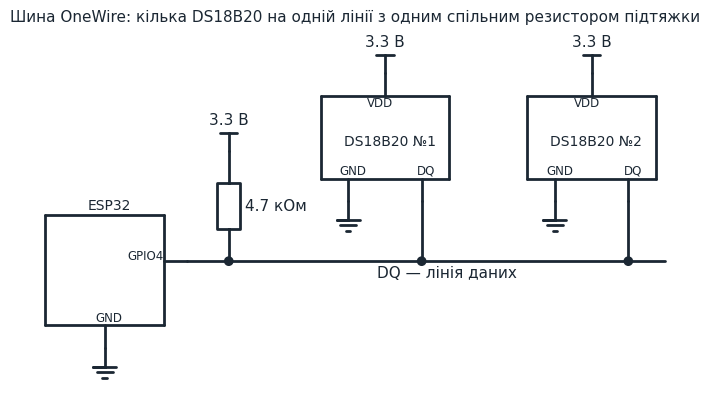

In [22]:
%matplotlib inline
import matplotlib.pyplot as plt
import schemdraw
import schemdraw.elements as elm

schemdraw.use("matplotlib")
elm.style(elm.STYLE_IEC)          # умовні позначення за ДСТУ/IEC: резистор — прямокутник
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
TEXT = "#1B2733"
schemdraw.config(fontsize=11, color=TEXT)

def chip(d, x, y, w, h, title, pins, title_at="center"):
    """Модуль/мікросхема: прямокутник з виводами довжиною 0.5.
    pins: {ключ: (сторона "L"/"R"/"T"/"B", зсув уздовж сторони від лівого/нижнього кута, підпис)}.
    Повертає словник координат кінців виводів."""
    corners = [(x, y), (x + w, y), (x + w, y + h), (x, y + h), (x, y)]
    for p1, p2 in zip(corners, corners[1:]):
        d += elm.Line().at(p1).to(p2)
    tx, ty, tv = {"center": (x + w / 2, y + h / 2, "center"), "above": (x + w / 2, y + h + 0.15, "bottom"),
                  "below": (x + w / 2, y - 0.15, "top")}[title_at]
    d += elm.Label().at((tx, ty)).label(title, fontsize=10, halign="center", valign=tv)
    ends = {}
    for key, (side, off, text) in pins.items():
        p, out, lab, ha, va = {
            "L": ((x, y + off), (-0.5, 0), (x + 0.12, y + off), "left", "center"),
            "R": ((x + w, y + off), (0.5, 0), (x + w - 0.12, y + off), "right", "center"),
            "T": ((x + off, y + h), (0, 0.5), (x + off, y + h - 0.12), "center", "top"),
            "B": ((x + off, y), (0, -0.5), (x + off, y + 0.12), "center", "bottom"),
        }[side]
        q = (p[0] + out[0], p[1] + out[1])
        d += elm.Line().at(p).to(q)
        d += elm.Label().at(lab).label(text, fontsize=8.5, halign=ha, valign=va)
        ends[key] = q
    return ends

with schemdraw.Drawing(show=False, unit=2.0) as d:
    Y_DQ = 1.4
    m = chip(d, 0, 0, 2.6, 2.4, "ESP32", {"DQ": ("R", Y_DQ, "GPIO4"), "GND": ("B", 1.3, "GND")}, title_at="above")
    d += elm.Ground().at(m["GND"])
    d += elm.Line().at(m["DQ"]).right(0.9)
    n = d.add(elm.Dot())
    d += elm.Resistor().at(n.center).up(2.4).label("4.7 кОм", loc="bottom")
    d += elm.Vdd().label("3.3 В")
    d += elm.Line().at(n.center).to((13.5, Y_DQ)).label("DQ — лінія даних", loc="bottom", ofst=0.1)
    for x, name in [(6.0, "DS18B20 №1"), (10.5, "DS18B20 №2")]:
        s = chip(d, x, 3.2, 2.8, 1.8, name, {"VDD": ("T", 1.4, "VDD"), "GND": ("B", 0.6, "GND"),
                                            "DQ": ("B", 2.2, "DQ")})
        d += elm.Vdd().at(s["VDD"]).label("3.3 В")
        d += elm.Ground().at(s["GND"])
        d += elm.Line().at(s["DQ"]).toy(Y_DQ)
        d += elm.Dot()
bb = d.get_bbox()                 # розмір рисунка — за габаритами схеми, не ширше 8.5 дюйма
k = min(0.5, 8.5 / (bb.xmax - bb.xmin))
fig, ax = plt.subplots(figsize=((bb.xmax - bb.xmin) * k + 0.4, (bb.ymax - bb.ymin) * k + 0.8))
d.draw(canvas=ax)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Шина OneWire: кілька DS18B20 на одній лінії з одним спільним резистором підтяжки",
                 fontsize=11, color=TEXT, pad=12)
plt.tight_layout()
plt.show()

Обидва давачі під'єднані паралельно до однієї лінії `DQ` і розрізняються лише своїми 64-бітними ідентифікаторами, які повертає `sensors.scan()`. Один резистор підтяжки 4.7 кОм забезпечує високий рівень лінії, коли її ніхто не тягне до нуля; на готових модулях DS18B20 цей резистор часто вже впаяно.


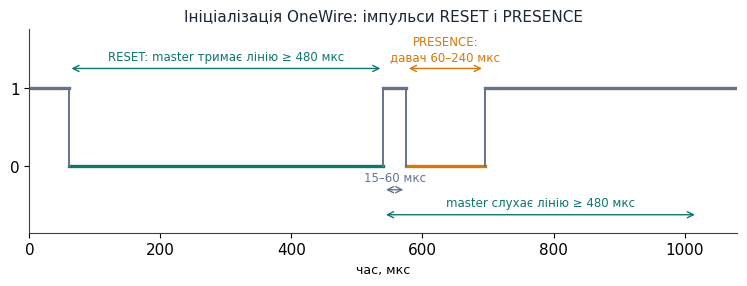

In [23]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

# Реальний масштаб часу (мкс). Колір показує, хто тримає лінію низько.
MASTER, SLAVE = ACCENT_DARK, "#D97706"
segs = [  # (початок, кінець, рівень, хто керує)
    (0, 60, 1, None), (60, 540, 0, MASTER), (540, 575, 1, None),
    (575, 695, 0, SLAVE), (695, 1080, 1, None),
]
fig, ax = plt.subplots(figsize=(7.6, 3.0))
for t1, t2, lvl, who in segs:
    ax.plot([t1, t2], [lvl, lvl], color=who or "#64748B", lw=2.4)
for (a1, b1, l1, _), (a2, b2, l2, w2) in zip(segs, segs[1:]):
    ax.plot([a2, a2], [l1, l2], color="#64748B", lw=1.4)

def bracket(t1, t2, y, text, color):
    ax.annotate("", xy=(t1, y), xytext=(t2, y), arrowprops=dict(arrowstyle="<->", color=color, lw=1))
    ax.text((t1 + t2) / 2, y + 0.07, text, ha="center", va="bottom", fontsize=8.5, color=color)

bracket(60, 540, 1.25, "RESET: master тримає лінію ≥ 480 мкс", MASTER)
bracket(540, 575, -0.3, "15–60 мкс", "#64748B")
bracket(575, 695, 1.25, "PRESENCE:\nдавач 60–240 мкс", SLAVE)
bracket(540, 1020, -0.62, "master слухає лінію ≥ 480 мкс", MASTER)
ax.set_yticks([0, 1]); ax.set_ylim(-0.85, 1.75)
ax.set_xlabel("час, мкс", fontsize=9)
ax.set_xlim(0, 1080)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.set_title("Ініціалізація OneWire: імпульси RESET і PRESENCE", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

Будь-яка транзакція OneWire починається саме з цієї послідовності: master спочатку тримає лінію низько довше за будь-який інший сигнал протоколу (щонайменше ~480 мкс) — цим він однозначно каже всім пристроям «увага, починається нова транзакція». Якщо хоч один пристрій підключений і справний, він відповідає коротким імпульсом presence одразу після паузи — так master дізнається, чи взагалі є що опитувати, ще до того, як почне надсилати команди.

### 10.3. Адресні світлодіоди NeoPixel / APA106 {-}

Адресні світлодіодні стрічки (WS2812/NeoPixel, APA106) керуються одним сигнальним дротом, за яким передається строго синхронізована послідовність кольорів (24 біти на світлодіод — по 8 біт на кожен з каналів R, G, B), одразу для всіх світлодіодів стрічки послідовно:
```python
from machine import Pin
from neopixel import NeoPixel

np = NeoPixel(Pin(5), 8)        # 8 світлодіодів у стрічці

np[0] = (255, 0, 0)              # перший світлодіод — червоний
np[1] = (0, 255, 0)              # другий — зелений
np.write()                        # надіслати весь буфер кольорів на стрічку одночасно
```
Через жорсткі вимоги до часових інтервалів сигналу керування NeoPixel зазвичай реалізовано саме через блок RMT «під капотом» бібліотеки — це і пояснює, чому такий протокол взагалі можливо реалізувати програмно на звичайному мікроконтролері з прийнятною стабільністю.

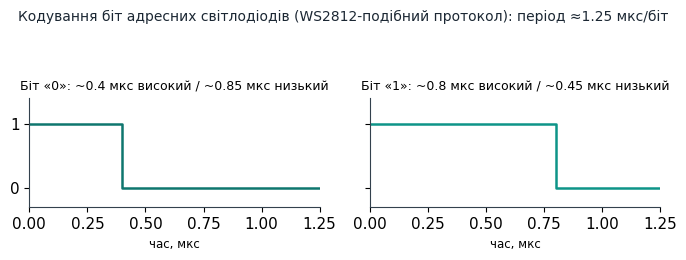

In [24]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

period = 1.25

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(7, 2.6), sharey=True)

t_hi0 = 0.4
ax0.step([0, t_hi0, t_hi0, period], [1, 1, 0, 0], where="post", color=ACCENT_DARK, linewidth=1.8)
ax0.set_title(f"Біт «0»: ~{t_hi0} мкс високий / ~{period - t_hi0:.2f} мкс низький", fontsize=9)

t_hi1 = 0.8
ax1.step([0, t_hi1, t_hi1, period], [1, 1, 0, 0], where="post", color=ACCENT, linewidth=1.8)
ax1.set_title(f"Біт «1»: ~{t_hi1} мкс високий / ~{period - t_hi1:.2f} мкс низький", fontsize=9)

for ax_ in (ax0, ax1):
    ax_.set_ylim(-0.3, 1.4)
    ax_.set_yticks([0, 1])
    ax_.set_xlim(0, period)
    ax_.set_xlabel("час, мкс", fontsize=8.5)
    ax_.spines[["top", "right"]].set_visible(False)

fig.suptitle("Кодування біт адресних світлодіодів (WS2812-подібний протокол): період \u22481.25 мкс/біт", fontsize=10, color=TEXT, y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()


Кожен біт кольору кодується не рівнем сигналу, а **співвідношенням тривалості високого й низького станів усередині фіксованого періоду** (близько 1.25 мкс): короткий високий імпульс означає «0», довгий — «1». Саме тому для генерації такого сигналу потрібен апаратний блок з наносекундною точністю (RMT) — навіть невелике «сповзання» тривалості імпульсу програмним циклом здатне перетворити «0» на «1» і зіпсувати весь відображуваний колір.

### 10.4. Ємнісні дотикові піни {-}

Частина пінів ESP32 підтримує **ємнісне визначення дотику** (`TouchPad`) — вимірюється зміна електричної ємності при наближенні пальця до відкритого металевого контакту чи провідної поверхні, без потреби в механічній кнопці:
```python
from machine import TouchPad, Pin

touch = TouchPad(Pin(4))
value = touch.read()             # менше значення, як правило, означає дотик — поріг підбирають експериментально
```
Дотикові піни зручні для герметичних або естетично мінімалістичних корпусів пристрою (сенсорна панель без механічних отворів), але чутливіші до вологості й електромагнітних завад, тому поріг спрацювання зазвичай калібрують під конкретні умови експлуатації.

### 10.5. Часові параметри RMT: роздільна здатність і тривалість {-}

Канал RMT працює не з мікросекундами напряму, а з **тактами (ticks)** заданої тривалості: конструктор ділить базову тактову частоту периферії на вказаний дільник, і кожен імпульс у послідовності описується парою «рівень + кількість тактів». MicroPython надає доступ до цього блока через `esp32.RMT`:

```python
from machine import Pin
from esp32 import RMT

rmt = RMT(0, pin=Pin(18), clock_div=8)   # менший дільник -> коротша тривалість одного такту
# .write_pulses() приймає список тривалостей (у тактах), що чергуються між рівнями 1 і 0
rmt.write_pulses([32, 32, 16, 32], start=1)
```

Саме цей низькорівневий механізм «список тривалостей імпульсів» і використовують бібліотеки на кшталт `neopixel` та `onewire` під капотом, щоб надійно відтворити часові діаграми з розділів 10.2 і 10.3, не покладаючись на точність програмних затримок.

### 10.6. Обмеження ємнісних дотикових пінів на різних варіантах ESP32 {-}

Периферія ємнісного дотику доступна не на всіх пінах і не на всіх варіантах чипа: підтримується лише обмежена, фіксована підмножина GPIO класичного ESP32 (позначена в документації як `TOUCHx`) — точний перелік і поведінка калібрування наведені в довідці MicroPython для конкретної плати. Важливіше практичне зауваження: на деяких молодших/спрощених варіантах чипа (зокрема, побудованих на архітектурі RISC-V, а не класичному Xtensa-ядрі) цієї периферії може взагалі не бути — тому перед проєктуванням пристрою з сенсорними кнопками варто одразу перевірити наявність `TouchPad` у документації саме на ту плату, яку плануєте використовувати, а не переносити код «наосліп» з іншого варіанта ESP32.

### 10.7. Практичний приклад: температурна індикація на NeoPixel {-}

Об'єднаємо OneWire-давач температури (DS18B20) і адресну світлодіодну стрічку (NeoPixel) — стрічка кольором показує, наскільки тепло чи холодно навколо, без потреби в дисплеї:

```python
from machine import Pin
from neopixel import NeoPixel
import onewire, ds18x20
import time

ow = onewire.OneWire(Pin(4))
sensor = ds18x20.DS18X20(ow)
roms = sensor.scan()

np = NeoPixel(Pin(5), 8)

def temp_to_color(t):
    if t < 15:
        return (0, 0, 255)        # холодно — синій
    elif t < 25:
        return (0, 255, 0)         # комфортно — зелений
    else:
        return (255, 0, 0)          # спекотно — червоний

while True:
    sensor.convert_temp()
    time.sleep_ms(750)
    t = sensor.read_temp(roms[0])
    color = temp_to_color(t)
    for i in range(8):
        np[i] = color
    np.write()
    print("Температура:", t, "°C ->", color)
    time.sleep(2)
```

Цей приклад демонструє типовий патерн IoT-пристроїв: **зчитати давач → перетворити значення на «зрозумілу» форму (тут — колір) → відобразити**, який ми ще не раз побачимо в комбінованих проєктах цього курсу.

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Яку задачу вирішує апаратний блок RMT і чому важлива саме апаратна, а не програмна генерація сигналу?</summary>

> **Відповідь:** RMT генерує/приймає точні до наносекунд послідовності імпульсів різної тривалості. Апаратна генерація важлива тому, що відбувається без участі процесора на кожному імпульсі — критично для протоколів (адресні світлодіоди, OneWire), де навіть невелике відхилення в часі призводить до помилки зчитування.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Як протокол OneWire дозволяє живити пристрій і обмінюватись даними всього одним сигнальним дротом?</summary>

> **Відповідь:** За рахунок точного часового кодування бітів на єдиному сигнальному дроті (плюс спільний GND) — це дозволяє одночасно і живити пристрій, і передавати команди та отримувати дані.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Як розрізняються кілька давачів DS18B20, підключених до однієї лінії OneWire?</summary>

> **Відповідь:** Кожен давач на шині має власний унікальний 64-бітний ідентифікатор (ROM), який зчитується через `sensors.scan()` — аналогічно до адрес на I2C, але без потреби в підтяжці на кожен пристрій окремо.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Скільки біт кольору передається на один світлодіод у стрічці NeoPixel і як вони розподілені між каналами?</summary>

> **Відповідь:** 24 біти на світлодіод — по 8 біт на кожен з каналів R, G, B.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому протокол керування адресними світлодіодами зазвичай реалізують через блок RMT?</summary>

> **Відповідь:** Через жорсткі вимоги до часових інтервалів сигналу керування — саме RMT робить можливою реалізацію такого протоколу програмно на звичайному мікроконтролері з прийнятною стабільністю.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Який фізичний принцип лежить в основі ємнісних дотикових пінів ESP32?</summary>

> **Відповідь:** Вимірювання зміни електричної ємності при наближенні пальця до відкритого металевого контакту чи провідної поверхні.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Назвіть одну перевагу й один недолік ємнісних дотикових пінів порівняно з механічною кнопкою.</summary>

> **Відповідь:** Перевага: зручні для герметичних або естетично мінімалістичних корпусів (сенсорна панель без механічних отворів). Недолік: чутливіші до вологості й електромагнітних завад, тому поріг спрацювання потрібно калібрувати під конкретні умови.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Що означають два основні часові інтервали діаграми RESET/PRESENCE у протоколі OneWire?</summary>

> **Відповідь:** Тривала пауза (≥480 мкс), протягом якої master тримає лінію низько, сигналізує всім пристроям про початок нової транзакції; коротка presence-пауза (60–240 мкс) — це відповідь пристрою, яка повідомляє master, що на лінії є хоча б один справний давач.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Чому перед перенесенням коду з дотиковими пінами на іншу плату ESP32 варто перевірити документацію саме цієї плати?</summary>

> **Відповідь:** Периферія ємнісного дотику доступна лише на обмеженій підмножині GPIO і не на всіх варіантах чипа — на деяких (зокрема побудованих на архітектурі RISC-V) вона може бути відсутня взагалі, тому код, що працює на одній платі, може не запрацювати на іншій без перевірки.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 11. Датчики температури й вологості (DHT) та підключення зовнішніх бібліотек

### Після опрацювання розділу ви зможете: {-}
- пояснити протокол зчитування давачів родини DHT
- порівняти DHT11 та DHT22 за точністю й швидкістю оновлення
- встановлювати сторонні бібліотеки-драйвери на плату
- пояснити роль контрольної суми при перевірці отриманих даних
- враховувати типові джерела похибок при розміщенні давача


### 11.1. Родина давачів DHT {-}

DHT11 і DHT22 — поширені комбіновані давачі температури й вологості з цифровим виходом на одному сигнальному дроті (протокол, подібний за духом до OneWire, але власного, несумісного формату). MicroPython надає вбудований драйвер:
```python
from machine import Pin
import dht
import time

sensor = dht.DHT22(Pin(4))        # для DHT11 — dht.DHT11(Pin(4))

while True:
    sensor.measure()               # запустити вимірювання (сам обмін по протоколу давача)
    print("Температура:", sensor.temperature(), "°C")
    print("Вологість:", sensor.humidity(), "%")
    time.sleep(2)                   # DHT-давачі не можна опитувати частіше, ніж раз на ~2 секунди
```

### 11.2. Порівняння DHT11 і DHT22 {-}

| Характеристика | DHT11 | DHT22 |
|---|---|---|
| Точність температури | ±2 °C | ±0.5 °C |
| Діапазон температури | 0–50 °C | −40–80 °C |
| Точність вологості | ±5% | ±2–5% |
| Мінімальний інтервал опитування | ~1 с | ~2 с |
| Ціна | нижча | вища |

Для навчальних проєктів обидва варіанти прийнятні; для задач, де важлива точність або робота при від'ємних температурах, обирають DHT22.

### 11.3. Встановлення сторонніх бібліотек на плату {-}

Не всі драйвери входять до стандартної прошивки MicroPython (наприклад, `ssd1306.py` для OLED чи `max7219.py` для матричного дисплея з Лабораторної №4 — це окремі `.py`-файли). Типовий процес підключення сторонньої бібліотеки:

1. Знайти офіційний вихідний код драйвера (як правило, у репозиторії проєкту MicroPython або виробника пристрою).
2. Скопіювати відповідний `.py`-файл на плату в кореневий каталог (або в підкаталог `/lib`) тим самим інструментом, що й `main.py` (`mpremote cp`, Thonny, тощо).
3. Використати `import` цього модуля у своєму коді так само, як вбудований.

В онлайн-симуляторі Wokwi популярні драйвери (зокрема для OLED та матричних дисплеїв) вже вбудовані в середовище — досить написати `import` без окремого копіювання файлу, що суттєво спрощує навчальні завдання.

### 11.4. Порівняння з цифровими I2C-давачами {-}

DHT11/DHT22 — не єдиний варіант вимірювання температури й вологості. Сучасніші I2C-давачі (наприклад, **BME280**, **SHT31**, **AHT20**) часто є кращим вибором:

| Критерій | DHT11/DHT22 | I2C-давачі (BME280/SHT31/...) |
|---|---|---|
| Інтерфейс | власний однодротовий протокол з жорсткими часовими вимогами | стандартний I2C — можна ділити шину з іншими пристроями |
| Швидкість опитування | обмежена (1 вимірювання на 1–2 с) | значно швидша |
| Додаткові вимірювання | лише температура й вологість | часто ще й атмосферний тиск (BME280) |
| Точність | нижча (особливо DHT11) | зазвичай вища |
| Ціна | нижча | трохи вища |

Для навчальних лабораторних DHT — чудовий і дешевий вибір саме тому, що змушує вручну розбиратися з протоколом без готової шини; для реального продукту частіше обирають I2C-варіант.

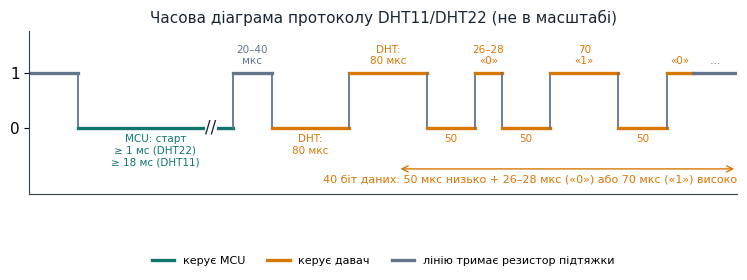

In [25]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

# Тривалості не в масштабі (старт-сигнал MCU у сотні разів довший за біт) — підписано реальні значення.
MCU, DHT, PULL = ACCENT_DARK, "#D97706", "#64748B"
segs = [  # (тривалість на рисунку, рівень, хто керує, підпис)
    (1.0, 1, PULL, ""),
    (3.2, 0, MCU, "MCU: старт\n≥ 1 мс (DHT22)\n≥ 18 мс (DHT11)"),
    (0.8, 1, PULL, "20–40\nмкс"),
    (1.6, 0, DHT, "DHT:\n80 мкс"),
    (1.6, 1, DHT, "DHT:\n80 мкс"),
    (1.0, 0, DHT, "50"),
    (0.55, 1, DHT, "26–28\n«0»"),
    (1.0, 0, DHT, "50"),
    (1.4, 1, DHT, "70\n«1»"),
    (1.0, 0, DHT, "50"),
    (0.55, 1, DHT, "«0»"),
    (0.9, 1, PULL, "…"),
]
fig, ax = plt.subplots(figsize=(7.6, 3.2))
t = 0
prev = None
for w, lvl, who, label in segs:
    if prev is not None and prev != lvl:
        ax.plot([t, t], [prev, lvl], color=PULL, lw=1.3)
    ax.plot([t, t + w], [lvl, lvl], color=who, lw=2.4)
    if label:
        y = 1.12 if lvl == 1 else -0.12
        ax.text(t + w / 2, y, label, ha="center", va="bottom" if lvl == 1 else "top", fontsize=7.5, color=who)
    t += w; prev = lvl
# символ розриву осі часу на довгому старт-сигналі
ax.text(3.75, 0, "//", fontsize=12, ha="center", va="center", color=TEXT,
        bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
ax.annotate("", xy=(7.6, -0.75), xytext=(t, -0.75), arrowprops=dict(arrowstyle="<->", color=DHT, lw=1))
ax.text(t, -0.85, "40 біт даних: 50 мкс низько + 26–28 мкс («0») або 70 мкс («1») високо",
        ha="right", va="top", fontsize=8, color=DHT)
ax.plot([], [], color=MCU, lw=2.4, label="керує MCU")
ax.plot([], [], color=DHT, lw=2.4, label="керує давач")
ax.plot([], [], color=PULL, lw=2.4, label="лінію тримає резистор підтяжки")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=8, frameon=False)
ax.set_yticks([0, 1]); ax.set_ylim(-1.2, 1.75); ax.set_xticks([])
ax.set_xlim(0, t)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.set_title("Часова діаграма протоколу DHT11/DHT22 (не в масштабі)", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

### 11.5. Часова діаграма протоколу DHT {-}

Обмін із давачем родини DHT завжди має однакову структуру (діаграма вище): спочатку **MCU** ініціює вимірювання, утримуючи лінію низько протягом тривалого старт-сигналу (порядку мілісекунд — саме тому виклик `sensor.measure()` не миттєвий); давач відповідає короткою парою low/high тривалістю по 80 мкс, а далі передає 40 біт даних, кожен з яких кодується **однаковою тривалістю низького рівня** (~50 мкс) і **різною тривалістю високого** — коротший імпульс означає «0», довший — «1». Це принципово той самий підхід кодування «через співвідношення тривалостей», що й у протоколі NeoPixel (Розділ 10.3), лише з іншими конкретними часовими межами.

### 11.6. Контрольна сума (checksum) даних DHT {-}

40 переданих біт розбиваються на 5 байтів: старший і молодший байт вологості, старший і молодший байт температури, і останній, п'ятий байт — **контрольна сума**, яка дорівнює сумі перших чотирьох байтів (за модулем 256). Якщо обчислена сума не збігається з отриманим п'ятим байтом, дані вважаються пошкодженими внаслідок завади чи неточного зчитування часових інтервалів і повинні бути відкинуті.

Вбудований драйвер `dht` у MicroPython сам перевіряє цю контрольну суму всередині `measure()` і піднімає `OSError`, якщо перевірка не пройшла — тому будь-який код, що читає DHT-давач у циклі, повинен бути готовий до випадкової помилки саме з цієї причини (див. приклад 11.8 нижче), а не сприймати її як несправність давача.

### 11.7. Джерела похибок і рекомендації для точних вимірювань {-}

- **Самонагрівання**: якщо давач розташований надто близько до самої плати ESP32 чи інших компонентів, що виділяють тепло (наприклад, стабілізатора живлення), покази температури будуть систематично завищені.
- **Пряме сонячне світло чи потік повітря від вентилятора** спотворюють вимірювання вологості й температури значно сильніше, ніж власна похибка давача — розташування давача важливіше за вибір між DHT11 і DHT22.
- **Недостатня вентиляція корпусу**: якщо давач заклеєний у повністю герметичний корпус, він вимірює мікроклімат усередині корпуса, а не навколишнього середовища.
- **Занадто часте опитування** (частіше за рекомендований інтервал з Розділу 11.2) не пришвидшує отримання даних, а лише збільшує ймовірність помилки контрольної суми.

### 11.8. Практичний приклад: логер з усередненням і пороговими сповіщеннями {-}

```python
from machine import Pin
import dht
import time

sensor = dht.DHT22(Pin(4))
history = []
MAX_HISTORY = 12          # останні 12 вимірювань (наприклад, за годину при інтервалі 5 хв)
TEMP_ALERT = 30.0

while True:
    try:
        sensor.measure()
        t = sensor.temperature()
        history.append(t)
        history[:] = history[-MAX_HISTORY:]

        avg = sum(history) / len(history)
        print(f"Поточна: {t}°C, середня за період: {avg:.1f}°C")

        if t > TEMP_ALERT:
            print("!! УВАГА: температура перевищує поріг", TEMP_ALERT)
    except OSError as e:
        print("Помилка зчитування давача:", e)   # DHT іноді "мовчить" — не зупиняємо програму

    time.sleep(5 * 60)
```

Звертаємо увагу на `try/except OSError` навколо `sensor.measure()` — DHT-давачі відомі тим, що іноді не встигають відповісти вчасно, або контрольна сума (Розділ 11.6) не сходиться через часові обмеження протоколу; обробка цієї помилки без зупинки всієї програми — обов'язкова практика для будь-якого довготривалого логера (детальніше про обробку виключень — Розділ 18).

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чим протокол DHT-давачів схожий на OneWire і чим принципово відрізняється?</summary>

> **Відповідь:** Схожий тим, що теж передає дані цифровим сигналом по одному сигнальному дроту; принципово відрізняється тим, що це власний, несумісний з OneWire формат протоколу.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Порівняйте DHT11 і DHT22 за точністю та ціною — коли доцільно обрати кожен з них?</summary>

> **Відповідь:** DHT11: точність температури ±2 °C, вологості ±5%, діапазон 0–50 °C, дешевший — прийнятний для навчальних проєктів. DHT22: точність температури ±0.5 °C, вологості ±2–5%, ширший діапазон −40–80 °C, дорожчий — обирають, коли важлива точність або робота при від'ємних температурах.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чому DHT-давачі не можна опитувати частіше, ніж раз на 1-2 секунди?</summary>

> **Відповідь:** Це обмеження власного протоколу/апаратної реалізації давача: мінімальний інтервал опитування — приблизно 1 с для DHT11 і 2 с для DHT22.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Опишіть загальний алгоритм підключення стороннього драйвера, якого немає у стандартній прошивці MicroPython.</summary>

> **Відповідь:** 1) Знайти офіційний вихідний код драйвера (репозиторій MicroPython або виробника пристрою); 2) скопіювати відповідний `.py`-файл на плату в кореневий каталог або `/lib` тим самим інструментом, що й `main.py`; 3) використати `import` цього модуля так само, як вбудований.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чим спрощена робота зі сторонніми бібліотеками у Wokwi порівняно з реальною платою?</summary>

> **Відповідь:** У Wokwi популярні драйвери (зокрема для OLED та матричних дисплеїв) вже вбудовані в середовище — досить написати `import` без окремого копіювання файлу на пристрій.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Як кодується біт «0» проти біта «1» у протоколі DHT, і чим цей принцип нагадує кодування NeoPixel?</summary>

> **Відповідь:** Обидва біти мають однакову тривалість низького рівня (~50 мкс), але різну тривалість високого — коротший імпульс означає «0», довший — «1». Це той самий принцип кодування «через співвідношення тривалостей», що й у протоколі NeoPixel, лише з іншими конкретними часовими межами.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Що робить контрольна сума в переданих даних DHT і що станеться, якщо вона не збіжиться?</summary>

> **Відповідь:** Контрольна сума — це п'ятий байт, що дорівнює сумі перших чотирьох байтів (вологість і температура) за модулем 256. Якщо вона не збігається, дані вважаються пошкодженими і `measure()` піднімає `OSError`.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Назвіть дві причини, чому показання DHT-давача можуть бути неточними навіть при справному давачі.</summary>

> **Відповідь:** Наприклад: самонагрівання від сусідніх компонентів плати (завищена температура) та пряме сонячне світло/потік повітря від вентилятора (спотворення і температури, і вологості); також герметичний корпус без вентиляції змушує давач вимірювати мікроклімат усередині корпуса, а не довкілля.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 12. SD-картки та зберігання даних

### Після опрацювання розділу ви зможете: {-}
- підключати SD-картку через SPI
- монтувати файлову систему SD-картки в просторі MicroPython
- оцінювати, коли доцільно використовувати SD-картку замість вбудованої flash-пам'яті
- пояснювати рівні абстракції між кодом застосунку та апаратною SD-карткою
- порівнювати SPI-режим і нативний SDIO-режим роботи з SD-картками
- перевіряти вільне місце на картці програмно


### 12.1. Навіщо SD-картка, якщо є вбудована flash-пам'ять {-}

Файлова система на власній flash-пам'яті плати (Розділ 2) обмежена кількома мегабайтами і не призначена для частого перезапису великих обсягів даних. **SD-картка** розширює можливості зберігання до гігабайтів і зручна для:

- тривалого логування показань давачів (наприклад, метеостанція, що пише файл щохвилини роками);
- зберігання великих ресурсів (зображення, аудіофайли, готові вебсторінки);
- перенесення даних між пристроєм і комп'ютером простим вийманням картки.

### 12.2. Підключення через SPI та монтування {-}

Модулі SD-карток для мікроконтролерів зазвичай мають SPI-інтерфейс (Розділ 8):
```python
from machine import Pin, SPI
import os, sdcard

spi = SPI(1, baudrate=1_000_000, sck=Pin(18), mosi=Pin(23), miso=Pin(19))
cs = Pin(5, Pin.OUT)

sd = sdcard.SDCard(spi, cs)
os.mount(sd, "/sd")               # тепер картка доступна як каталог /sd

with open("/sd/log.csv", "a") as f:
    f.write("23.4,60\n")

print(os.listdir("/sd"))
```
Після `os.mount()` робота з файлами на SD-картці нічим не відрізняється від роботи з файлами на вбудованій flash-пам'яті — той самий модуль `os` і той самий синтаксис `open()`.

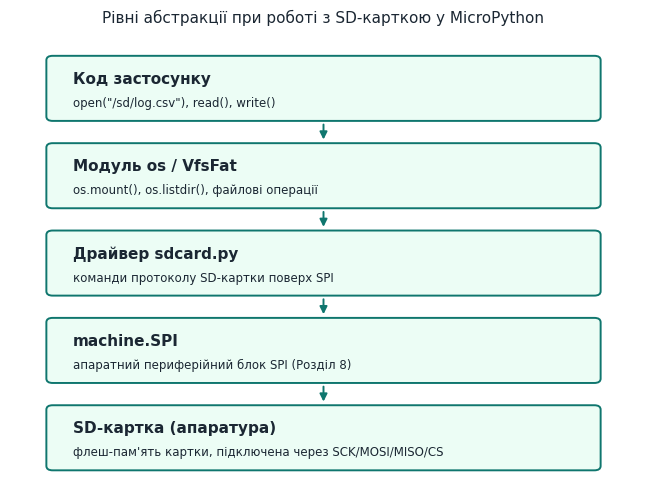

In [26]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, ax = plt.subplots(figsize=(6.6, 5.0))
ax.set_xlim(0, 10); ax.set_ylim(0, 10.2); ax.axis("off")
layers = [
    ("Код застосунку", 'open("/sd/log.csv"), read(), write()'),
    ("Модуль os / VfsFat", "os.mount(), os.listdir(), файлові операції"),
    ("Драйвер sdcard.py", "команди протоколу SD-картки поверх SPI"),
    ("machine.SPI", "апаратний периферійний блок SPI (Розділ 8)"),
    ("SD-картка (апаратура)", "флеш-пам'ять картки, підключена через SCK/MOSI/MISO/CS"),
]
h, gap = 1.45, 0.55
for i, (title, sub) in enumerate(layers):
    y = 9.6 - h - i * (h + gap)
    ax.add_patch(mpatches.FancyBboxPatch((0.6, y), 8.8, h, boxstyle="round,pad=0.02,rounding_size=0.1",
                                         facecolor="#ECFDF5", edgecolor=ACCENT_DARK, lw=1.4))
    ax.text(1.0, y + h * 0.66, title, fontsize=11, fontweight="bold", color=TEXT, va="center")
    ax.text(1.0, y + h * 0.28, sub, fontsize=8.5, color=TEXT, va="center")
    if i < len(layers) - 1:
        ax.annotate("", xy=(5.0, y - gap + 0.04), xytext=(5.0, y - 0.04),
                    arrowprops=dict(arrowstyle="-|>", color=ACCENT_DARK, lw=1.4))
ax.set_title("Рівні абстракції при роботі з SD-карткою у MicroPython", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

Діаграма вище показує, чому це працює так прозоро: код застосунку взагалі не знає, що дані фізично летять через SPI на окрему мікросхему — він працює з тим самим модулем `os` і тими самими функціями `open()`/`read()`/`write()`, що й для вбудованої flash-пам'яті. Кожен нижчий рівень (файлова система → драйвер картки → апаратний SPI) ховає деталі свого рівня від того, що над ним, — саме тому додавання SD-картки не вимагає жодних змін у коді, що вже працює з файлами.

### 12.3. Практичні поради {-}

- Швидкість SPI для SD-карток зазвичай обмежують (особливо на старті роботи з картою) нижчими значеннями, ніж для дисплеїв — не всі картки стабільно працюють на максимальній швидкості шини.
- Перед фізичним вийманням картки бажано викликати `os.umount("/sd")`, щоб уникнути пошкодження недописаних даних.
- Для тривалого логування зручний формат CSV (значення через кому, один запис на рядок) — легко відкрити потім у звичайній програмі для роботи з таблицями.

### 12.4. Формати файлових систем і обмеження MicroPython {-}

Модуль `os` у MicroPython уміє працювати з файловою системою **FAT** через реалізацію `os.VfsFat`, тому SD-картку, яку планують використовувати з `sdcard.py`, як правило, заздалегідь форматують у FAT32 (стандартне заводське форматування більшості нових карток вже підходить). За потреби відформатувати картку прямо з MicroPython:

```python
import os, sdcard
from machine import Pin, SPI

spi = SPI(1, baudrate=1_000_000, sck=Pin(18), mosi=Pin(23), miso=Pin(19))
sd = sdcard.SDCard(spi, Pin(5, Pin.OUT))

os.VfsFat.mkfs(sd)        # УВАГА: повністю знищує наявні дані на картці
os.mount(sd, "/sd")
```

Файлова система FAT має й типові для неї обмеження (довжина імені файлу, максимальна кількість файлів у каталозі) — для навчальних проєктів із порівняно невеликою кількістю файлів це рідко стає проблемою.

### 12.5. SPI-режим проти нативного SDIO-режиму {-}

Драйвер `sdcard.py` з прикладу 12.2 працює через звичайний `machine.SPI` — це універсальний, але не найшвидший спосіб: реальні SD-картки підтримують власний, ширший 4-провідний режим (SDIO), який суттєво швидший за SPI-емуляцію. На деяких платах ESP32 з апаратним слотом для SD-картки MicroPython надає й вищерівневий клас `machine.SDCard`, що використовує саме нативний режим контролера SD/MMC чипа:

```python
from machine import SDCard
import os

sd = SDCard()          # на платах з нативним слотом піни вже визначені виробником плати
os.mount(sd, "/sd")
```

Який з двох варіантів доступний, залежить від конкретної плати й того, чи виведені відповідні піни SD/MMC контролера на роз'єм: для проєктів «SD-картка через довільні GPIO на макетній платі» лишається лише SPI-варіант із Розділу 12.2, а нативний `machine.SDCard` — приємний бонус на платах зі спеціалізованим слотом.

### 12.6. Практичний приклад: перевірка вільного місця на картці {-}

Для довготривалого логера важливо не переповнити картку непомітно. Функція `os.statvfs()` повертає інформацію про файлову систему, з якої легко порахувати вільний обсяг:

```python
import os

def free_space_mb(path="/sd"):
    stat = os.statvfs(path)
    block_size = stat[0]
    free_blocks = stat[3]
    return (block_size * free_blocks) / (1024 * 1024)

free_mb = free_space_mb()
print(f"Вільно на картці: {free_mb:.1f} МБ")
if free_mb < 50:
    print("!! УВАГА: залишилось менше 50 МБ вільного місця")
```

Такий контроль варто викликати періодично (наприклад, раз на день у довготривалому логері) і поєднувати з ротацією файлів (Розділ 12.7), щоб пристрій міг попередити про наближення до межі місткості задовго до того, як картка справді заповниться.

### 12.7. Практичний приклад: ротація лог-файлів {-}

Якщо писати весь лог в один файл роками, він рано чи пізно займе всю картку. Простий прийом — **ротація**: коли поточний файл досягає межі розміру, перейменувати його й почати новий:

```python
import os

LOG_PATH = "/sd/log.csv"
MAX_SIZE = 1_000_000        # ~1 МБ

def log_line(text):
    try:
        size = os.stat(LOG_PATH)[6]      # розмір файлу в байтах
    except OSError:
        size = 0

    if size > MAX_SIZE:
        try:
            os.remove("/sd/log_old.csv")
        except OSError:
            pass
        os.rename(LOG_PATH, "/sd/log_old.csv")

    with open(LOG_PATH, "a") as f:
        f.write(text + "\n")

log_line("2026-08-03 12:00,23.4,60")
```

Такий підхід тримає щонайбільше два файли (поточний і попередній), гарантуючи, що логування ніколи не переповнить картку повністю, ціною втрати найстаріших записів.

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> У чому основна перевага SD-картки над вбудованою flash-пам'яттю плати?</summary>

> **Відповідь:** Вона розширює можливості зберігання до гігабайтів (замість кількох мегабайтів вбудованої flash-пам'яті) і зручна для тривалого логування, зберігання великих ресурсів та перенесення даних простим вийманням картки.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Через яку шину зазвичай підключають SD-картки до ESP32?</summary>

> **Відповідь:** Через SPI.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Що робить функція `os.mount()` і як після цього змінюється робота з файлами картки?</summary>

> **Відповідь:** Монтує файлову систему SD-картки за певним шляхом (наприклад `/sd`); після цього робота з файлами на картці нічим не відрізняється від роботи з файлами на вбудованій flash-пам'яті — той самий модуль `os` і той самий синтаксис `open()`.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Чому варто обмежувати швидкість SPI при роботі з SD-картками порівняно з, наприклад, дисплеєм?</summary>

> **Відповідь:** Бо не всі картки стабільно працюють на максимальній швидкості шини, особливо на старті роботи з картою.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Наведіть приклад проєкту, для якого SD-картка є практично необхідною, а вбудованої flash-пам'яті недостатньо.</summary>

> **Відповідь:** Метеостанція, що пише файл показань щохвилини роками — приклад тривалого логування, наведений у розділі 12.1.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Чому додавання SD-картки не вимагає змін у коді, що вже читає й пише файли на вбудованій flash-пам'яті?</summary>

> **Відповідь:** Тому що рівні абстракції (код застосунку → os/VfsFat → драйвер картки → SPI) ховають деталі кожного нижчого рівня; код застосунку працює з тими самими `open()`/`read()`/`write()` незалежно від того, яка апаратура фактично зберігає дані.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Чим нативний режим `machine.SDCard` відрізняється від драйвера `sdcard.py` через SPI?</summary>

> **Відповідь:** `machine.SDCard` використовує власний, ширший 4-провідний режим SD/MMC контролера чипа (SDIO), що суттєво швидше за SPI-емуляцію в `sdcard.py`, але доступний лише на платах з апаратним слотом, де відповідні піни виведені виробником.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Як за допомогою `os.statvfs()` дізнатись обсяг вільного місця на картці?</summary>

> **Відповідь:** `os.statvfs(path)` повертає кортеж, у якому елемент з індексом 0 — розмір блока, а елемент з індексом 3 — кількість вільних блоків; їхній добуток дає обсяг вільного місця в байтах.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 13. Реальний час: RTC та годинники

### Після опрацювання розділу ви зможете: {-}
- використовувати вбудований RTC-модуль ESP32
- пояснити, чому вбудований RTC втрачає точний час без живлення
- підключати зовнішній модуль RTC (DS3231) для збереження точного часу
- зберігати невеликі дані в RTC-пам'яті між циклами глибокого сну
- обирати між внутрішнім RTC, зовнішнім модулем і NTP залежно від умов проєкту

### 13.1. Вбудований RTC ESP32 {-}

ESP32 має вбудований блок **RTC (Real Time Clock)** — невеликий лічильник часу, що продовжує працювати навіть у режимі глибокого сну (Розділ 4.4), оскільки живиться від окремого, дуже економного генератора:
```python
from machine import RTC

rtc = RTC()
rtc.datetime((2026, 8, 2, 0, 12, 0, 0, 0))   # (рік, місяць, день, день тижня, год, хв, сек, мкс)
print(rtc.datetime())
```
**Обмеження:** вбудований RTC ESP32 не має власного батарейного живлення й точного кварцового генератора для тривалого зберігання часу — після повного знеструмлення плати (не сну, а саме відключення живлення) час потрібно встановлювати заново, зазвичай синхронізуючи його через мережу (Розділ 14) або вручну.

### 13.2. Зовнішній модуль RTC: DS3231 {-}

Для проєктів, де точний час має зберігатись роками навіть без мережі й без основного живлення, використовують окрему мікросхему RTC із власною батарейкою (типово **DS3231**), підключену через I2C (Розділ 7):
```python
from machine import I2C, Pin
import ds3231     # стороння бібліотека-драйвер (Розділ 11.3)

i2c = I2C(0, scl=Pin(22), sda=Pin(21))
ext_rtc = ds3231.DS3231(i2c)

print(ext_rtc.get_time())
```
DS3231 продовжує рахувати час навіть коли плата ESP32 повністю знеструмлена — годинник живиться від власної батарейки-таблетки на самому модулі. При старті плата може прочитати точний час з DS3231 і встановити його у свій вбудований RTC для подальшої роботи програми.

### 13.3. Синхронізація часу через мережу (NTP) {-}

Якщо плата має доступ до Wi-Fi (Розділ 14), найпростіший спосіб отримати точний час — синхронізуватися з мережевим сервером часу (**NTP, Network Time Protocol**) замість покладатися на неточний внутрішній RTC чи окремий апаратний модуль:

```python
import network
import ntptime
import machine

# (передбачається, що Wi-Fi вже підключено — див. Розділ 14)
ntptime.settime()             # встановлює системний час UTC за даними NTP-сервера

print(machine.RTC().datetime())
```

**Застереження:** `ntptime.settime()` встановлює час у **UTC**, без урахування часового поясу — для локального часу потрібно самостійно додати/відняти зсув годин у коді. Крім того, синхронізацію варто повторювати періодично (наприклад, раз на добу), оскільки внутрішній генератор плати поступово «дрейфує» відносно точного часу.

### 13.4. Практичний приклад: дія за розкладом {-}

```python
import time

def is_time_to_water_plants(rtc):
    _, _, _, _, hour, minute, _, _ = rtc.datetime()
    return hour == 8 and minute == 0        # рівно о 8:00

from machine import RTC, Pin
rtc = RTC()
pump = Pin(2, Pin.OUT)
already_triggered_today = False

while True:
    if is_time_to_water_plants(rtc) and not already_triggered_today:
        pump.on()
        time.sleep(5)
        pump.off()
        already_triggered_today = True
        print("Полив виконано")
    elif not is_time_to_water_plants(rtc):
        already_triggered_today = False      # скидаємо прапорець, коли хвилина минула

    time.sleep(30)
```

Прапорець `already_triggered_today` тут необхідний: без нього дія виконувалась би повторно щоразу, коли цикл встигає перевірити умову протягом тієї самої хвилини о 8:00.

### 13.5. RTC-пам'ять і збереження даних під час глибокого сну {-}

Крім самого годинника, ESP32 має невеликий, окремий блок пам'яті — **RTC-пам'ять**, що живиться від того самого економного домену, що й RTC-лічильник часу з Розділу 13.1, і тому **зберігає свій вміст під час глибокого сну** (Розділ 4.4), на відміну від основної оперативної пам'яті (SRAM), яка при вході в глибокий сон повністю очищається — після пробудження мікроконтролер фактично перезапускається «з нуля», і всі звичайні Python-змінні втрачаються.

MicroPython надає доступ до невеликої ділянки цієї пам'яті через `machine.RTC().memory()`:
```python
from machine import RTC

rtc = RTC()

# Зберегти дані перед входом у глибокий сон
rtc.memory(b"cycle=42")

# ... тут відбувається machine.deepsleep() (Розділ 4.4) ...

# Після пробудження (фактично після перезапуску) - зчитати збережене
saved = rtc.memory()
print(saved)   # b'cycle=42'
```
Обсяг цієї пам'яті обмежений (порядку кількох кілобайтів, залежить від моделі чипа й порту MicroPython) — вона годиться для невеликих службових даних (лічильник циклів, останнє виміряне значення, прапорець стану), а не для повноцінного журналу чи великих масивів, для яких варто використовувати SD-картку (Розділ 12) чи флеш-файлову систему.

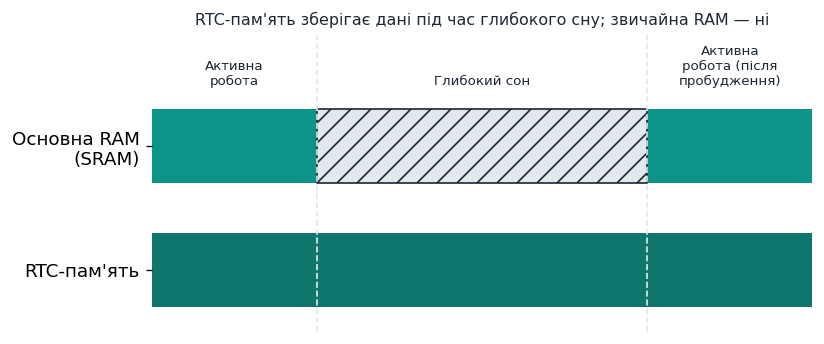

In [27]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, ax = plt.subplots(figsize=(7, 3), dpi=120)
ax.broken_barh([(0, 3), (9, 3)], (10, 6), facecolors=ACCENT)
ax.broken_barh([(3, 6)], (10, 6), facecolors=GRID, hatch="//", edgecolor=TEXT)
ax.broken_barh([(0, 12)], (0, 6), facecolors=ACCENT_DARK)
for x0, label in [(1.5, "Активна\nробота"), (6, "Глибокий сон"), (10.5, "Активна\nробота (після\nпробудження)")]:
    ax.text(x0, 18, label, ha="center", fontsize=8, color=TEXT)
for x in (3, 9):
    ax.axvline(x, color=GRID, linestyle="--", linewidth=1)
ax.set_yticks([13, 3])
ax.set_yticklabels(["Основна RAM\n(SRAM)", "RTC-пам'ять"])
ax.set_xlim(0, 12)
ax.set_ylim(-2, 22)
ax.set_xticks([])
for s in ["top", "right", "left", "bottom"]:
    ax.spines[s].set_visible(False)
ax.set_title("RTC-пам'ять зберігає дані під час глибокого сну; звичайна RAM — ні", fontsize=9.5, color=TEXT)
plt.tight_layout()
plt.show()

### 13.6. Порівняння підходів до точного часу {-}

Ми розглянули три джерела точного часу — зіставимо їх за практичними критеріями:

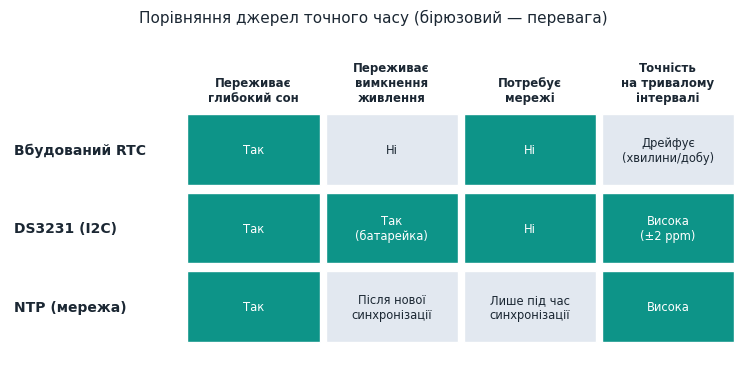

In [28]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

rows = ["Вбудований RTC", "DS3231 (I2C)", "NTP (мережа)"]
cols = ["Переживає\nглибокий сон", "Переживає\nвимкнення\nживлення", "Потребує\nмережі", "Точність\nна тривалому\nінтервалі"]
cells = [
    [("Так", 1), ("Ні", 0), ("Ні", 1), ("Дрейфує\n(хвилини/добу)", 0)],
    [("Так", 1), ("Так\n(батарейка)", 1), ("Ні", 1), ("Висока\n(±2 ppm)", 1)],
    [("Так", 1), ("Після нової\nсинхронізації", 0), ("Лише під час\nсинхронізації", 0), ("Висока", 1)],
]
fig, ax = plt.subplots(figsize=(7.6, 3.9))
ax.set_xlim(0, 10); ax.set_ylim(0.7, 5.7); ax.axis("off")
x0, cw, ch = 2.4, 1.9, 1.05
for j, c in enumerate(cols):
    ax.text(x0 + j * cw + cw / 2, 4.6, c, ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=TEXT)
for i, r in enumerate(rows):
    y = 3.4 - i * (ch + 0.12)
    ax.text(0.05, y + ch / 2, r, ha="left", va="center", fontsize=10, fontweight="bold", color=TEXT)
    for j, (txt, good) in enumerate(cells[i]):
        ax.add_patch(mpatches.Rectangle((x0 + j * cw + 0.04, y), cw - 0.08, ch,
                                        facecolor=ACCENT if good else "#E2E8F0", edgecolor="white"))
        ax.text(x0 + j * cw + cw / 2, y + ch / 2, txt, ha="center", va="center", fontsize=8.3,
                color="white" if good else TEXT)
ax.set_title("Порівняння джерел точного часу (бірюзовий — перевага)", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

NTP-синхронізація потребує мережі лише в момент виклику `ntptime.settime()` (Розділ 13.3), а не постійно — тому позначку «Лише під час синхронізації» на діаграмі не варто плутати з постійною залежністю від з'єднання. З тієї ж причини після повного вимкнення живлення NTP-час знову доступний лише після нової синхронізації.

**Практичне правило:** для більшості автономних проєктів без мережі оптимальний вибір — DS3231: невисока ціна модуля, багаторічна автономність від батарейки-таблетки й відсутність залежності від інфраструктури. NTP доцільний, коли плата й так постійно підключена до Wi-Fi (Розділ 14). Вбудований RTC сам по собі годиться лише для коротких проміжків часу в межах одного сеансу роботи без глибокого знеструмлення.

### 13.7. Практичний приклад: журнал подій з міткою часу {-}

```python
from machine import RTC

rtc = RTC()

def log_event(message, filename="events.log"):
    year, month, day, _, hour, minute, second, _ = rtc.datetime()
    timestamp = "{:04d}-{:02d}-{:02d} {:02d}:{:02d}:{:02d}".format(year, month, day, hour, minute, second)
    line = "[{}] {}\n".format(timestamp, message)
    with open(filename, "a") as f:      # "a" — дописування в кінець, не перезапис (Розділ 2)
        f.write(line)
    print(line, end="")

log_event("Пристрій запущено")
log_event("Давач тимчасово недоступний (OSError)")
```
Такий журнал безцінний для діагностики збоїв автономних пристроїв (Розділ 18.6) — після повідомлення про несправність можна переглянути файл `events.log` і зрозуміти, що саме й коли пішло не так, навіть без підключеного комп'ютера в момент самого інциденту.

### 13.8. Типові помилки при роботі з RTC {-}

- **Плутанина порядку полів кортежу.** `rtc.datetime()` повертає кортеж у порядку (рік, місяць, день, день тижня, години, хвилини, секунди, мікросекунди) — день тижня йде ПІСЛЯ дня місяця, а не перед годинами; переплутаний порядок при встановленні часу (`rtc.datetime((...))`) призводить до «коректно виглядаючого», але фактично неправильного часу без явної помилки Python.
- **Очікування, що вбудований RTC переживе повне вимкнення живлення.** Як показано в 13.1, він цього не робить — після реального знеструмлення (не сну!) час завжди потрібно встановлювати заново.
- **Ігнорування часового поясу після NTP-синхронізації.** `ntptime.settime()` встановлює час в UTC (13.3) — якщо в коді порівнювати цей час із локальним «по годиннику на стіні» без явного зсуву, розрахунки (наприклад, «чи зараз 8:00 ранку») будуть систематично зсунуті на кількість годин часового поясу.
- **Забування, що `time.sleep()` не пов'язаний з RTC.** `time.sleep(n)` рахує секунди від внутрішнього таймера мікроконтролера незалежно від RTC — це нормально для коротких затримок, але для дій «рівно о певній годині» (як у прикладі 13.4) потрібно звірятись саме з `rtc.datetime()`, а не накопичувати виклики `time.sleep()`.

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому вбудований RTC ESP32 продовжує рахувати час навіть у глибокому сні, але «забуває» час після повного знеструмлення?</summary>

> **Відповідь:** Він живиться від окремого, дуже економного генератора, що продовжує працювати навіть у глибокому сні, але не має власного батарейного живлення чи точного кварцового генератора для тривалого зберігання часу — тому повне знеструмлення скидає його.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Які два способи встановити точний час на платі після її повного вимкнення?</summary>

> **Відповідь:** Синхронізація через мережу (NTP, розділ 13.3), якщо є доступ до Wi-Fi, або зчитування часу із зовнішнього модуля RTC з власною батарейкою (DS3231, розділ 13.2) при старті плати.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Через яку шину зазвичай підключають зовнішній модуль DS3231?</summary>

> **Відповідь:** Через I2C.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Чому DS3231 зберігає точний час навіть без живлення від самої плати ESP32?</summary>

> **Відповідь:** Бо годинник живиться від власної батарейки-таблетки на самому модулі, незалежно від живлення ESP32.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Опишіть типовий сценарій використання зовнішнього RTC у пристрої, що не має постійного доступу до мережі.</summary>

> **Відповідь:** При старті плата зчитує точний час з DS3231 (який зберігає його навіть під час знеструмлення завдяки власній батарейці) і встановлює свій вбудований RTC — так пристрій отримує коректний час без потреби в NTP чи мережі.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Чим RTC-пам'ять (`machine.RTC().memory()`) відрізняється від звичайної оперативної пам'яті (SRAM) під час глибокого сну?</summary>

> **Відповідь:** RTC-пам'ять зберігає свій вміст під час глибокого сну, оскільки живиться від того самого економного домену, що й RTC-лічильник часу; звичайна SRAM повністю очищається при вході в глибокий сон, і після пробудження мікроконтролер фактично перезапускається з нуля.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> У якому порядку йдуть поля кортежу, який повертає `rtc.datetime()`, і яка типова помилка з цим пов'язана?</summary>

> **Відповідь:** Порядок: (рік, місяць, день, день тижня, години, хвилини, секунди, мікросекунди) — день тижня йде одразу після дня місяця, а не перед годинами. Типова помилка — переплутати цей порядок при встановленні часу, що дає «коректно виглядаючий», але фактично неправильний час без явної помилки Python.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 14. Wi-Fi, мережа та WebREPL

### Після опрацювання розділу ви зможете: {-}
- підключати ESP32 до Wi-Fi у режимі станції (STA)
- розгортати власну точку доступу в режимі AP
- пояснити базові принципи роботи з сокетами й HTTP-запитами
- використовувати WebREPL для бездротового доступу до плати
- реалізовувати стійке до розривів перепідключення до Wi-Fi
- пояснити, чим MQTT відрізняється від HTTP для типових задач IoT

### 14.1. Модуль network: режим станції (STA) {-}

Найпоширеніший сценарій — підключити плату як клієнта до наявної Wi-Fi мережі (**STA**, station mode):
```python
import network
import time

wlan = network.WLAN(network.STA_IF)
wlan.active(True)
wlan.connect("MyWiFi", "password123")

while not wlan.isconnected():
    time.sleep(0.5)

print("Підключено! IP-адреса:", wlan.ifconfig()[0])
```
Після підключення плата отримує IP-адресу й може виступати клієнтом (надсилати HTTP-запити) або сервером (приймати з'єднання) у локальній мережі чи інтернеті.

### 14.2. Режим точки доступу (AP) {-}

Якщо потрібно, щоб плата сама створювала Wi-Fi мережу (наприклад, для першого налаштування пристрою зі смартфона без наявного роутера поруч), використовують режим **AP** (access point):
```python
import network

ap = network.WLAN(network.AP_IF)
ap.active(True)
ap.config(essid="ESP32-Setup", password="12345678")

print(ap.ifconfig())
```
До такої мережі можна підключитись зі смартфона чи ноутбука так само, як до будь-якої іншої Wi-Fi точки доступу, і, наприклад, відкрити просту вебсторінку налаштувань, яку віддає сам ESP32.

### 14.3. Сокети та прості HTTP-запити {-}

Мережевий обмін у MicroPython відбувається через модуль `socket` (низькорівневий, як у «дорослому» Python), або через зручнішу бібліотеку `urequests` для простих HTTP-запитів:
```python
import urequests

response = urequests.get("http://example.com/api/data")
print(response.text)
response.close()          # важливо закривати з'єднання — ресурси плати обмежені
```
На основі сокетів можна також підняти власний найпростіший вебсервер прямо на платі — приймати вхідні HTTP-запити й повертати сторінку зі станом давачів чи керуванням світлодіодом через браузер.

### 14.4. WebREPL — бездротовий доступ до плати {-}

**WebREPL** дозволяє підключатись до консолі плати (аналог звичайного REPL з Розділу 1.7) не через USB-кабель, а через Wi-Fi, з браузера:
```python
import webrepl
webrepl.start()            # запускає WebREPL-сервер на платі (потребує попереднього налаштування паролю)
```
Це особливо зручно для пристроїв, які вже встановлено на місці експлуатації (наприклад, під стелею чи в корпусі без легкого доступу до USB-порту) — оновити код чи скопіювати новий файл можна дистанційно, без фізичного під'єднання кабелю.

### 14.5. Основи безпеки Wi-Fi у навчальних проєктах {-}

- **Ніколи** не публікуйте (наприклад, у звіті чи публічному репозиторії) реальний пароль Wi-Fi у відкритому тексті разом з кодом — виносьте його в окремий, не завантажений у публічний доступ файл конфігурації (Розділ 2.6).
- Режим **AP** (Розділ 14.2) без пароля (`password=""`) створює повністю відкриту мережу — прийнятно для короткого лабораторного тесту в контрольованих умовах, але не для пристрою, що працюватиме тривалий час без нагляду.
- Дані, що передаються звичайним HTTP (без шифрування), можуть бути перехоплені будь-ким у тій самій локальній мережі — для реальних (не навчальних) проєктів, що передають чутливі дані, слід використовувати HTTPS/TLS.

### 14.6. Практичний приклад: надсилання показань на HTTP-сервер {-}

Об'єднаємо давач і мережу — типовий сценарій «IoT-пристрою», що періодично «репортує» дані на сервер (webhook):

```python
import network
import urequests
import time

def connect_wifi(ssid, password):
    wlan = network.WLAN(network.STA_IF)
    wlan.active(True)
    if not wlan.isconnected():
        wlan.connect(ssid, password)
        while not wlan.isconnected():
            time.sleep(0.5)
    return wlan

wlan = connect_wifi("MyWiFi", "password123")
print("Підключено, IP:", wlan.ifconfig()[0])

SERVER_URL = "http://example.com/api/report"

def report(temperature):
    try:
        response = urequests.post(SERVER_URL, json={"temp": temperature})
        print("Сервер відповів:", response.status_code)
        response.close()
    except OSError as e:
        print("Не вдалося надіслати дані:", e)     # мережа — ненадійне середовище

while True:
    fake_temp = 22.5                                 # замініть на реальне зчитування давача
    report(fake_temp)
    time.sleep(60)
```

Знову звертаємо увагу на `try/except OSError` навколо мережевого виклику — Wi-Fi може тимчасово пропасти, і без обробки цієї ситуації одна невдала спроба надсилання «уронила» б усю програму пристрою.

### 14.7. Стійке перепідключення при втраті Wi-Fi {-}

Wi-Fi у реальних умовах регулярно тимчасово зникає (роутер перезавантажився, сигнал ослаб) — пристрій, що просто «зависає» в нескінченному циклі `while not wlan.isconnected()` без обмежень і затримки, безглуздо навантажує радіомодуль спробами щомиті:

```python
import network
import time

def connect_wifi_robust(ssid, password, max_attempts=5):
    wlan = network.WLAN(network.STA_IF)
    wlan.active(True)
    attempt = 0
    while not wlan.isconnected() and attempt < max_attempts:
        try:
            wlan.connect(ssid, password)
            for _ in range(20):          # чекаємо максимум ~10 секунд на спробу
                if wlan.isconnected():
                    break
                time.sleep(0.5)
        except OSError as e:
            print("Помилка підключення:", e)
        if not wlan.isconnected():
            attempt += 1
            wait = 2 ** attempt            # експоненційна затримка: 2, 4, 8, 16, 32 с
            print("Спроба {} невдала, повтор через {} с".format(attempt, wait))
            time.sleep(wait)
    return wlan if wlan.isconnected() else None
```
Експоненційна затримка (`2 ** attempt`) — стандартний прийом, що дає мережі час відновитись, не «заспамлюючи» її спробами щомиті.

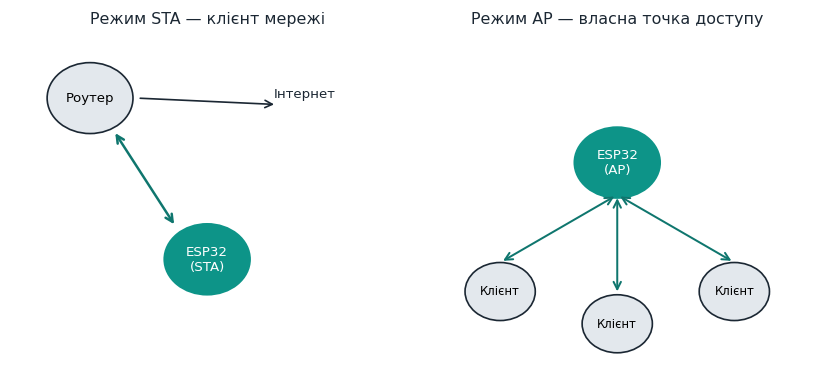

In [29]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2), dpi=120)
for ax, mode in zip(axes, ["sta", "ap"]):
    ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
    if mode == "sta":
        ax.add_patch(plt.Circle((2, 8), 1.1, color=GRID, ec=TEXT))
        ax.text(2, 8, "Роутер", ha="center", va="center", fontsize=8)
        ax.add_patch(plt.Circle((5, 3), 1.1, color=ACCENT))
        ax.text(5, 3, "ESP32\n(STA)", ha="center", va="center", fontsize=8, color="white")
        ax.annotate("", xy=(4.2, 4), xytext=(2.6, 7),
                    arrowprops=dict(arrowstyle="<->", color=ACCENT_DARK, lw=1.5))
        ax.text(7.5, 8, "Інтернет", ha="center", fontsize=8, color=TEXT)
        ax.annotate("", xy=(6.8, 7.8), xytext=(3.2, 8),
                    arrowprops=dict(arrowstyle="->", color=TEXT, lw=1))
        ax.set_title("Режим STA — клієнт мережі", fontsize=9.5, color=TEXT)
    else:
        ax.add_patch(plt.Circle((5, 6), 1.1, color=ACCENT))
        ax.text(5, 6, "ESP32\n(AP)", ha="center", va="center", fontsize=8, color="white")
        for (x, y) in [(2, 2), (8, 2), (5, 1)]:
            ax.add_patch(plt.Circle((x, y), 0.9, color=GRID, ec=TEXT))
            ax.text(x, y, "Клієнт", ha="center", va="center", fontsize=7)
            ax.annotate("", xy=(x, y + 0.9), xytext=(5, 5),
                        arrowprops=dict(arrowstyle="<->", color=ACCENT_DARK, lw=1.2))
        ax.set_title("Режим AP — власна точка доступу", fontsize=9.5, color=TEXT)
plt.tight_layout()
plt.show()

### 14.8. MQTT — легша альтернатива HTTP для IoT {-}

Для частих коротких повідомлень з давачів **MQTT** (протокол publish/subscribe поверх TCP) легший за HTTP: він тримає одне постійне з'єднання замість того, щоб відкривати нове TCP-з'єднання на кожен запит, як типовий HTTP-виклик. Стороння, але дуже поширена для MicroPython бібліотека `umqtt.simple` (Розділ 11.3) реалізує клієнтську частину:
```python
from umqtt.simple import MQTTClient

client = MQTTClient(client_id="esp32-lab", server="broker.example.com")
client.connect()
client.publish(b"lab/temperature", b"22.5")
client.disconnect()
```
Компроміс: MQTT зменшує накладні витрати для частих невеликих повідомлень, але додає ще один компонент інфраструктури — сервер-посередник (**брокер**), через який проходять усі повідомлення, тоді як HTTP-запит з 14.3 йде напряму на сервер.

### 14.9. Практичний приклад: власний мінімальний вебсервер стану {-}

Розгорнемо ідею з 14.3 про власний вебсервер — приймаємо вхідні з'єднання напряму через `socket`, без сторонніх бібліотек:
```python
import socket

def start_status_server(get_status):
    addr = socket.getaddrinfo("0.0.0.0", 80)[0][-1]
    s = socket.socket()
    s.bind(addr)
    s.listen(1)
    print("Сервер слухає на порту 80")

    while True:
        conn, client_addr = s.accept()
        request = conn.recv(1024)               # достатньо для простого GET-запиту
        response = "HTTP/1.1 200 OK\r\nContent-Type: text/plain\r\n\r\n" + get_status()
        conn.send(response)
        conn.close()

start_status_server(lambda: "Температура: 22.5 C")
```
Приклад навмисно спрощений (без розбору заголовків запиту, без обробки кількох одночасних клієнтів) — у реальному проєкті варто додати `try/except OSError` (Розділ 18.3) навколо роботи із `conn`, оскільки клієнт може розірвати з'єднання посеред обміну даними.

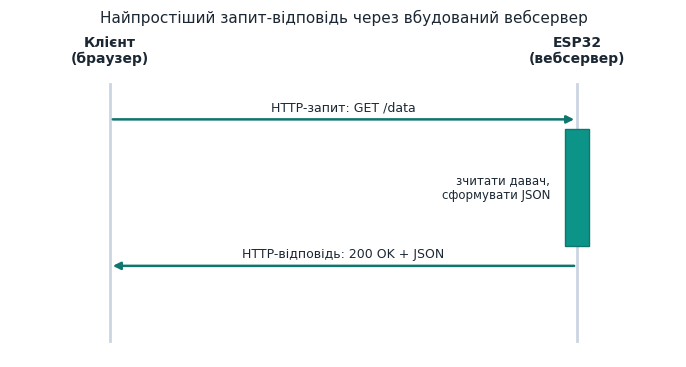

In [30]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
xc, xs = 1.5, 8.5
ax.text(xc, 9.4, "Клієнт\n(браузер)", ha="center", va="center", fontsize=10, fontweight="bold", color=TEXT)
ax.text(xs, 9.4, "ESP32\n(вебсервер)", ha="center", va="center", fontsize=10, fontweight="bold", color=TEXT)
for x in (xc, xs):
    ax.plot([x, x], [0.5, 8.4], color="#CBD5E1", lw=2, zorder=0)
ax.annotate("", xy=(xs, 7.3), xytext=(xc, 7.3), arrowprops=dict(arrowstyle="-|>", color=ACCENT_DARK, lw=1.8))
ax.text(5, 7.55, "HTTP-запит: GET /data", ha="center", fontsize=9, color=TEXT)
ax.add_patch(mpatches.Rectangle((xs - 0.18, 3.4), 0.36, 3.6, facecolor=ACCENT, edgecolor=ACCENT_DARK))
ax.text(xs - 0.4, 5.2, "зчитати давач,\nсформувати JSON", ha="right", va="center", fontsize=8.5, color=TEXT)
ax.annotate("", xy=(xc, 2.8), xytext=(xs, 2.8), arrowprops=dict(arrowstyle="-|>", color=ACCENT_DARK, lw=1.8))
ax.text(5, 3.05, "HTTP-відповідь: 200 OK + JSON", ha="center", fontsize=9, color=TEXT)
ax.set_title("Найпростіший запит-відповідь через вбудований вебсервер", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чим режим STA відрізняється від режиму AP модуля network?</summary>

> **Відповідь:** У режимі STA плата підключається як клієнт до наявної Wi-Fi мережі; у режимі AP плата сама створює власну Wi-Fi мережу, до якої підключаються інші пристрої.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Опишіть послідовність кроків підключення плати до наявної Wi-Fi мережі.</summary>

> **Відповідь:** Створити `WLAN(network.STA_IF)`, активувати (`active(True)`), викликати `connect(ssid, password)`, а потім чекати в циклі, поки `isconnected()` не поверне `True` — після цього `ifconfig()` покаже отриману IP-адресу.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> У якій ситуації доцільно перевести плату в режим точки доступу (AP)?</summary>

> **Відповідь:** Коли плата сама має створити Wi-Fi мережу — наприклад, для першого налаштування пристрою зі смартфона без наявного роутера поруч.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Для чого призначена бібліотека `urequests` і чим вона зручніша за прямі сокети для простих запитів?</summary>

> **Відповідь:** Вона призначена для зручного виконання простих HTTP-запитів (`get`, `post` тощо) — значно простіша у використанні за роботу з сирими сокетами напряму для типових запит-відповідь сценаріїв.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому важливо закривати HTTP-з'єднання (`response.close()`) на мікроконтролері?</summary>

> **Відповідь:** Бо ресурси плати обмежені, і незакриті з'єднання можуть їх вичерпати.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Яку практичну перевагу дає WebREPL порівняно зі звичайним REPL через USB?</summary>

> **Відповідь:** Дозволяє підключатись до консолі плати через Wi-Fi, без потреби у фізичному USB-кабелі.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Наведіть приклад пристрою, для якого WebREPL суттєво спрощує обслуговування після встановлення.</summary>

> **Відповідь:** Пристрій, встановлений на місці експлуатації без легкого доступу до USB-порту (наприклад, під стелею чи в закритому корпусі) — саме приклад з тексту розділу 14.4.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Чому проста нескінченна спроба перепідключення без затримки є поганою практикою, і що таке експоненційна затримка (backoff)?</summary>

> **Відповідь:** Постійні спроби без затримки безглуздо навантажують радіомодуль і мережу під час тимчасової недоступності Wi-Fi. Експоненційна затримка (backoff) — прийом, коли час очікування між повторними спробами подвоюється з кожною невдачею (наприклад, 2, 4, 8, 16 с), даючи мережі час відновитись.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Чим MQTT відрізняється від HTTP-запитів (`urequests`) для періодичної передачі невеликих даних з давача?</summary>

> **Відповідь:** MQTT тримає одне постійне з'єднання з брокером і надсилає короткі publish-повідомлення без накладних витрат на встановлення нового HTTP-з'єднання щоразу, тому він легший для частих невеликих повідомлень, хоча й додає ще один компонент інфраструктури — брокер повідомлень.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 15. Прямий доступ до регістрів та скидання до заводських налаштувань

### Після опрацювання розділу ви зможете: {-}
- пояснити, що таке регістри периферії та коли виправдано звертатись до них напряму
- оцінити ризики роботи з `machine.mem32` та подібними інструментами
- виконати повне скидання плати до «чистого» стану
- інтерпретувати побітову структуру регістра й уникати типової помилки повного перезапису
- пояснити рівні абстракції від Python-виклику до апаратного піна

### 15.1. Що таке регістри периферії {-}

Усе, що ми робили через зручні класи (`Pin`, `PWM`, `I2C`...), «під капотом» зводиться до запису й читання конкретних комірок пам'яті мікроконтролера, що звуться **регістрами** — кожен біт такого регістра має суворо визначене апаратне значення (наприклад, «увімкнути тактування такого-то периферійного блока» чи «встановити такий-то пін у високий рівень»). Класи `machine` — це зручна, безпечна «обгортка» над цими регістрами, що ховає деталі й запобігає типовим помилкам.

### 15.2. machine.mem32 — прямий доступ {-}

MicroPython дозволяє й прямий доступ до пам'яті периферії — переважно для просунутих сценаріїв (використання можливостей, яких ще немає у зручних класах, чи максимальна швидкодія):
```python
import machine

# Приклад демонструє сам принцип; конкретні адреси регістрів
# залежать від моделі чипа й беруться з технічної документації (Technical Reference Manual)
GPIO_OUT_REG = 0x3FF44004

value = machine.mem32[GPIO_OUT_REG]     # прочитати значення регістра
machine.mem32[GPIO_OUT_REG] = value | (1 << 2)   # встановити конкретний біт
```
**Важливо:** помилка в адресі чи значенні регістра при прямому доступі може призвести до непередбачуваної поведінки аж до зависання плати — на відміну від помилок у зручних класах `machine.Pin` тощо, які зазвичай супроводжуються зрозумілим повідомленням про помилку Python. Прямий доступ до регістрів варто застосовувати лише тоді, коли документація чипа детально вивчена, а стандартні класи дійсно не покривають потрібну можливість.

### 15.3. Скидання до заводських налаштувань (factory reset) {-}

Іноді потрібно повністю очистити плату — видалити всі файли користувача (`main.py`, збережені дані, конфігурації) і повернутись до «чистого» стану, наприклад, перед передачею плати іншому студенту чи при діагностиці незрозумілих проблем. Найнадійніший спосіб — те саме `erase_flash` з Розділу 1.5, після чого прошивку записують заново:
```bash
esptool.py --port COM5 erase_flash
esptool.py --port COM5 --baud 460800 write_flash -z 0x1000 esp32-firmware.bin
```
Альтернативний, «м'якший» спосіб — програмно видалити всі файли з файлової системи, не чіпаючи саму прошивку:
```python
import os

for name in os.listdir():
    os.remove(name)
```
Цей спосіб швидший, але не повертає налаштування низького рівня (наприклад, розділи flash-пам'яті) до справді початкового стану — для повної гарантії «чистої» плати надійніший саме `erase_flash`.

### 15.4. Коли НЕ варто використовувати прямий доступ до регістрів {-}

На практиці більшості навчальних і навіть комерційних проєктів **ніколи не знадобиться** `machine.mem32` — стандартні класи (`Pin`, `PWM`, `I2C`, `SPI`, ...) покривають переважну більшість задач безпечно й зрозуміліше. Прямий доступ виправданий лише у вузьких випадках: реалізація підтримки periферії, якої ще немає у MicroPython, потреба у максимальній швидкодії на рівні окремих тактів процесора, або навчальні цілі — зрозуміти, як влаштована апаратура «під капотом» бібліотек. У решті випадків він лише додає ризик важковловимих помилок і робить код менш переносним між різними моделями чипів (адреси регістрів відрізняються навіть між ESP32 і ESP32-S3!).

### 15.5. Побітова структура регістра: приклад GPIO_OUT_REG {-}

У прикладі з 15.2 вираз `value | (1 << 2)` — не випадковість, а єдиний безпечний спосіб змінити один-єдиний біт 32-бітного регістра, не зачепивши решту:
```python
# ПОМИЛКА: перезаписує ВЕСЬ регістр, скидаючи всі інші біти в 0 —
# тобто вимикає всі інші піни, керовані цим самим регістром!
machine.mem32[GPIO_OUT_REG] = 1 << 2

# ПРАВИЛЬНО: спершу зчитує поточне значення, тоді змінює лише потрібний біт
machine.mem32[GPIO_OUT_REG] = machine.mem32[GPIO_OUT_REG] | (1 << 2)
```
Побітове АБО (`|`) з поточним значенням — стандартний прийом «встановити біт, не чіпаючи інших»; аналогічно, для скидання одного біта в 0 без впливу на решту використовують побітове І з інверсією: `value & ~(1 << 2)`.

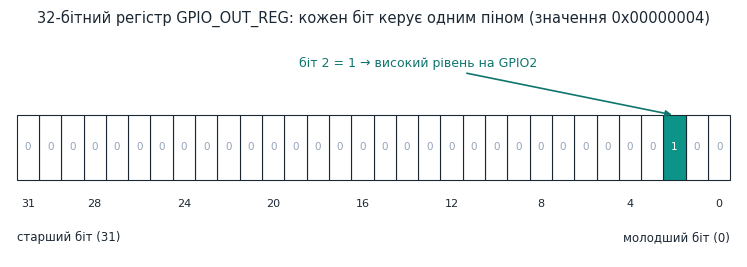

In [31]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, ax = plt.subplots(figsize=(7.6, 2.8))
n = 32
for bit in range(n):
    x = n - 1 - bit                       # старший біт (31) ліворуч, молодший (0) праворуч
    on = bit == 2
    ax.add_patch(mpatches.Rectangle((x, 0), 1, 1, facecolor=ACCENT if on else "white", edgecolor=TEXT, lw=0.8))
    ax.text(x + 0.5, 0.5, "1" if on else "0", ha="center", va="center", fontsize=7.5,
            color="white" if on else "#94A3B8")
    if bit % 4 == 0 or bit == 31:
        ax.text(x + 0.5, -0.3, str(bit), ha="center", va="top", fontsize=8, color=TEXT)
ax.annotate("біт 2 = 1 → високий рівень на GPIO2", xy=(n - 3 + 0.5, 1.0), xytext=(18, 1.75), fontsize=9,
            color=ACCENT_DARK, ha="center", arrowprops=dict(arrowstyle="-|>", color=ACCENT_DARK, lw=1.2))
ax.text(0, -0.95, "старший біт (31)", fontsize=8.5, color=TEXT, ha="left")
ax.text(n, -0.95, "молодший біт (0)", fontsize=8.5, color=TEXT, ha="right")
ax.set_xlim(-0.3, n + 0.3); ax.set_ylim(-1.2, 2.3); ax.axis("off")
ax.set_title("32-бітний регістр GPIO_OUT_REG: кожен біт керує одним піном (значення 0x00000004)",
             fontsize=10.5, color=TEXT)
plt.tight_layout()
plt.show()

### 15.6. Рівні абстракції: від Python-виклику до апаратного піна {-}

Коли ми пишемо `Pin(2, Pin.OUT).value(1)`, виконання проходить кілька рівнів: Python-виклик → C-реалізація класу `machine.Pin`, вбудована у прошивку MicroPython (порт ESP32 MicroPython побудований поверх фреймворка **ESP-IDF** від Espressif) → запис у відповідний регістр периферії → фізична зміна напруги на виводі мікроконтролера. Розуміння цих рівнів пояснює, чому пряме звернення до регістра (15.2) і виклик через `machine.Pin` в кінцевому підсумку роблять те саме — просто на різній «висоті» абстракції.

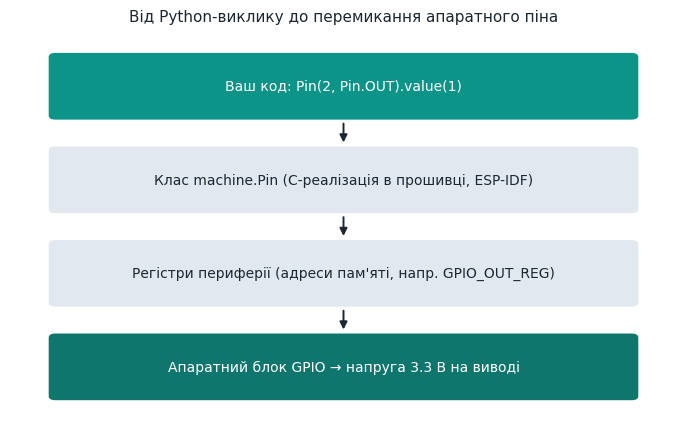

In [32]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")
levels = [
    ("Ваш код: Pin(2, Pin.OUT).value(1)", ACCENT, "white"),
    ("Клас machine.Pin (C-реалізація в прошивці, ESP-IDF)", "#E2E8F0", TEXT),
    ("Регістри периферії (адреси пам'яті, напр. GPIO_OUT_REG)", "#E2E8F0", TEXT),
    ("Апаратний блок GPIO → напруга 3.3 В на виводі", ACCENT_DARK, "white"),
]
h, gap = 1.6, 0.7
for i, (text, color, tcol) in enumerate(levels):
    y = 9.4 - h - i * (h + gap)
    ax.add_patch(mpatches.FancyBboxPatch((0.6, y), 8.8, h, boxstyle="round,pad=0.02,rounding_size=0.1",
                                         facecolor=color, edgecolor="none"))
    ax.text(5, y + h / 2, text, ha="center", va="center", fontsize=10, color=tcol)
    if i < len(levels) - 1:
        ax.annotate("", xy=(5, y - gap + 0.05), xytext=(5, y - 0.05),
                    arrowprops=dict(arrowstyle="-|>", color=TEXT, lw=1.4))
ax.set_title("Від Python-виклику до перемикання апаратного піна", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

### 15.7. Типові небезпеки прямого доступу до регістрів {-}

- **Адреси відрізняються між моделями чипа.** ESP32 класичний, ESP32-S2, ESP32-S3 і ESP32-C3 мають різні периферійні блоки й адреси регістрів — код із прямим доступом, написаний для однієї моделі, як правило, не запрацює на іншій без змін, на відміну від коду через `machine.Pin`, який однаковий для всіх портів.
- **«Невдалий момент» запису.** Запис у регістр під час активної роботи того самого периферійного блока (наприклад, під час DMA-передачі через I2S, Розділ 9.4) може призвести до пошкодження даних, що передаються, чи зависання периферії.
- **Тиха неправильна поведінка замість помилки.** На відміну від помилки Python (яку REPL покаже як traceback, Розділ 18.1), помилка в прямому доступі до регістра може взагалі не викликати жодного повідомлення — просто неправильна поведінка апаратури, що суттєво ускладнює діагностику.

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Що таке регістр периферії і як він співвідноситься зі зручними класами модуля `machine`?</summary>

> **Відповідь:** Регістр — конкретна комірка пам'яті мікроконтролера, кожен біт якої має суворо визначене апаратне значення. Класи `machine` (`Pin`, `PWM`, `I2C`...) — зручна, безпечна «обгортка» над цими регістрами, що ховає деталі й запобігає типовим помилкам.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> У чому ризик прямого доступу через `machine.mem32` порівняно з використанням класу `Pin`?</summary>

> **Відповідь:** Помилка в адресі чи значенні регістра при прямому доступі може призвести до непередбачуваної поведінки аж до зависання плати, тоді як помилки в зручних класах `machine.Pin` тощо зазвичай супроводжуються зрозумілим повідомленням про помилку Python.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Коли виправдано звертатись до регістрів напряму, а коли краще користуватись стандартними класами?</summary>

> **Відповідь:** Прямий доступ виправданий лише у вузьких випадках: реалізація підтримки периферії, якої ще немає у стандартних класах, потреба у максимальній швидкодії, або навчальні цілі. У решті випадків краще користуватись стандартними класами — вони безпечніші й покривають більшість задач.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Опишіть два способи скидання плати до «чистого» стану та порівняйте їх надійність.</summary>

> **Відповідь:** Повне `erase_flash` з наступним записом прошивки заново — найнадійніший спосіб, що повертає плату до справді чистого стану. Альтернативний, «м'якший» спосіб — програмно видалити всі файли з файлової системи (`os.remove()` для кожного з `os.listdir()`) — швидший, але не чіпає низькорівневі налаштування (наприклад, розділи flash-пам'яті).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому програмне видалення файлів не завжди еквівалентне повному `erase_flash`?</summary>

> **Відповідь:** Бо воно не повертає низькорівневі налаштування (наприклад, розділи flash-пам'яті) до справді початкового стану, на відміну від повного `erase_flash`.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Чому `machine.mem32[REG] = 1 << 2` є помилкою, тоді як `machine.mem32[REG] = machine.mem32[REG] | (1 << 2)` — правильний спосіб встановити один біт?</summary>

> **Відповідь:** Перший варіант повністю перезаписує весь регістр значенням з єдиним встановленим бітом, скидаючи в 0 усі інші біти (а отже, вимикаючи всі інші піни, керовані цим регістром). Другий спершу зчитує поточне значення регістра і застосовує побітове АБО, змінюючи лише потрібний біт і залишаючи решту без змін.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Чому код із прямим доступом до регістрів (`machine.mem32`), написаний для класичного ESP32, як правило, не запрацює без змін на ESP32-S3?</summary>

> **Відповідь:** Різні моделі чипа мають різні периферійні блоки й, відповідно, різні адреси регістрів у пам'яті — на відміну від коду через зручні класи `machine.Pin` тощо, який однаковий для різних портів MicroPython.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 16. Асинхронне програмування (uasyncio)

### Після опрацювання розділу ви зможете: {-}
- пояснити принцип кооперативної багатозадачності на відміну від апаратних переривань і таймерів
- писати корутини за допомогою async def / await
- запускати й комбінувати кілька незалежних задач в одному циклі подій
- оцінювати, коли asyncio доцільніший за ручний планувальник з Розділу 4
- уникати типових пасток asyncio (забутий await, блокуючі виклики всередині корутин)
- використовувати asyncio.gather та скасування задач

### 16.1. Проблема, яку вирішує asyncio {-}

У Розділі 4.6 ми вручну написали кооперативний планувальник на основі `time.ticks_ms()`, щоб виконувати кілька задач «одночасно» без блокування. Це працює, але з ростом кількості задач і появою власне **очікування** (наприклад, «почекати відповідь по мережі, не блокуючи все інше») ручний код стає громіздким. **`asyncio`** (у MicroPython — модуль `asyncio`, у старіших версіях `uasyncio`) — стандартна бібліотека Python для **кооперативної багатозадачності**: багато незалежних «легких потоків» (корутин) виконуються по черзі в одному циклі подій (event loop), самі добровільно «поступаючись» одна одній у моменти очікування.

### 16.2. Корутини: async def та await {-}

```python
import asyncio

async def blink(pin, interval_s):
    while True:
        pin.toggle()
        await asyncio.sleep(interval_s)     # "поступитись" іншим задачам на цей час

async def main():
    from machine import Pin
    led = Pin(2, Pin.OUT)
    asyncio.create_task(blink(led, 0.5))     # запустити як окрему задачу у фоні
    while True:
        print("Головна задача працює далі")
        await asyncio.sleep(2)

asyncio.run(main())
```
- `async def` оголошує **корутину** — функцію, яку можна призупиняти й відновлювати.
- `await asyncio.sleep(x)` — **некоблокуюча** пауза: на відміну від `time.sleep(x)`, вона не зупиняє весь мікроконтролер, а лише «повідомляє» цикл подій, що цю задачу можна відкласти й тим часом виконати інші.
- `asyncio.create_task(...)` реєструє корутину як окрему задачу, що виконуватиметься «паралельно» (насправді — по черзі, кооперативно) з іншими.
- `asyncio.run(main())` запускає цикл подій з головною корутиною й працює, доки вона не завершиться (у прикладі — нескінченно).

### 16.3. Ключове правило: не блокувати цикл подій {-}

Кооперативна багатозадачність працює лише доти, доки жодна корутина не «монополізує» процесор надовго. Якщо всередині `async def` викликати **звичайний** `time.sleep()` замість `await asyncio.sleep()`, увесь цикл подій зупиниться на цей час — жодна інша задача не виконається, як і при звичайному блокуючому коді:

```python
async def bad_example():
    time.sleep(2)          # НЕПРАВИЛЬНО: блокує весь цикл подій, а не лише цю задачу

async def good_example():
    await asyncio.sleep(2)  # ПРАВИЛЬНО: інші задачі продовжують виконуватись
```
Те саме стосується довгих обчислень без жодного `await` всередині циклу — вони теж «заморожують» усі інші задачі, доки не завершаться.

### 16.4. Очікування на події: asyncio та апаратура {-}

`asyncio` добре поєднується з перериваннями (Розділ 3.3) через об'єкти-події (`asyncio.Event` — доступний у деяких портах, або простий прапорець, що встановлюється в обробнику переривання й перевіряється корутиною):

```python
import asyncio
from machine import Pin

button_pressed = False

def on_press(pin):
    global button_pressed
    button_pressed = True

button = Pin(15, Pin.IN, Pin.PULL_UP)
button.irq(trigger=Pin.IRQ_FALLING, handler=on_press)

async def watch_button():
    global button_pressed
    while True:
        if button_pressed:
            print("Кнопка натиснута!")
            button_pressed = False
        await asyncio.sleep_ms(20)          # коротка пауза — не навантажує процесор

asyncio.run(watch_button())
```
Обробник переривання лишається мінімальним (лише прапорець), а вся «важча» логіка обробки виконується в звичайній корутині, що періодично перевіряє цей прапорець — поєднання найкращих практик з обох підходів.

### 16.5. Практичний приклад: датчик + дисплей + мережа одночасно {-}

Ось де asyncio справді розкривається — три незалежні задачі, що раніше вимагали б окремих таймерів чи ручного планувальника, тепер читаються як прямолінійний послідовний код:

```python
import asyncio
from machine import Pin, I2C, ADC
import ssd1306

i2c = I2C(0, scl=Pin(22), sda=Pin(21))
oled = ssd1306.SSD1306_I2C(128, 64, i2c)
pot = ADC(Pin(34))
pot.atten(ADC.ATTN_11DB)

latest_value = 0

async def read_sensor_loop():
    global latest_value
    while True:
        latest_value = pot.read_u16()
        await asyncio.sleep_ms(200)

async def update_display_loop():
    while True:
        oled.fill(0)
        oled.text("ADC: {}".format(latest_value), 0, 0)
        oled.show()
        await asyncio.sleep(1)

async def report_network_loop():
    while True:
        print("(тут був би виклик urequests.post з Розділу 14.6)")
        await asyncio.sleep(30)

async def main():
    asyncio.create_task(read_sensor_loop())
    asyncio.create_task(update_display_loop())
    await report_network_loop()          # головна задача теж "нескінченна" — тримає програму живою

asyncio.run(main())
```
Порівняйте цей код з тим, як довелося б координувати три таймери й глобальні прапорці вручну — asyncio робить намір коду («ці три речі відбуваються незалежно») явним і читабельним.

### 16.6. Ручний планувальник проти asyncio: погляд на розклад виконання {-}

Обидва підходи — ручний планувальник з Розділу 4.6 і asyncio — вирішують ту саму задачу («кілька справ одночасно, без блокування»), але по-різному організовують перемикання між задачами. Порівняємо, як виглядає розклад виконання двох корутин з прикладу 16.2 (`blink()` і `main()`) на реальній осі часу:

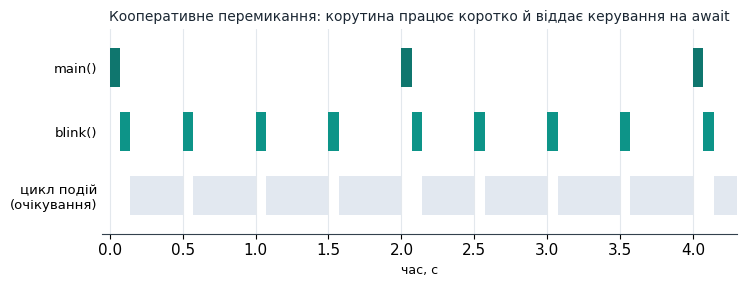

In [33]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

# Приклад 16.2: blink() перемикає LED кожні 0.5 с, main() друкує повідомлення кожні 2 с.
# Тривалість виконання корутин (насправді — мікросекунди) збільшено для наочності.
w = 0.07
main_runs = [(0.0, w), (2.0, w), (4.0, w)]
blink_runs = [(0.0 + w, w)] + [(k * 0.5, w) for k in range(1, 9) if k * 0.5 not in (2.0, 4.0)] \
             + [(2.0 + w, w), (4.0 + w, w)]
busy = sorted(main_runs + blink_runs)
idle, t = [], 0.0
for s, d in busy:
    if s > t:
        idle.append((t, s - t))
    t = max(t, s + d)
idle.append((t, 4.3 - t))

fig, ax = plt.subplots(figsize=(7.6, 3.0))
rows = [("main()", main_runs, ACCENT_DARK), ("blink()", blink_runs, ACCENT), ("цикл подій\n(очікування)", idle, "#E2E8F0")]
for i, (name, segs, color) in enumerate(rows):
    ax.broken_barh(segs, (len(rows) - 1 - i - 0.3, 0.6), facecolors=color)
ax.set_yticks([2, 1, 0]); ax.set_yticklabels([r[0] for r in rows], fontsize=9.5)
for k in np.arange(0, 4.5, 0.5):
    ax.axvline(k, color=GRID, lw=0.8, zorder=0)
ax.set_xlim(-0.05, 4.3); ax.set_ylim(-0.6, 2.6)
ax.set_xlabel("час, с", fontsize=9)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Кооперативне перемикання: корутина працює коротко й віддає керування на await",
             fontsize=10, color=TEXT)
plt.tight_layout()
plt.show()

### 16.7. Життєвий цикл корутини {-}

Корутина проходить через кілька станів від створення до завершення — розуміння цього циклу допомагає передбачити, чому та коли код усередині `async def` виконується (або призупиняється):

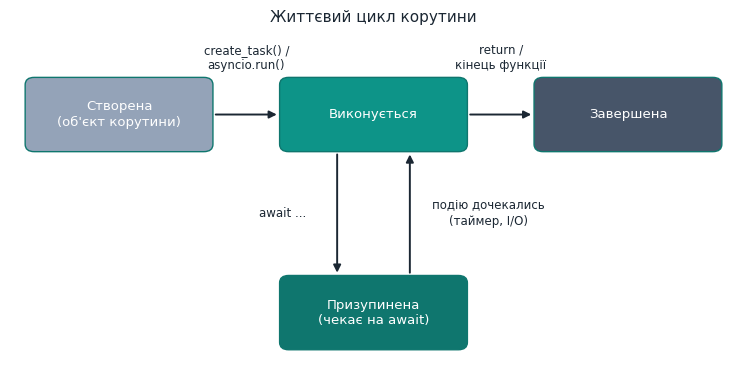

In [34]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _block(ax, x, y, w, h, text, color=ACCENT, tcolor="white", fs=9):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                   linewidth=1, edgecolor=ACCENT_DARK, facecolor=color)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=tcolor)

fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.set_xlim(0, 12); ax.set_ylim(0, 7); ax.axis("off")
states = {
    "created": (0.3, 4.6, "Створена\n(об'єкт корутини)", "#94A3B8"),
    "running": (4.5, 4.6, "Виконується", ACCENT),
    "waiting": (4.5, 0.6, "Призупинена\n(чекає на await)", ACCENT_DARK),
    "done":    (8.7, 4.6, "Завершена", "#475569"),
}
W, H = 3.0, 1.4
for x, y, text, color in states.values():
    _block(ax, x, y, W, H, text, color=color, fs=9.5)

def arrow(p1, p2, text, tx, ty, rad=0.0):
    ax.annotate("", xy=p2, xytext=p1,
                arrowprops=dict(arrowstyle="-|>", color=TEXT, lw=1.4, connectionstyle=f"arc3,rad={rad}"))
    ax.text(tx, ty, text, ha="center", va="center", fontsize=8.5, color=TEXT,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))

arrow((3.35, 5.3), (4.45, 5.3), "create_task() /\nasyncio.run()", 3.9, 6.45)
arrow((7.55, 5.3), (8.65, 5.3), "return /\nкінець функції", 8.1, 6.45)
arrow((5.4, 4.55), (5.4, 2.05), "await ...", 4.5, 3.3)
arrow((6.6, 2.05), (6.6, 4.55), "подію дочекались\n(таймер, I/O)", 7.9, 3.3)
ax.set_title("Життєвий цикл корутини", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

### 16.8. Типові пастки asyncio {-}

- **Забутий `await` чи `create_task`.** Виклик `blink(led, 0.5)` без `await` чи `asyncio.create_task()` лише створює об'єкт корутини — її тіло взагалі не почне виконуватись. Це тиха помилка: рядок коду не викликає жодної явної помилки Python у цьому місці.
- **Блокуючий виклик усередині корутини.** Як показано в 16.3, звичайний `time.sleep()` чи довге обчислення без `await` заморожує геть усі задачі, а не лише поточну.
- **Необроблений виняток у фоновій задачі.** Задача, запущена через `create_task()`, що кидає необроблений виняток, може мовчки зупинитися, не «зваливши» решту програми явним повідомленням — для задач, які мають переживати окремі збої, варто обгортати їхнє тіло в `try/except` (Розділ 18.3).

### 16.9. asyncio.gather та скасування задач {-}

```python
import asyncio

async def worker(name, delay):
    await asyncio.sleep(delay)
    return name + " готово"

async def main():
    results = await asyncio.gather(
        worker("A", 1),
        worker("B", 2),
    )
    print(results)

    task = asyncio.create_task(worker("C", 10))
    await asyncio.sleep(1)
    task.cancel()          # більше не потрібна - скасовуємо, не чекаючи всі 10 секунд
    print("Задачу C скасовано достроково")

asyncio.run(main())
```
`asyncio.gather()` дозволяє запустити кілька корутин і дочекатись усіх результатів одночасно, замість послідовного `await` кожної по черзі. `task.cancel()` — спосіб достроково зупинити задачу, що більше не потрібна (наприклад, користувач скасував операцію), не чекаючи її природного завершення.

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чим кооперативна багатозадачність (asyncio) принципово відрізняється від апаратних переривань?</summary>

> **Відповідь:** У кооперативній багатозадачності багато корутин виконуються по черзі в одному циклі подій, добровільно «поступаючись» одна одній у моменти очікування (`await`). Апаратні переривання, навпаки, виконуються «поза чергою» негайно у відповідь на подію, обробником, що має бути гранично коротким.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Що станеться, якщо всередині корутини викликати звичайний `time.sleep()` замість `await asyncio.sleep()`?</summary>

> **Відповідь:** Увесь цикл подій зупиниться на цей час — жодна інша задача не виконається, як і при звичайному блокуючому коді, що зводить нанівець сенс asyncio.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Яку роль виконує `asyncio.create_task()`?</summary>

> **Відповідь:** Реєструє корутину як окрему задачу, що виконуватиметься «паралельно» (насправді — по черзі, кооперативно) з іншими задачами циклу подій.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Як поєднати апаратне переривання з асинхронною задачею, не порушуючи правило «короткий обробник переривання»?</summary>

> **Відповідь:** Обробник переривання лишають мінімальним (лише встановлює прапорець чи об'єкт-подію), а всю «важчу» логіку обробки виконують у звичайній корутині, що періодично перевіряє цей прапорець — так, як показано в прикладі з кнопкою в розділі 16.4.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Перепишіть кооперативний планувальник із Розділу 4.6 (три задачі з різними інтервалами) на asyncio.</summary>

> **Відповідь:** *Практична вправа без єдиної фіксованої відповіді.* Ідея (за зразком прикладу з розділу 16.5): кожну задачу з розділу 4.6 оформити як окрему корутину `async def task(): while True: <дія>; await asyncio.sleep(interval_s)`, запустити дві з них через `asyncio.create_task(...)`, а третю — дочекатись (`await`) у `main()`, який запускається через `asyncio.run(main())`.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> У якому випадку ручний планувальник на `time.ticks_ms()` з Розділу 4.6 може виявитися доречнішим за повноцінний asyncio?</summary>

> **Відповідь:** *Висновок, що прямо випливає з мотивації розділу 16.1, а не окрема цитата з тексту:* поки задач мало і жодна з них не потребує справжнього очікування (наприклад, відповіді по мережі) без блокування — ручний планувальник лишається простим і достатнім рішенням; asyncio стає виправданим, коли задач стає більше або з'являється потреба саме в неблокуючому очікуванні.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Поясніть, чому приклад з трьома одночасними задачами (давач, дисплей, мережа) читається простіше на asyncio, ніж через ручні таймери.</summary>

> **Відповідь:** Бо намір коду («ці три речі відбуваються незалежно») стає явним і читабельним, тоді як координація тих самих трьох задач вручну через таймери й глобальні прапорці набагато громіздкіша — саме це порівняння наведено наприкінці розділу 16.5.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Що станеться, якщо викликати корутину як звичайну функцію (`blink(led, 0.5)`) без `await` чи `asyncio.create_task()`?</summary>

> **Відповідь:** Буде лише створено об'єкт корутини, який ніколи не почне виконуватись — виклик сам по собі не запускає її тіло; типова тиха помилка, що не завжди супроводжується явним повідомленням.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Для чого призначений `asyncio.gather()` і чим він відрізняється від послідовного `await` кожної корутини по черзі?</summary>

> **Відповідь:** `asyncio.gather()` запускає кілька корутин одночасно і дочекається результатів усіх, тоді як послідовний `await` кожної по черзі виконував би їх одну за одною, без паралельного (кооперативного) виконання.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 17. Bluetooth Low Energy (BLE) на ESP32

### Після опрацювання розділу ви зможете: {-}
- пояснити різницю між Bluetooth Classic і Bluetooth Low Energy
- орієнтуватись у базовій термінології BLE: сервіси, характеристики, GATT
- реалізувати простий BLE-периферійний пристрій через модуль bluetooth
- оцінювати типові застосування BLE в навчальних та аматорських проєктах
- розшифрувати структуру рекламного BLE-пакета
- уникати типових проблем BLE-розробки (MTU, підписка на notify, UUID)

### 17.1. Bluetooth Classic проти Bluetooth Low Energy {-}

ESP32 підтримує обидва варіанти Bluetooth, але для більшості сучасних невеликих IoT-проєктів використовують саме **BLE (Low Energy)**:

| Критерій | Bluetooth Classic | Bluetooth Low Energy (BLE) |
|---|---|---|
| Споживання енергії | вище | значно нижче — розраховано на батарейні пристрої |
| Швидкість передачі | вища (аудіопотік, файли) | нижча — розрахований на короткі пакети даних |
| Типове застосування | навушники, аудіоколонки, передача файлів | давачі, фітнес-браслети, «розумні» кнопки, маячки (beacons) |
| З'єднання | стабільне «спарювання» на весь сеанс | коротке підключення або взагалі без підключення (реклама-мовлення) |

Для навчальних проєктів на ESP32 (передати показання давача на смартфон, керувати платою з мобільного застосунку) BLE — типовий і рекомендований вибір.

### 17.2. Ключові поняття: GATT, сервіси, характеристики {-}

BLE-периферія (наприклад, наша плата) описує свої дані через ієрархію **GATT (Generic Attribute Profile)**:
- **Сервіс (Service)** — логічне угруповання пов'язаних даних (наприклад, «сервіс температури»), ідентифікується унікальним UUID.
- **Характеристика (Characteristic)** — конкретне значення всередині сервісу (наприклад, «поточна температура»), яке можна читати, записувати або підписатись на сповіщення (notify) при зміні.
- **UUID** — 128-бітний (або скорочений 16-бітний для стандартних, наперед визначених сервісів) унікальний ідентифікатор — щоб клієнт (смартфон) знав, які саме дані він отримує.

### 17.3. Модуль bluetooth: мінімальний периферійний пристрій {-}

```python
import bluetooth
from micropython import const

_IRQ_GATTS_WRITE = const(3)

ble = bluetooth.BLE()
ble.active(True)

SERVICE_UUID = bluetooth.UUID("12345678-1234-5678-1234-56789abcdef0")
CHAR_UUID = bluetooth.UUID("12345678-1234-5678-1234-56789abcdef1")

char = (CHAR_UUID, bluetooth.FLAG_READ | bluetooth.FLAG_NOTIFY)
service = (SERVICE_UUID, (char,))
((char_handle,),) = ble.gatts_register_services((service,))

def advertise():
    name = b"ESP32-Lab"
    adv_data = bytearray(b'\x02\x01\x06') + bytearray((len(name) + 1, 0x09)) + name
    ble.gap_advertise(100_000, adv_data)   # рекламуємо себе кожні 100 мс

def irq_handler(event, data):
    if event == _IRQ_GATTS_WRITE:
        print("Клієнт щось записав у характеристику")

ble.irq(irq_handler)
advertise()
print("BLE-пристрій рекламується як 'ESP32-Lab'")
```
Після запуску цей код зробить плату видимою у списку BLE-пристроїв на смартфоні (у застосунках на кшталт nRF Connect чи LightBlue, популярних для тестування BLE) під іменем `ESP32-Lab`.

### 17.4. Notify: надсилання даних без запиту клієнта {-}

Найкорисніший режим для давачів — **notify**: периферія сама надсилає нове значення підписаному клієнту, щойно воно змінюється, без потреби постійно опитувати пристрій:

```python
import time

def update_temperature(value):
    payload = "{:.1f}".format(value).encode()
    ble.gatts_write(char_handle, payload)
    ble.gatts_notify(0, char_handle, payload)   # 0 — умовний ідентифікатор підключення

while True:
    fake_temp = 22.5   # тут було б реальне зчитування давача (Розділ 11)
    update_temperature(fake_temp)
    time.sleep(2)
```
Це дуже схоже за духом на роботу з UART (Розділ 6) чи MQTT (Розділ 14) — «джерело даних → надіслати підписнику», лише інший транспорт, оптимізований саме під коротку дистанцію й низьке енергоспоживання.

### 17.5. Коли обирати BLE, а коли Wi-Fi {-}

| Критерій | BLE | Wi-Fi (Розділ 14) |
|---|---|---|
| Дистанція | одиниці — десятки метрів | залежить від роутера, зазвичай ширше покриття |
| Споживання енергії | дуже низьке | помітно вище |
| Потрібна інфраструктура | ні — з'єднання напряму зі смартфоном | так — точка доступу/роутер |
| Пропускна здатність | низька | значно вища |
| Типовий сценарій | конфігурація пристрою зі смартфона поруч, батарейні давачі | передача даних на віддалений сервер, хмарні сервіси |

Часто проєкти поєднують обидва: BLE — для першого налаштування пристрою зі смартфона (ввести Wi-Fi пароль зі смартфона без клавіатури на самій платі), Wi-Fi — для подальшої постійної роботи.

### 17.6. Структура рекламного пакета {-}

Рядок з 17.3, що на перший погляд виглядає як «магічні байти», насправді має чітку, стандартизовану структуру:
```python
adv_data = bytearray(b'\x02\x01\x06') + bytearray((len(name) + 1, 0x09)) + name
```
Формат BLE-реклами — послідовність записів **AD (Advertising Data)**, кожен у форматі `[довжина][тип][дані]`:
- Перший запис `02 01 06`: довжина 2 байти, тип `0x01` (Flags — прапорці режиму), значення `0x06` — комбінація прапорців «LE General Discoverable Mode» і «BR/EDR Not Supported» (пристрій видимий і не підтримує класичний Bluetooth).
- Другий запис `(len(name)+1, 0x09)` + `name`: довжина, тип `0x09` (Complete Local Name — повне ім'я пристрою), і самі байти імені.

Саме ці два записи й формують те, що смартфон побачить як пристрій з іменем `ESP32-Lab` у списку доступних BLE-пристроїв.

### 17.7. BLE-центральний пристрій: сканування {-}

ESP32 може виступати не лише периферією (як у 17.3), а й **центральним пристроєм** (central) — тим, хто сканує ефір і підключається до інших BLE-пристроїв, аналогічно тому, як це робить смартфон:
```python
import bluetooth

ble = bluetooth.BLE()
ble.active(True)

def scan_callback(event, data):
    if event == 5:            # _IRQ_SCAN_RESULT
        addr_type, addr, adv_type, rssi, adv_data = data
        print("Знайдено пристрій, RSSI:", rssi)

ble.irq(scan_callback)
ble.gap_scan(2000, 30000, 30000)   # сканувати 2 секунди
```
Точні значення параметрів (тривалість, інтервал, вікно сканування в мікросекундах) варто звіряти з актуальною документацією модуля `bluetooth` — вони можуть відрізнятися між версіями прошивки.

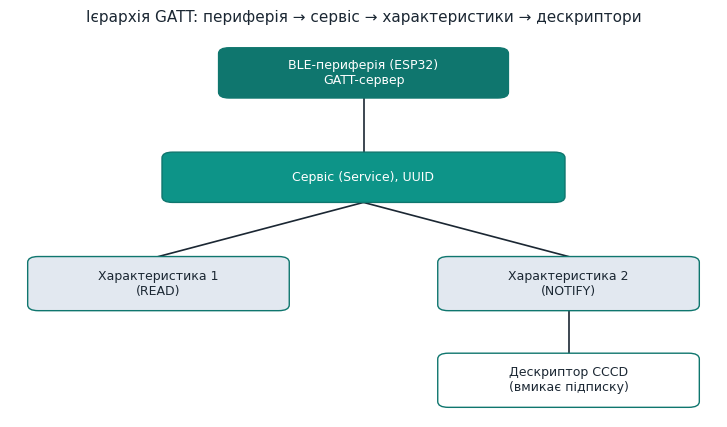

In [35]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _block(ax, x, y, w, h, text, color=ACCENT, tcolor="white", fs=9):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                   linewidth=1, edgecolor=ACCENT_DARK, facecolor=color)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=tcolor)

fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")

def link(x1, y1, x2, y2):
    ax.plot([x1, x2], [y1, y2], color=TEXT, lw=1.2, zorder=0)

_block(ax, 3.0, 8.3, 4.0, 1.2, "BLE-периферія (ESP32)\nGATT-сервер", color=ACCENT_DARK)
_block(ax, 2.2, 5.6, 5.6, 1.2, "Сервіс (Service), UUID", color=ACCENT)
_block(ax, 0.3, 2.8, 3.6, 1.3, "Характеристика 1\n(READ)", color="#E2E8F0", tcolor=TEXT)
_block(ax, 6.1, 2.8, 3.6, 1.3, "Характеристика 2\n(NOTIFY)", color="#E2E8F0", tcolor=TEXT)
_block(ax, 6.1, 0.3, 3.6, 1.3, "Дескриптор CCCD\n(вмикає підписку)", color="white", tcolor=TEXT)
link(5.0, 8.25, 5.0, 6.85)
link(5.0, 5.55, 2.1, 4.15)
link(5.0, 5.55, 7.9, 4.15)
link(7.9, 2.75, 7.9, 1.65)
ax.set_title("Ієрархія GATT: периферія → сервіс → характеристики → дескриптори", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

### 17.8. Типові проблеми BLE-розробки {-}

- **Обмеження розміру пакета (MTU).** BLE-пакети малі за замовчуванням (типово близько 20 байт корисного навантаження до узгодження більшого MTU) — довгі повідомлення (наприклад, JSON) потрібно розбивати на частини або узгоджувати більший MTU, чого зазвичай не доводиться робити явно при HTTP (Розділ 14).
- **Клієнт не отримує notify.** Часто причина в тому, що клієнтський застосунок не підписався на характеристику (не записав спеціальний дескриптор CCCD) — сама наявність `FLAG_NOTIFY` на стороні периферії ще не означає, що підписка активна.
- **Плутанина UUID.** Сервіс і характеристика повинні мати УЗГОДЖЕНІ UUID на обох сторонах (периферія й застосунок клієнта) — одруківка в UUID є однією з найчастіших причин «пристрій видно, підключення успішне, але дані не приходять».

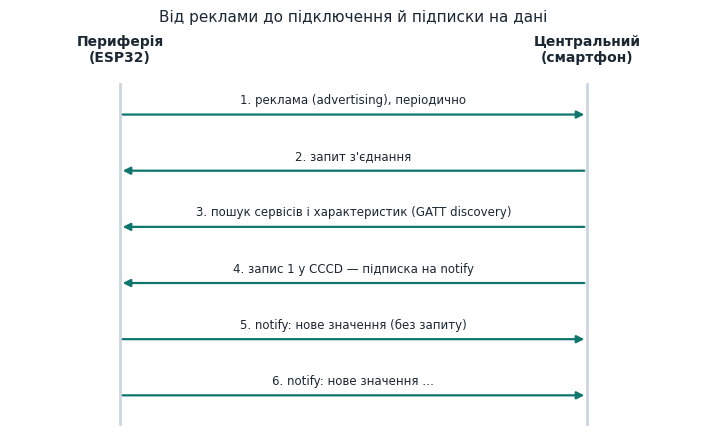

In [36]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.set_xlim(0, 10); ax.set_ylim(0, 10.5); ax.axis("off")
xp, xc = 1.6, 8.4
ax.text(xp, 10.0, "Периферія\n(ESP32)", ha="center", va="center", fontsize=10, fontweight="bold", color=TEXT)
ax.text(xc, 10.0, "Центральний\n(смартфон)", ha="center", va="center", fontsize=10, fontweight="bold", color=TEXT)
for x in (xp, xc):
    ax.plot([x, x], [0.3, 9.1], color="#CBD5E1", lw=2, zorder=0)
msgs = [
    (xp, xc, "1. реклама (advertising), періодично"),
    (xc, xp, "2. запит з'єднання"),
    (xc, xp, "3. пошук сервісів і характеристик (GATT discovery)"),
    (xc, xp, "4. запис 1 у CCCD — підписка на notify"),
    (xp, xc, "5. notify: нове значення (без запиту)"),
    (xp, xc, "6. notify: нове значення …"),
]
for i, (a, b, text) in enumerate(msgs):
    y = 8.3 - i * 1.45
    ax.annotate("", xy=(b, y), xytext=(a, y), arrowprops=dict(arrowstyle="-|>", color=ACCENT_DARK, lw=1.6))
    ax.text(5, y + 0.22, text, ha="center", va="bottom", fontsize=8.5, color=TEXT)
ax.set_title("Від реклами до підключення й підписки на дані", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> У чому головна відмінність BLE від класичного Bluetooth за призначенням і енергоспоживанням?</summary>

> **Відповідь:** BLE має значно нижче енергоспоживання (розрахований на батарейні пристрої) і нижчу швидкість передачі (короткі пакети даних), тоді як Bluetooth Classic споживає більше, але передає дані швидше (аудіопотік, файли) і тримає стабільне з'єднання на весь сеанс.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Що таке GATT-сервіс і GATT-характеристика, і як вони співвідносяться між собою?</summary>

> **Відповідь:** Сервіс — логічне угруповання пов'язаних даних (наприклад, «сервіс температури»), що ідентифікується UUID. Характеристика — конкретне значення всередині сервісу (наприклад, «поточна температура»), яке можна читати, записувати або підписатись на сповіщення. Сервіс містить одну або кілька характеристик.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Навіщо потрібен UUID для сервісу й характеристики?</summary>

> **Відповідь:** Щоб клієнт (наприклад, смартфон) точно знав, які саме дані він отримує чи до якого сервісу/характеристики звертається — UUID є унікальним ідентифікатором.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Чим відрізняється режим notify від звичайного читання характеристики клієнтом?</summary>

> **Відповідь:** У режимі notify периферія сама надсилає нове значення підписаному клієнту, щойно воно змінюється, без потреби постійно опитувати пристрій запитами на читання.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Опишіть сценарій проєкту, де BLE явно кращий вибір за Wi-Fi, і сценарій, де навпаки.</summary>

> **Відповідь:** BLE кращий: батарейний давач чи «розумна» кнопка, що передає короткі дані на смартфон поруч без потреби в інфраструктурі. Wi-Fi кращий: передача даних на віддалений сервер чи в хмарний сервіс, де потрібна вища пропускна здатність і ширше покриття через наявний роутер.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Як зазвичай поєднують BLE і Wi-Fi в одному пристрої? Наведіть практичний приклад.</summary>

> **Відповідь:** BLE використовують для першого налаштування пристрою зі смартфона (наприклад, введення Wi-Fi пароля без клавіатури на самій платі), а Wi-Fi — для подальшої постійної роботи пристрою.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Яким застосунком на смартфоні можна скористатися для тестування власного BLE-периферійного пристрою під час розробки?</summary>

> **Відповідь:** Наприклад, nRF Connect чи LightBlue — застосунки, названі в розділі 17.3 як популярні для тестування BLE.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> У структурі рекламного пакета `bytearray(b'\x02\x01\x06') + ...`, що означають перші три байти `02 01 06`?</summary>

> **Відповідь:** Це перший AD-запис: довжина 2 байти, тип 0x01 (Flags), значення 0x06 — прапорці, що позначають режим LE General Discoverable без підтримки класичного Bluetooth (BR/EDR Not Supported).

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Чому периферія може мати `FLAG_NOTIFY` на характеристиці, але клієнт усе одно не отримує сповіщень?</summary>

> **Відповідь:** Тому що клієнтський застосунок додатково повинен підписатися на характеристику, записавши спеціальний дескриптор CCCD — сама наявність прапорця `FLAG_NOTIFY` на стороні периферії ще не активує підписку автоматично.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 18. Налагодження, обробка винятків та надійність коду

### Після опрацювання розділу ви зможете: {-}
- читати traceback (трасування помилки) MicroPython і знаходити причину збою
- коректно застосовувати try/except для відновлюваних помилок
- поєднувати WDT з обробкою винятків для стійких до збоїв автономних пристроїв
- застосовувати прості практики логування й діагностики без захаращення коду
- орієнтуватись в ієрархії вбудованих винятків
- застосовувати системний алгоритм діагностики «тихих» зависань

### 18.1. Читання traceback {-}

Коли в коді MicroPython трапляється необроблена помилка, REPL виводить **traceback** — список викликів, що призвели до неї, і сам тип помилки в останньому рядку:

```
Traceback (most recent call last):
  File "main.py", line 12, in <module>
  File "main.py", line 7, in read_sensor
OSError: [Errno 110] ETIMEDOUT
```

Читати traceback варто **знизу вгору**: останній рядок (`OSError: ...`) — це сама помилка й короткий опис; рядки вище показують, у якій функції та на якому рядку файлу вона сталась, і хто цю функцію викликав. У прикладі вище: помилка `OSError` сталась на 7-му рядку всередині функції `read_sensor()`, яку викликали з 12-го рядка головного коду.

### 18.2. Типові винятки в MicroPython-проєктах {-}

| Виняток | Типова причина |
|---|---|
| `OSError` | Помилка на рівні «операційної системи» плати: не вдалось відкрити файл, немає відповіді від I2C/датчика, обрив мережі |
| `ValueError` | Некоректне значення передане у функцію (наприклад, `int("abc")`) |
| `TypeError` | Операція над несумісними типами (наприклад, додавання рядка й числа) |
| `AttributeError` | Звернення до неіснуючого атрибута/методу об'єкта (часто — одруківка в назві) |
| `ImportError` | Не вдалось імпортувати модуль (файл відсутній на платі — Розділ 11.3) |
| `KeyboardInterrupt` | Користувач натиснув `Ctrl-C` у REPL |
| `MemoryError` | Не вистачило оперативної пам'яті — типово при роботі з великими буферами на платі з обмеженим RAM |

### 18.3. try/except: обробляти лише те, що можна відновити {-}

Головне правило: **обробляйте конкретний тип помилки, який ви очікуєте й знаєте, як виправити**, а не «ловіть усе підряд» без розбору — інакше можна ненавмисно приховати справжню, серйознішу помилку в коді:

```python
# Погана практика — приховує будь-яку помилку, навіть логічну помилку в самому коді
try:
    result = risky_operation()
except Exception:
    pass

# Краща практика — обробляється конкретна, очікувана ситуація
try:
    sensor.measure()
    temperature = sensor.temperature()
except OSError as e:
    print("Давач тимчасово недоступний:", e)
    temperature = None       # маємо явний, зрозумілий "запасний" стан
```
Блок `finally` гарантовано виконується незалежно від того, сталася помилка чи ні — зручно для звільнення ресурсів (наприклад, закриття з'єднання):

```python
try:
    response = urequests.get(url)
    data = response.text
finally:
    response.close()          # виконається навіть якщо зчитання text викличе помилку
```

### 18.4. Власні винятки для зрозумілішого коду {-}

Для більших проєктів корисно визначати власні класи винятків — це робить код, що їх обробляє, значно зрозумілішим за призначенням, ніж загальний `OSError` чи `ValueError`:

```python
class SensorTimeoutError(Exception):
    pass

def read_temperature_or_raise():
    sensor.measure()
    if sensor.temperature() is None:
        raise SensorTimeoutError("Давач не відповів вчасно")
    return sensor.temperature()

try:
    t = read_temperature_or_raise()
except SensorTimeoutError as e:
    print("Проблема з давачем:", e)
```

### 18.5. Практичний приклад: надійний головний цикл з WDT {-}

Об'єднаємо сторожовий таймер (Розділ 4.3) і обробку винятків — типовий шаблон для автономного пристрою, що має продовжувати працювати роками без нагляду, навіть якщо окрема ітерація дала збій:

```python
from machine import WDT
import time

wdt = WDT(timeout=10_000)

def main_loop_iteration():
    sensor.measure()                 # може кинути OSError
    value = sensor.temperature()
    report(value)                     # може кинути OSError (мережа) — Розділ 14.6

while True:
    try:
        main_loop_iteration()
    except OSError as e:
        print("Ітерація не вдалась, продовжуємо роботу:", e)
    except Exception as e:
        # Неочікувана помилка — логуємо, але НЕ зупиняємо пристрій повністю
        print("Неочікувана помилка:", e)

    wdt.feed()          # підтверджуємо, що головний цикл живий, незалежно від результату ітерації
    time.sleep(5)
```
Ключова ідея: помилка в **одній** ітерації (наприклад, давач разово «не відповів») не повинна «уронити» весь пристрій — цикл продовжує працювати далі, а `wdt.feed()` захищає від інакшого сценарію: якщо цикл усе-таки зависне повністю (наприклад, через помилку в самій бібліотеці), плата автоматично перезавантажиться.

### 18.6. Прості практики логування {-}

На повноцінних комп'ютерах для діагностики використовують бібліотеки логування (`logging` у CPython) з рівнями важливості (DEBUG, INFO, WARNING, ERROR). У MicroPython-проєктах середнього розміру часто достатньо простого підходу, що не захаращує код:
```python
DEBUG = False   # перемкнути на True під час налагодження

def log(*args):
    if DEBUG:
        print(*args)

log("Значення АЦП:", value)   # виведеться лише коли DEBUG = True
```
Для довготривалих автономних пристроїв корисно писати важливі помилки у файл (Розділ 2, 12) з часовою міткою — тоді після збою чи перезавантаження можна подивитись, що саме пішло не так, навіть без підключеного комп'ютера в момент інциденту.

### 18.7. Ієрархія вбудованих винятків {-}

Усі винятки Python (і MicroPython) походять від спільного кореня `BaseException`, але `Exception` — не єдина гілка під ним:

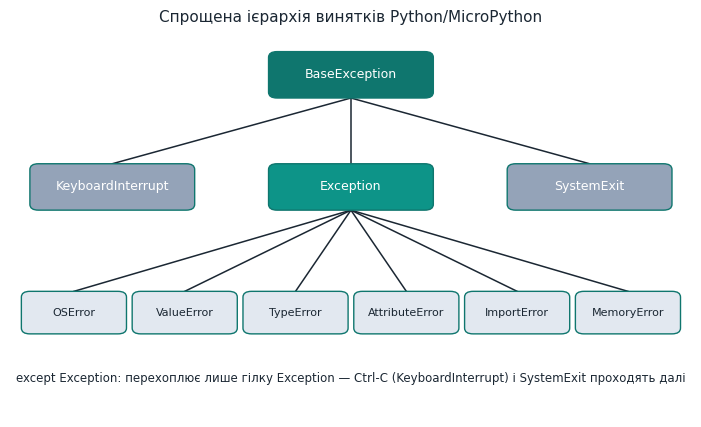

In [37]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

def _block(ax, x, y, w, h, text, color=ACCENT, tcolor="white", fs=9):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                   linewidth=1, edgecolor=ACCENT_DARK, facecolor=color)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=tcolor)

fig, ax = plt.subplots(figsize=(7.8, 4.4))
ax.set_xlim(0, 12); ax.set_ylim(0, 10); ax.axis("off")

def link(x1, y1, x2, y2):
    ax.plot([x1, x2], [y1, y2], color=TEXT, lw=1.1, zorder=0)

_block(ax, 4.6, 8.3, 2.8, 1.1, "BaseException", color=ACCENT_DARK)
mid = [(0.4, "KeyboardInterrupt", "#94A3B8", "white"), (4.6, "Exception", ACCENT, "white"),
       (8.8, "SystemExit", "#94A3B8", "white")]
for x, name, c, tc in mid:
    _block(ax, x, 5.4, 2.8, 1.1, name, color=c, tcolor=tc)
    link(6.0, 8.25, x + 1.4, 6.55)
leaves = ["OSError", "ValueError", "TypeError", "AttributeError", "ImportError", "MemoryError"]
lw_, gap = 1.75, 0.2
x0 = (12 - (len(leaves) * lw_ + (len(leaves) - 1) * gap)) / 2
for i, name in enumerate(leaves):
    x = x0 + i * (lw_ + gap)
    _block(ax, x, 2.2, lw_, 1.0, name, color="#E2E8F0", tcolor=TEXT, fs=8)
    link(6.0, 5.35, x + lw_ / 2, 3.25)
ax.text(6, 0.9, "except Exception: перехоплює лише гілку Exception — Ctrl-C (KeyboardInterrupt) і SystemExit проходять далі",
        ha="center", fontsize=8.5, color=TEXT)
ax.set_title("Спрощена ієрархія винятків Python/MicroPython", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

`KeyboardInterrupt` і `SystemExit` — **сестринські** класи `Exception` під спільним `BaseException`, а не його підкласи. Саме тому `except Exception:` (навіть без уточнення типу) свідомо НЕ перехоплює `Ctrl-C` у REPL — на відміну від голого `except:` без жодного типу, який ловить геть усе, включно з `KeyboardInterrupt`, і тому вважається ще гіршою практикою, ніж `except Exception:` із 18.3.

### 18.8. Алгоритм діагностики «тихого» зависання {-}

Коли пристрій просто перестає відповідати без жодного повідомлення в REPL, корисно діяти за системним алгоритмом, а не навмання:

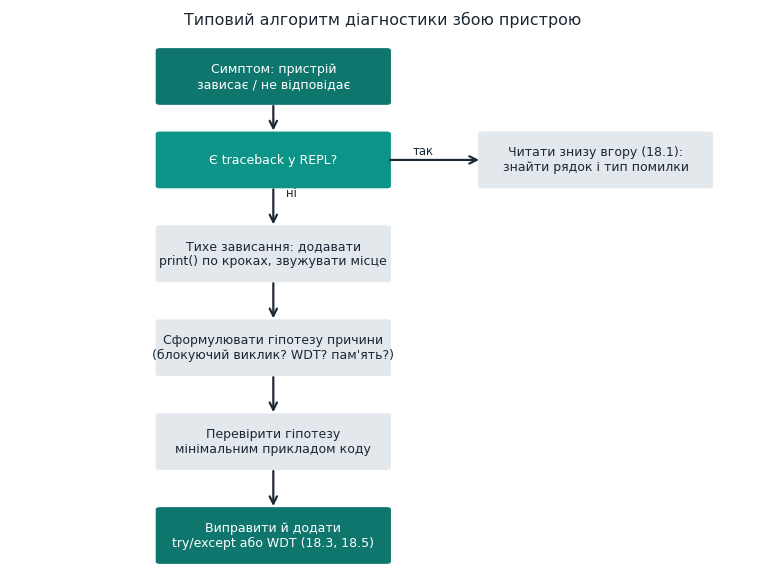

In [38]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

fig, ax = plt.subplots(figsize=(6.5, 5), dpi=120)
def box(x, y, text, color=GRID, tcolor=TEXT, w=2.6, h=1.0):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.06", facecolor=color, edgecolor="white"))
    ax.text(x, y, text, ha="center", va="center", fontsize=7.5, color=tcolor)
box(5, 9.2, "Симптом: пристрій\nзависає / не відповідає", ACCENT_DARK, "white")
box(5, 7.6, "Є traceback у REPL?", ACCENT, "white")
box(8.7, 7.6, "Читати знизу вгору (18.1):\nзнайти рядок і тип помилки", GRID)
box(5, 5.8, "Тихе зависання: додавати\nprint() по кроках, звужувати місце")
box(5, 4.0, "Сформулювати гіпотезу причини\n(блокуючий виклик? WDT? пам'ять?)")
box(5, 2.2, "Перевірити гіпотезу\nмінімальним прикладом коду")
box(5, 0.4, "Виправити й додати\ntry/except або WDT (18.3, 18.5)", ACCENT_DARK, "white")
arrows = [((5,8.7),(5,8.1)), ((6.3,7.6),(7.4,7.6)), ((5,7.1),(5,6.3)),
          ((5,5.3),(5,4.5)), ((5,3.5),(5,2.7)), ((5,1.7),(5,0.9))]
for (x0,y0),(x1,y1) in arrows:
    ax.annotate("", xy=(x1,y1), xytext=(x0,y0), arrowprops=dict(arrowstyle="->", color=TEXT, lw=1.3))
ax.annotate("так", xy=(6.6,7.7), fontsize=7, color=TEXT)
ax.annotate("ні", xy=(5.15,6.9), fontsize=7, color=TEXT)
ax.set_xlim(2, 10.5); ax.set_ylim(-0.3, 10); ax.axis("off")
ax.set_title("Типовий алгоритм діагностики збою пристрою", fontsize=9.5, color=TEXT)
plt.tight_layout()
plt.show()

### 18.9. assert для перевірки припущень під час розробки {-}

```python
def set_pwm_duty(pwm, percent):
    assert 0 <= percent <= 100, "Шпаруватість має бути в межах 0-100%"
    pwm.duty_u16(int(percent / 100 * 65535))
```
`assert` робить неявні припущення явними: замість того, щоб хибне значення `percent` мовчки дало дивний результат ШІМ (Розділ 5.3) десь далі в програмі, воно одразу зупиняє виконання зрозумілим `AssertionError` у місці помилки. Важливо розрізняти призначення: `assert` — для ситуацій «цього не повинно статись, якщо код написаний правильно» (помилка в самому коді), тоді як `try/except` (18.3) — для ситуацій, що можуть легітимно статись у реальному світі навіть у правильно написаному коді (тимчасова недоступність давача чи мережі).

### ❓ Питання для самоперевірки {-}


```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> У якому порядку слід читати traceback MicroPython — згори вниз чи знизу вгору? Чому?</summary>

> **Відповідь:** Знизу вгору: останній рядок — це сама помилка й короткий опис; рядки вище показують, у якій функції та на якому рядку файлу вона сталась, і хто цю функцію викликав.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Чому обробка `except Exception: pass` без розбору вважається поганою практикою?</summary>

> **Відповідь:** Бо вона приховує будь-яку помилку, навіть логічну помилку в самому коді, а не лише ту конкретну очікувану ситуацію, яку варто було б обробити.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Наведіть приклад ситуації, де доречно визначити власний клас винятку, а не використовувати вбудований.</summary>

> **Відповідь:** Наприклад, власний клас `SensorTimeoutError` для ситуації, коли давач не відповів вчасно, — як показано в розділі 18.4: це робить код обробки значно зрозумілішим за призначенням, ніж загальний `OSError` чи `ValueError`.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Яку роль виконує блок `finally` і чим він відрізняється від коду просто після `try/except`?</summary>

> **Відповідь:** Блок `finally` гарантовано виконується незалежно від того, сталася помилка чи ні (зручно для звільнення ресурсів, наприклад закриття з'єднання). Код, розміщений просто після `try/except`, не виконається, якщо необроблений виняток «вилетить» з блоку, — на відміну від `finally`, який виконається і в цьому випадку.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Опишіть, як WDT і `try/except` доповнюють один одного в надійному головному циклі автономного пристрою.</summary>

> **Відповідь:** `try/except` обробляє очікувані відновлювані помилки в межах однієї ітерації (наприклад, `OSError` від давача), щоб одна невдала ітерація не «уронила» весь пристрій. `wdt.feed()` наприкінці циклу захищає від іншого сценарію — повного зависання (наприклад, через помилку в бібліотеці), яке жоден `except` не перехопить, — плата в цьому разі автоматично перезавантажиться.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Чому проста реалізація логування через прапорець `DEBUG` може бути кращим вибором за повноцінну бібліотеку логування на мікроконтролері?</summary>

> **Відповідь:** Бо для MicroPython-проєктів середнього розміру часто достатньо простого підходу, що не захаращує код, тоді як повноцінна бібліотека логування з рівнями важливості розрахована на можливості повноцінних комп'ютерів.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 7.</b> Дайте приклад коду, де DHT-давач (Розділ 11) міг би кинути `OSError`, і покажіть, як коректно цю ситуацію обробити.</summary>

> **Відповідь:** `sensor.measure()` може кинути `OSError`, якщо DHT-давач не встиг відповісти вчасно. Обробка — за зразком розділу 11.5: `try:\n    sensor.measure()\n    t = sensor.temperature()\nexcept OSError as e:\n    print("Помилка зчитування давача:", e)` — так одна невдала спроба зчитування не зупиняє всю програму логера.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 8.</b> Чому `except Exception:` НЕ перехоплює натискання Ctrl-C (`KeyboardInterrupt`), хоча й вважається «широким» перехопленням?</summary>

> **Відповідь:** Тому що `KeyboardInterrupt` — сестринський клас `Exception` під спільним `BaseException`, а не його підклас (Розділ 18.7), тому `except Exception:` свідомо його не перехоплює, залишаючи користувачеві можливість перервати програму.

</details>


```{=latex}
\end{selfcheckbox}
```

```{=latex}
\begin{selfcheckbox}
```

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 9.</b> Чим `assert` відрізняється за призначенням від `try/except` для обробки помилок?</summary>

> **Відповідь:** `assert` перевіряє припущення, які мають виконуватися, якщо код написаний правильно (сигналізує про помилку в самому коді), тоді як `try/except` обробляє очікувані, легітимні ситуації під час роботи (наприклад, тимчасова недоступність давача чи мережі), які можуть статися навіть у правильно написаному коді.

</details>


```{=latex}
\end{selfcheckbox}
```

---

# 📘 Розділ 19. Підсумки курсу, глосарій і рекомендована література

### Після опрацювання розділу ви зможете: {-}
- систематизувати вивчені модулі та інтерфейси в єдину картину
- пов'язати теоретичний матеріал з виконаними лабораторними роботами
- орієнтуватись у ключовій термінології курсу
- знати, куди звертатись за поглибленою й актуальною інформацією

### 19.1. Зведена карта курсу {-}

| Розділ | Тема | Ключовий модуль MicroPython | Пов'язана лабораторна |
|---|---|---|---|
| 1–2 | Вступ, прошивка, REPL, файлова система | `machine`, `os`, `sys` | — |
| 3 | GPIO, переривання, PCNT | `machine.Pin`, `esp32.PCNT` | Лаб. №1 |
| 4 | Час, таймери, WDT, сон | `time`, `machine.Timer`, `machine.WDT` | Лаб. №1, №3 |
| 5 | ADC, DAC, PWM | `machine.ADC`, `machine.DAC`, `machine.PWM` | Лаб. №2 |
| 6 | UART | `machine.UART` | Лаб. №3 |
| 7 | I2C | `machine.I2C`, `machine.SoftI2C` | Лаб. №4 |
| 8 | SPI | `machine.SPI`, `machine.SoftSPI` | Лаб. №4 |
| 9 | I2S / звук | `machine.I2S` | — |
| 10 | RMT, OneWire, NeoPixel, дотик | `onewire`, `neopixel`, `machine.TouchPad` | — |
| 11 | DHT-давачі, зовнішні бібліотеки | `dht` | — |
| 12 | SD-картки | `sdcard`, `os.mount` | — |
| 13 | RTC | `machine.RTC` | — |
| 14 | Wi-Fi, WebREPL | `network`, `urequests`, `webrepl` | — |
| 15 | Регістри, factory reset | `machine.mem32` | — |
| 16 | Асинхронне програмування | `asyncio` | — |
| 17 | Bluetooth Low Energy | `bluetooth` | — |
| 18 | Налагодження, винятки, надійність | `try`/`except`, `machine.WDT` | — |

Цей курс побудовано так, щоб рухатись від найпростішого (один світлодіод, Лаб. №1) до складного пристрою, що поєднує кілька інтерфейсів одночасно (Лаб. №4, Завдання 5) і врешті здатен вийти в мережу (Розділ 14).

### 19.2. Глосарій ключових термінів {-}

| Термін | Пояснення |
|---|---|
| **GPIO** | General-Purpose Input/Output — універсальний пін загального призначення |
| **ADC / DAC** | Аналого-цифровий / цифро-аналоговий перетворювач |
| **PWM (ШІМ)** | Широтно-імпульсна модуляція — цифровий сигнал зі змінною шпаруватістю, що імітує аналоговий рівень |
| **Duty cycle (шпаруватість)** | Частка періоду сигналу, коли він перебуває у «ввімкненому» стані |
| **UART** | Асинхронний послідовний інтерфейс на двох лініях (TX/RX) |
| **Baud rate** | Швидкість передачі даних по UART, біт/с |
| **I2C** | Синхронна шина на двох спільних лініях (SDA/SCL) з адресацією пристроїв |
| **SPI** | Синхронна шина з окремою лінією вибору (CS) для кожного пристрою |
| **REPL** | Read-Eval-Print Loop — інтерактивна консоль виконання коду |
| **Debounce (антидребезг)** | Придушення хибних повторних спрацювань механічного контакту |
| **ISR** | Interrupt Service Routine — обробник апаратного переривання |
| **WDT** | Watchdog Timer — сторожовий таймер, що перезавантажує пристрій при зависанні |
| **Deep sleep** | Режим глибокого енергозбереження з фактичним перезапуском плати при пробудженні |
| **RTC** | Real Time Clock — модуль обліку поточного часу |
| **RMT** | Апаратний блок ESP32 для генерації точних імпульсних послідовностей |
| **WebREPL** | Доступ до REPL плати через Wi-Fi замість USB |
| **MQTT** | Легкий протокол publish/subscribe для IoT поверх TCP, альтернатива HTTP для частих коротких повідомлень |
| **NTP** | Network Time Protocol — протокол синхронізації часу через мережу |
| **Корутина (coroutine)** | Функція, оголошена через `async def`, яку можна призупиняти й відновлювати в циклі подій |
| **Цикл подій (event loop)** | Механізм asyncio, що почергово виконує готові до роботи корутини |
| **GATT** | Generic Attribute Profile — ієрархія сервісів і характеристик, якою BLE-пристрій описує свої дані |
| **BLE** | Bluetooth Low Energy — енергоощадний варіант Bluetooth для коротких періодичних повідомлень |
| **Регістр** | Комірка пам'яті мікроконтролера, кожен біт якої має суворо визначене апаратне значення |
| **Traceback** | Список викликів функцій, що виводить REPL при необробленій помилці, для діагностики її причини |

### 19.3. Рекомендована література та джерела {-}

- Офіційна документація проєкту MicroPython (розділи для ESP32: Tutorial і Quick Reference) — [https://docs.micropython.org/en/latest/esp32/](https://docs.micropython.org/en/latest/esp32/) — основне довідкове джерело з точними сигнатурами класів і функцій, що варто звіряти при написанні реального коду, оскільки деталі API можуть змінюватись між версіями прошивки.
- Технічна документація (Technical Reference Manual) чипа ESP32 від Espressif Systems — для тих, хто хоче зрозуміти апаратні принципи роботи периферії глибше рівня Python-класів (Розділ 15).
- Онлайн-симулятор Wokwi ([https://wokwi.com](https://wokwi.com)) — для практичного відпрацювання схем без фізичної плати, використовувався в усіх лабораторних роботах курсу.
- Репозиторії сторонніх бібліотек-драйверів для конкретних периферійних пристроїв (дисплеї, давачі, RTC-модулі) — зазвичай посилання на них наведені прямо в документації самого пристрою чи в спільноті MicroPython.
- Технічна документація мікросхеми DS3231 від виробника — для тих, хто підключає зовнішній модуль точного часу (Розділ 13.2) і хоче зрозуміти деталі роботи з батарейним резервуванням.
- Специфікація Bluetooth Core від організації Bluetooth SIG — офіційний, значно глибший опис GATT, реклами (advertising) та інших механізмів BLE, ніж потрібно для базового навчального проєкту (Розділ 17).

### 19.4. Куди рухатись далі {-}

Опанувавши матеріал цього курсу, логічними наступними кроками є:

- побудова власного завершеного IoT-проєкту, що поєднує кілька вивчених інтерфейсів (наприклад, метеостанція: DHT-давач → OLED-дисплей → передача даних по Wi-Fi на сервер, з надійним головним циклом за зразком Розділу 18.5);
- поглиблене вивчення енергоефективності для повністю автономних, батарейних пристроїв (комбінація Розділів 4.4, 13 і BLE з Розділу 17, який споживає суттєво менше за Wi-Fi);
- знайомство з найпростішими методами машинного навчання на мікроконтролерах (TinyML) — деякі моделі ESP32-S3 мають апаратний акселератор саме для таких задач;
- перехід від навчальних макетних з'єднань до проєктування власної друкованої плати (PCB) для готового виробу;
- участь у спільноті проєкту MicroPython (баг-репорти, документація, власні бібліотеки-драйвери) як спосіб поглибити розуміння внутрішньої будови мови.

### 19.5. Візуальна карта курсу {-}

Розділи курсу природно групуються в кілька великих етапів — від фундаментальних понять до складніших, комплексних тем:

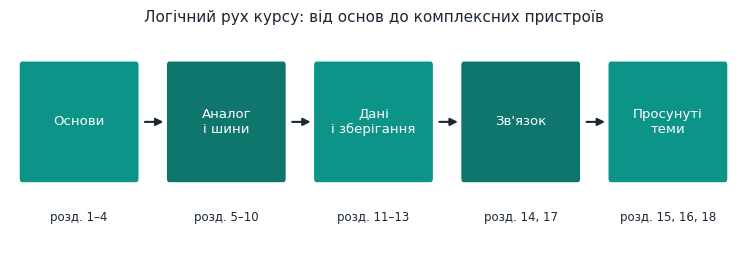

In [39]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({"font.size": 11, "axes.edgecolor": "#33414D", "figure.facecolor": "white", "axes.facecolor": "white"})
ACCENT = "#0d9488"
ACCENT_DARK = "#0f766e"
GRID = "#E3E8ED"
TEXT = "#1B2733"

from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(7.6, 2.8))
stages = [
    ("Основи", "розд. 1–4", ACCENT),
    ("Аналог\nі шини", "розд. 5–10", ACCENT_DARK),
    ("Дані\nі зберігання", "розд. 11–13", ACCENT),
    ("Зв'язок", "розд. 14, 17", ACCENT_DARK),
    ("Просунуті\nтеми", "розд. 15, 16, 18", ACCENT),
]
w, gap = 1.9, 0.55
for i, (name, chs, color) in enumerate(stages):
    x = 0.2 + i * (w + gap)
    ax.add_patch(FancyBboxPatch((x, 1.4), w, 1.3, boxstyle="round,pad=0.05", facecolor=color, edgecolor="white"))
    ax.text(x + w / 2, 2.05, name, ha="center", va="center", color="white", fontsize=9.5)
    ax.text(x + w / 2, 0.95, chs, ha="center", va="center", color=TEXT, fontsize=8.5)
    if i:
        ax.annotate("", xy=(x - 0.05, 2.05), xytext=(x - gap + 0.1, 2.05),
                    arrowprops=dict(arrowstyle="-|>", color=TEXT, lw=1.5))
ax.set_xlim(0, 0.2 + len(stages) * (w + gap) - gap + 0.2); ax.set_ylim(0.5, 3.1); ax.axis("off")
ax.set_title("Логічний рух курсу: від основ до комплексних пристроїв", fontsize=11, color=TEXT)
plt.tight_layout()
plt.show()

Ця послідовність відображена і в лабораторних роботах: Лаб. №1 спирається лише на етап «Основи», тоді як фінальне завдання Лабораторної №4 (Розділ 19.1) поєднує кілька інтерфейсів з різних етапів одночасно.

### 🎓 Підсумкові питання для самоперевірки {-}
1. Побудуйте власну таблицю відповідності «інтерфейс → типова задача» на основі матеріалу всього курсу (без підглядання в Розділ 19.1).
2. Поясніть своїми словами, чим апаратна реалізація інтерфейсу (I2C, SPI, PWM) відрізняється від програмної (SoftI2C, SoftSPI, «ручний» PWM через Pin) і коли варто обирати кожну.
3. Опишіть, які саме теми з цього курсу застосовувались у кожній з чотирьох лабораторних робіт.
4. Запропонуйте власну ідею комплексного проєкту, що поєднує щонайменше три різні інтерфейси з різних розділів курсу, і опишіть роль кожного.
5. Які теми курсу здались вам найскладнішими для розуміння і чому? Сформулюйте конкретне питання для викладача.
6. Спроєктуйте (на рівні опису, без повного коду) пристрій, що поєднує asyncio (Розділ 16), BLE (Розділ 17) і надійний головний цикл з обробкою винятків (Розділ 18).
7. Порівняйте BLE (Розділ 17) і Wi-Fi (Розділ 14) за енергоспоживанням і поясніть, який з них ви обрали б для батарейного давача, що працює роками без заміни батареї.
8. Оцініть, скільки з 18 розділів курсу ви могли б впевнено пояснити студенту молодшого курсу без підготовки — і складіть для себе короткий план повторення слабких тем.

---

## Кінець курсу {-}


> Матеріал цього посібника разом із лабораторними роботами №1–4 формує завершений вступний курс з програмування мікроконтролерів на MicroPython — від першого блимання світлодіодом до пристрою, що читає давачі, показує дані на екрані й спілкується по мережі.